# <a id='toc1_'></a>[Análisis Exporatorio de Datos (EDA)](#toc0_)

**Table of contents**<a id='toc0_'></a>    
- [Análisis Exporatorio de Datos (EDA)](#toc1_)    
  - [Dataset](#toc1_1_)    
    - [Missing Values](#toc1_1_1_)    
      - [`year`](#toc1_1_1_1_)    
      - [`productDisplayName`](#toc1_1_1_2_)    
      - [`baseColour`](#toc1_1_1_3_)    
      - [`season`](#toc1_1_1_4_)    
      - [`usage`](#toc1_1_1_5_)    
  - [Consistencia imagen-metadata](#toc1_2_)    
    - [Análisis visual de las imagenes](#toc1_2_1_)    
    - [Comprobaciones cuantitativas](#toc1_2_2_)    
    - [Duplicados](#toc1_2_3_)    
  - [Análisis Univariante: Distribución de las variables](#toc1_3_)    
    - [Variables de baja cardinalidad](#toc1_3_1_)    
    - [Variables de cardinalidad alta](#toc1_3_2_)    
    - [Desbalance de clases](#toc1_3_3_)    
  - [Análisis Bivariante](#toc1_4_)    
    - [Análisis Género vs. Categoría principal ($P(masterCategory∣gender)$)](#toc1_4_1_)    
    - [Análisis Género vs. Tipo de artículo ($P(articleType∣gender)$)](#toc1_4_2_)    
    - [Análisis Categoría principal vs. Uso ($P(masterCategory|usage)$)](#toc1_4_3_)    
    - [Análisis Temporada vs. Uso ($P(season|usage)$)](#toc1_4_4_)    
    - [Análisis Uso vs. Tipo de Articulo ($P(usage|articleType)$)](#toc1_4_5_)    
    - [Análisis Color base vs. Categoría principal ($P(baseColour|masterCategory)$)](#toc1_4_6_)    
    - [Análisis Temporada vs. Color ($P(baseColour∣season)$)](#toc1_4_7_)    
  - [Jerarquía entre `masterCategory`, `subCategory` y `articleType`](#toc1_5_)    
    - [`masterCategory x subcategory`](#toc1_5_1_)    
    - [`subCategory x articleType`](#toc1_5_2_)    

<!-- vscode-jupyter-toc-config
	numbering=false
	anchor=true
	flat=false
	minLevel=1
	maxLevel=6
	/vscode-jupyter-toc-config -->
<!-- THIS CELL WILL BE REPLACED ON TOC UPDATE. DO NOT WRITE YOUR TEXT IN THIS CELL -->

In [66]:
# Importar librerias
import os
from pathlib import Path

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
plt.style.use('seaborn-v0_8-whitegrid')

In [ ]:
from fashion_mlops.utils.visualizations import (
    show_images,
    analyze_high_cardinality,
    variable_conflicts,
    plot_heatmap_correlation,
    plot_stacked_bars_correlation,
    plot_stacked_percentage,
)

# Si falla:
# ❯ uv sync --reinstall
# Comprobar:
# ❯ uv run python -c "import fashion_mlops; print(fashion_mlops.__file__)"
# Reiniciar kernel

In [68]:
sns.set_theme(
    style="whitegrid",
    palette="viridis",
    context="notebook"
)

## <a id='toc1_1_'></a>[Dataset](#toc0_)

El dataset [Fashion Product Images Small](http://kaggle.com/datasets/paramaggarwal/fashion-product-images-small) contiene principalmente:

- Imágenes de productos de moda.
- Un fichero styles.csv con metadatos.

| Variable           | Descripción                       |
| ------------------ | --------------------------------- |
| id                 | Identificador único coincidente con el nombre de la imagen |
| gender             | Género del artículo: Men, Women, Unisex, ...           |
| masterCategory     | Categoría principal: Apparel, Accessories, Footwear... |
| subCategory        | Categoría secundaría: Topwear, Shoes, Watches...        |
| articleType        | Tipo de artículo: T-Shirts, Shirts, Jeans...        |
| baseColour         | Color principal                   |
| season             | Estación: Summer, Winter...                 |
| year               | Año                               |
| usage              | Uso: Casual, Sports, Formal...         |
| productDisplayName | Nombre comercial                  |

Cada producto se identifica mediante un ID como 42431. Encontrarás un mapa de todos los productos en styles.csv. Desde aquí, puedes obtener la imagen la carpeta:
```
images/
├── 10000.jpg
├── 10001.jpg
```
donde el nombre coincide con el id.

In [69]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("paramaggarwal/fashion-product-images-small")

print("Path to dataset files:", path)

Path to dataset files: /Users/larayc/.cache/kagglehub/datasets/paramaggarwal/fashion-product-images-small/versions/1


In [70]:
print(os.listdir(path))

['.DS_Store', 'images', 'styles.csv', 'myntradataset']


In [71]:
df = pd.read_csv(f"{path}/styles.csv", on_bad_lines="skip")
df

,id,gender,masterCategory,subCategory,articleType,baseColour,season,year,usage,productDisplayName
0,15970,Men,Apparel,Topwear,Shirts,Navy Blue,Fall,2011.0,Casual,Turtle Check Men Navy Blue Shirt
1,39386,Men,Apparel,Bottomwear,Jeans,Blue,Summer,2012.0,Casual,Peter England Men Party Blue Jeans
2,59263,Women,Accessories,Watches,Watches,Silver,Winter,2016.0,Casual,Titan Women Silver Watch
3,21379,Men,Apparel,Bottomwear,Track Pants,Black,Fall,2011.0,Casual,Manchester United Men Solid Black Track Pants
4,53759,Men,Apparel,Topwear,Tshirts,Grey,Summer,2012.0,Casual,Puma Men Grey T-shirt
...,...,...,...,...,...,...,...,...,...,...
44419,17036,Men,Footwear,Shoes,Casual Shoes,White,Summer,2013.0,Casual,Gas Men Caddy Casual Shoe
44420,6461,Men,Footwear,Flip Flops,Flip Flops,Red,Summer,2011.0,Casual,Lotto Men's Soccer Track Flip Flop
44421,18842,Men,Apparel,Topwear,Tshirts,Blue,Fall,2011.0,Casual,Puma Men Graphic Stellar Blue Tshirt
44422,46694,Women,Personal Care,Fragrance,Perfume and Body Mist,Blue,Spring,2017.0,Casual,Rasasi Women Blue Lady Perfume


In [72]:
print(f"Tamaño del conjunto de datos: {df.shape[0]}")
print(f"Número de variables: {df.shape[1]}")

Tamaño del conjunto de datos: 44424
Número de variables: 10


In [73]:
df.duplicated().any()

np.False_

No hay registros duplicados en el dataset.

In [74]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 44424 entries, 0 to 44423
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   id                  44424 non-null  int64  
 1   gender              44424 non-null  str    
 2   masterCategory      44424 non-null  str    
 3   subCategory         44424 non-null  str    
 4   articleType         44424 non-null  str    
 5   baseColour          44409 non-null  str    
 6   season              44403 non-null  str    
 7   year                44423 non-null  float64
 8   usage               44107 non-null  str    
 9   productDisplayName  44417 non-null  str    
dtypes: float64(1), int64(1), str(8)
memory usage: 3.4 MB


In [75]:
# Convertimos la columna 'year' a tipo entero
df['year'] = df['year'].astype("Int64")
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 44424 entries, 0 to 44423
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype
---  ------              --------------  -----
 0   id                  44424 non-null  int64
 1   gender              44424 non-null  str  
 2   masterCategory      44424 non-null  str  
 3   subCategory         44424 non-null  str  
 4   articleType         44424 non-null  str  
 5   baseColour          44409 non-null  str  
 6   season              44403 non-null  str  
 7   year                44423 non-null  Int64
 8   usage               44107 non-null  str  
 9   productDisplayName  44417 non-null  str  
dtypes: Int64(1), int64(1), str(8)
memory usage: 3.4 MB


In [76]:
feature_summary = pd.DataFrame({
    "Feature": df.columns,
    "Data Type": df.dtypes.astype(str),
    "Unique Values": df.nunique().values,
    "Null Values": df.isna().sum().values,
    "Missing (%)": (df.isna().mean() * 100).round(2)
}).reset_index(drop=True)

feature_summary.sort_values(by="Null Values", ascending=False)

,Feature,Data Type,Unique Values,Null Values,Missing (%)
8,usage,str,8,317,0.71
6,season,str,4,21,0.05
5,baseColour,str,46,15,0.03
9,productDisplayName,str,31121,7,0.02
7,year,Int64,13,1,0.00
0,id,int64,44424,0,0.00
1,gender,str,5,0,0.00
2,masterCategory,str,7,0,0.00
3,subCategory,str,45,0,0.00
4,articleType,str,143,0,0.00


### <a id='toc1_1_1_'></a>[Missing Values](#toc0_)

Tenemos mas de 44000 productos y 10 atributos descriptivos. Observamos que hay valores nulos en las columnas `usage`, `season`, `baseColour`, `productDisplayName` y un solo uno en `year`. Veamos como tratarlos de menos a más.

#### <a id='toc1_1_1_1_'></a>[`year`](#toc0_)
Como solo tenemos un nulo en `year`, vamos a suponer que esa prenda corresponde al año 2019 por ser el año más reciente del dataset.

In [77]:
df["year"].value_counts(dropna=False).sort_index()

year
2007        2
2008        7
2009       20
2010      846
2011    13672
2012    16288
2013     1212
2014      236
2015     2780
2016     6006
2017     2916
2018      405
2019       33
<NA>        1
Name: count, dtype: Int64

In [78]:
df[df['year'].isnull()]

,id,gender,masterCategory,subCategory,articleType,baseColour,season,year,usage,productDisplayName
21272,53781,Men,Apparel,Topwear,Tshirts,Blue,NaN,<NA>,Sports,Puma Men Blue Sless Round Neck T-shirt


In [79]:
df["year"] = df["year"].fillna(2019)

#### <a id='toc1_1_1_2_'></a>[`productDisplayName`](#toc0_)

In [80]:
df[df['productDisplayName'].isnull()]

,id,gender,masterCategory,subCategory,articleType,baseColour,season,year,usage,productDisplayName
3677,42878,Women,Accessories,Bags,Clutches,Maroon,Summer,2012,Casual,NaN
14291,30991,Women,Personal Care,Fragrance,Perfume and Body Mist,NaN,Spring,2017,NaN,NaN
17639,45687,Men,Personal Care,Fragrance,Perfume and Body Mist,NaN,Spring,2017,NaN,NaN
22089,42863,Women,Accessories,Bags,Clutches,Brown,Summer,2012,Casual,NaN
23484,45698,Women,Personal Care,Fragrance,Perfume and Body Mist,NaN,Spring,2017,NaN,NaN
37531,30992,Men,Personal Care,Fragrance,Perfume and Body Mist,NaN,Spring,2017,NaN,NaN
40675,43119,Men,Personal Care,Fragrance,Perfume and Body Mist,NaN,Spring,2017,NaN,NaN


Al ser solo 7 registros, podríamos intentar imputar los valores nulos rellenandolos a mano. Visualizamos las imagenes de estos casos:

In [81]:
ids_pdn = df[df['productDisplayName'].isnull()]['id'].to_list()
ids_pdn

[42878, 30991, 45687, 42863, 45698, 30992, 43119]

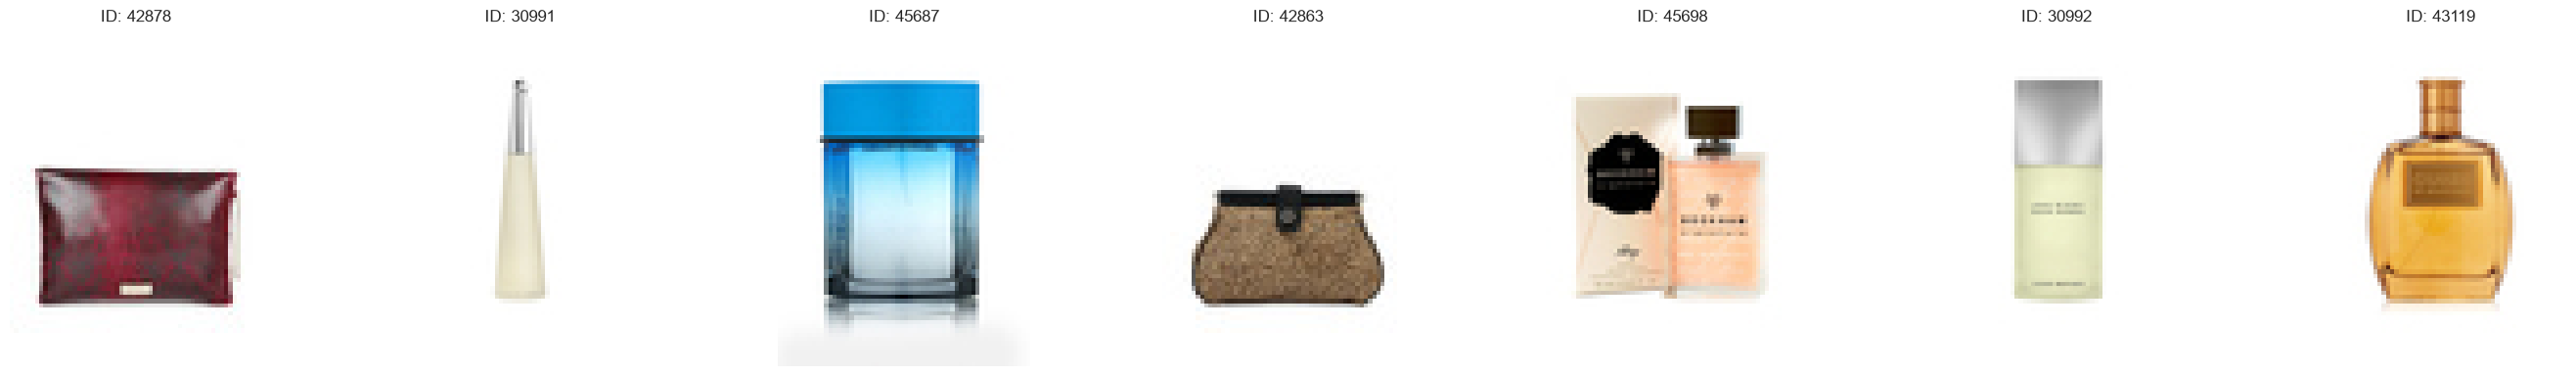

In [82]:
show_images(ids=ids_pdn, image_dir=f"{path}/images", n_cols=7)

* **ID: 42878** 
    
    Al buscar la imagen en internet, encontramos le bolso en: http://kmchandbags.com/products/the-wristlet-cherry

In [83]:
df.loc[df["id"] == 42878, "productDisplayName"] = "KM Chandbags WomenCherry Wristlet Clutch"

* **ID: 42863**

    Siguiendo con bolsos, encontramos este en: http://dba.dk/recommerce/forsale/item/9573370 de la marca French Connection

In [84]:
df.loc[df["id"] == 42863, "productDisplayName"] = "French Connection Women Leopard Print Clutch"

* **ID: 30991**
    
    Se trata de este perfume: https://www.isseymiyakeparfums.com/es/issey-miyake-l-eau-d-issey-eau-de-toilette-EI_EDT.html

In [85]:
df.loc[df["id"] == 30991, "productDisplayName"] = "Issey Miyake Women Leau Eau De Toilette 100 ml"
df.loc[df["id"] == 30991, "baseColour"] = "Cream"
df.loc[df["id"] == 30991, "usage"] = "Casual"

* **ID: 30992**

    

In [86]:
df.loc[df["id"] == 30992, "productDisplayName"] = "Issey Miyake Men Leau Eau De Toilette 75 ml"
df.loc[df["id"] == 30992, "baseColour"] = "White"
df.loc[df["id"] == 30992, "usage"] = "Casual"

* **ID: 45687**

    Se trata de esta colonia: http://perfumesregalo.com/articulo/tous-man-sport-edt-vapo-100-ml/

In [87]:
df.loc[df["id"] == 45687, "productDisplayName"] = "Tous Man Sport Eau de Toilette"
df.loc[df["id"] == 45687, "baseColour"] = "Blue"
df.loc[df["id"] == 45687, "usage"] = "Sports"

* **ID: 45698**

    Se trata de este perfume: https://perfumeplanet.com.pa/products/david-beckham-signature-story-edt

In [88]:
df.loc[df["id"] == 45698, "productDisplayName"] = "David Beckham Women Signature Eau De Toilette 75 ml"
df.loc[df["id"] == 45698, "baseColour"] = "Pink"
df.loc[df["id"] == 45698, "usage"] = "Casual"

* **ID: 43119**

    Se trata: https://www.notino.es/guess/by-marciano-for-men-eau-de-toilette-para-hombre/

In [89]:
df.loc[df["id"] == 43119, "productDisplayName"] = "Guess Marciano Men Eau de Toilette 100ml"
df.loc[df["id"] == 43119, "baseColour"] = "Gold"
df.loc[df["id"] == 43119, "usage"] = "Casual"

#### <a id='toc1_1_1_3_'></a>[`baseColour`](#toc0_)

Quedan 10 valores nulos en `baseColour`, vamos a añadirlos manualmente

In [90]:
df[df['baseColour'].isnull()]

,id,gender,masterCategory,subCategory,articleType,baseColour,season,year,usage,productDisplayName
6206,11293,Men,Apparel,Bottomwear,Jeans,NaN,Fall,2016,Casual,Wrangler Men Blue Texas Jeans
9516,41347,Men,Apparel,Bottomwear,Jeans,NaN,Fall,2016,Casual,Wrangler Men Black Texas Jeans
12763,11288,Men,Apparel,Bottomwear,Jeans,NaN,Fall,2016,Casual,Wrangler Men Blue Texas Jeans
15526,57698,Women,Personal Care,Skin,Face Moisturisers,NaN,Spring,2017,Casual,Lotus Herbals Quincenourish Quince Seed Nouris...
15708,41355,Men,Apparel,Bottomwear,Jeans,NaN,Fall,2016,Casual,Wrangler Men Blue Millard Jeans
17268,43122,Men,Personal Care,Fragrance,Perfume and Body Mist,NaN,Spring,2017,NaN,GUESS Man Eau De Toilette 75 ml
20209,11309,Men,Apparel,Bottomwear,Jeans,NaN,Fall,2016,Casual,Wrangler Men Blue Floyd Jeans
34553,41357,Men,Apparel,Bottomwear,Jeans,NaN,Fall,2016,Casual,Wrangler Men Blue Millard Jeans
43260,43116,Women,Personal Care,Fragrance,Perfume and Body Mist,NaN,Spring,2017,NaN,GUESS Seductive Women EDT Spray
44224,43120,Men,Personal Care,Fragrance,Perfume and Body Mist,NaN,Spring,2017,NaN,GUESS by Marciano Men Eau De Toilette 50 ml


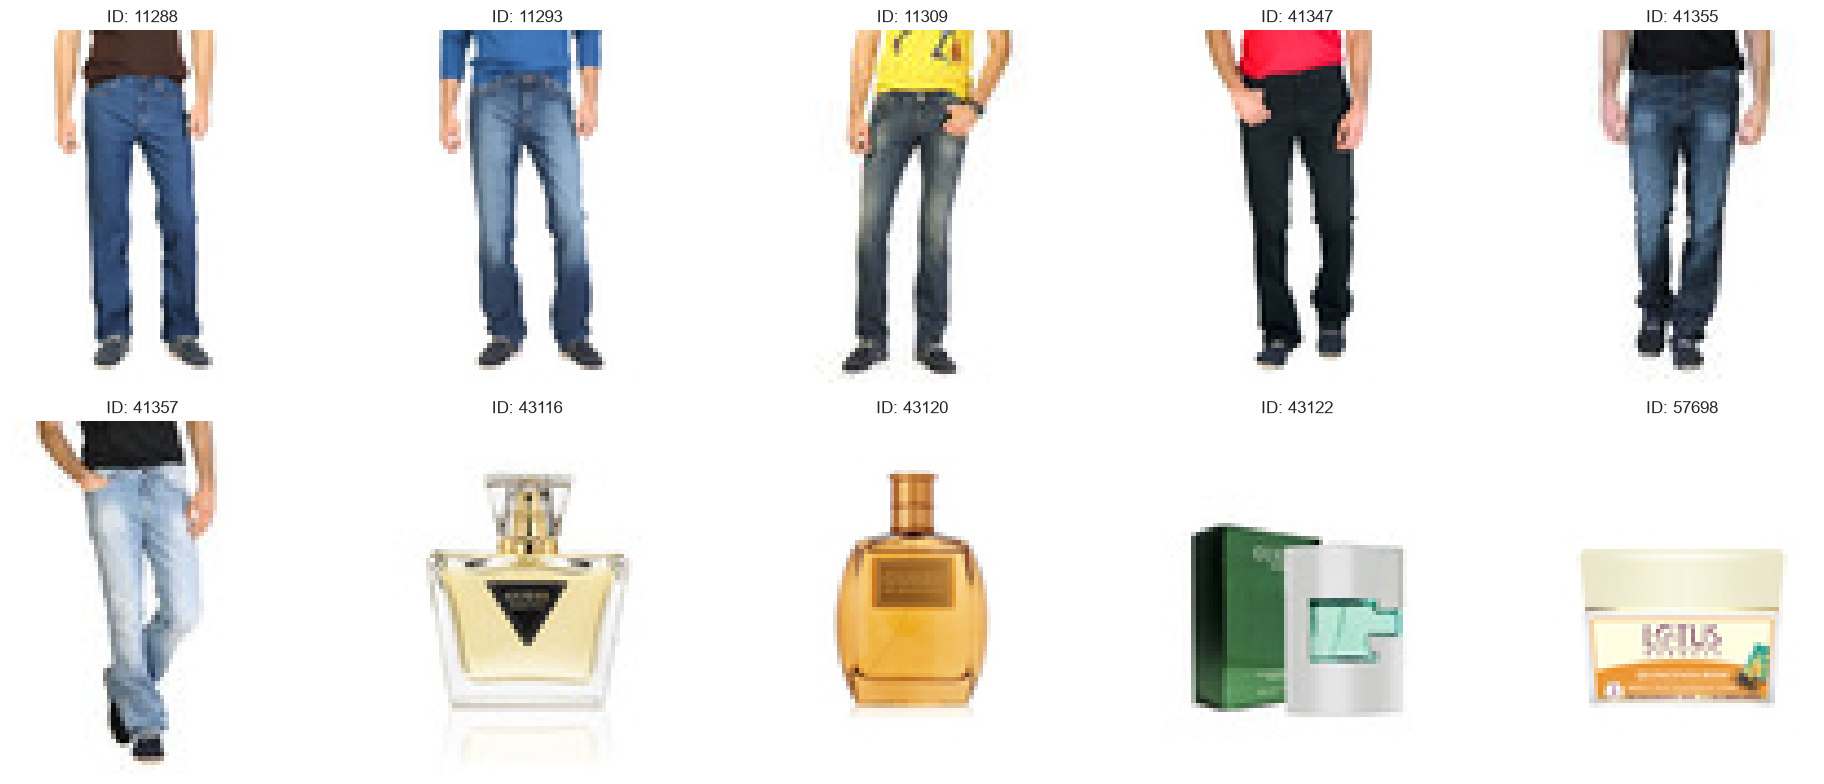

In [91]:
ids_bc = df[df['baseColour'].isnull()]['id'].sort_values().to_list()
show_images(ids=ids_bc, image_dir=f"{path}/images")

In [92]:
df.loc[df["id"] == ids_bc[0], "baseColour"] = "Blue"
df.loc[df["id"] == ids_bc[1], "baseColour"] = "Blue"
df.loc[df["id"] == ids_bc[2], "baseColour"] = "Gray"
df.loc[df["id"] == ids_bc[3], "baseColour"] = "Black"
df.loc[df["id"] == ids_bc[4], "baseColour"] = "Blue"
df.loc[df["id"] == ids_bc[5], "baseColour"] = "Blue"
df.loc[df["id"] == ids_bc[6], "baseColour"] = "Gold"
df.loc[df["id"] == ids_bc[7], "baseColour"] = "Gold"
df.loc[df["id"] == ids_bc[8], "baseColour"] = "Green"
df.loc[df["id"] == ids_bc[9], "baseColour"] = "White"

In [93]:
df.loc[df["id"] == ids_bc[6], "usage"] = "Casual"
df.loc[df["id"] == ids_bc[7], "usage"] = "Casual"
df.loc[df["id"] == ids_bc[8], "usage"] = "Casual"

Aprovechamos para rellenar los 3 `usage` que faltan

#### <a id='toc1_1_1_4_'></a>[`season`](#toc0_)

In [94]:
df[df['season'].isnull()]

,id,gender,masterCategory,subCategory,articleType,baseColour,season,year,usage,productDisplayName
282,5402,Women,Footwear,Shoes,Sports Shoes,Purple,NaN,2011,Sports,Kalenji Ekiden 200 Wn Purple 2011
5997,5389,Unisex,Footwear,Shoes,Sports Shoes,Yellow,NaN,2011,Sports,Kalenji Kapteren 200 Yellow Fw
6510,5380,Women,Footwear,Shoes,Sports Shoes,Purple,NaN,2011,Sports,Quechua Forclaz 100 Lady Purple
12658,5392,Unisex,Footwear,Shoes,Sports Shoes,White,NaN,2011,Sports,Kalenji Crossport 100 Whi/champ
12994,5361,Men,Footwear,Shoes,Sports Shoes,Black,NaN,2011,Sports,Kipsta F300 Fg Sr Ah09
13523,5368,Men,Footwear,Shoes,Sports Shoes,Red,NaN,2011,Sports,Kalenji Kiprun 1000 White Red Ss10
16042,5360,Women,Footwear,Shoes,Sports Shoes,Grey,NaN,2011,Sports,Kalenji Kapteren 100 Blue/grey
21272,53781,Men,Apparel,Topwear,Tshirts,Blue,NaN,2019,Sports,Puma Men Blue Sless Round Neck T-shirt
23835,5406,Women,Footwear,Shoes,Sports Shoes,Blue,NaN,2011,Sports,Kalenji Ekiden Blue Scratch 2011
24198,5401,Women,Footwear,Shoes,Sports Shoes,Blue,NaN,2011,Sports,Kalenji Ekiden 100 Lady Blue 2011


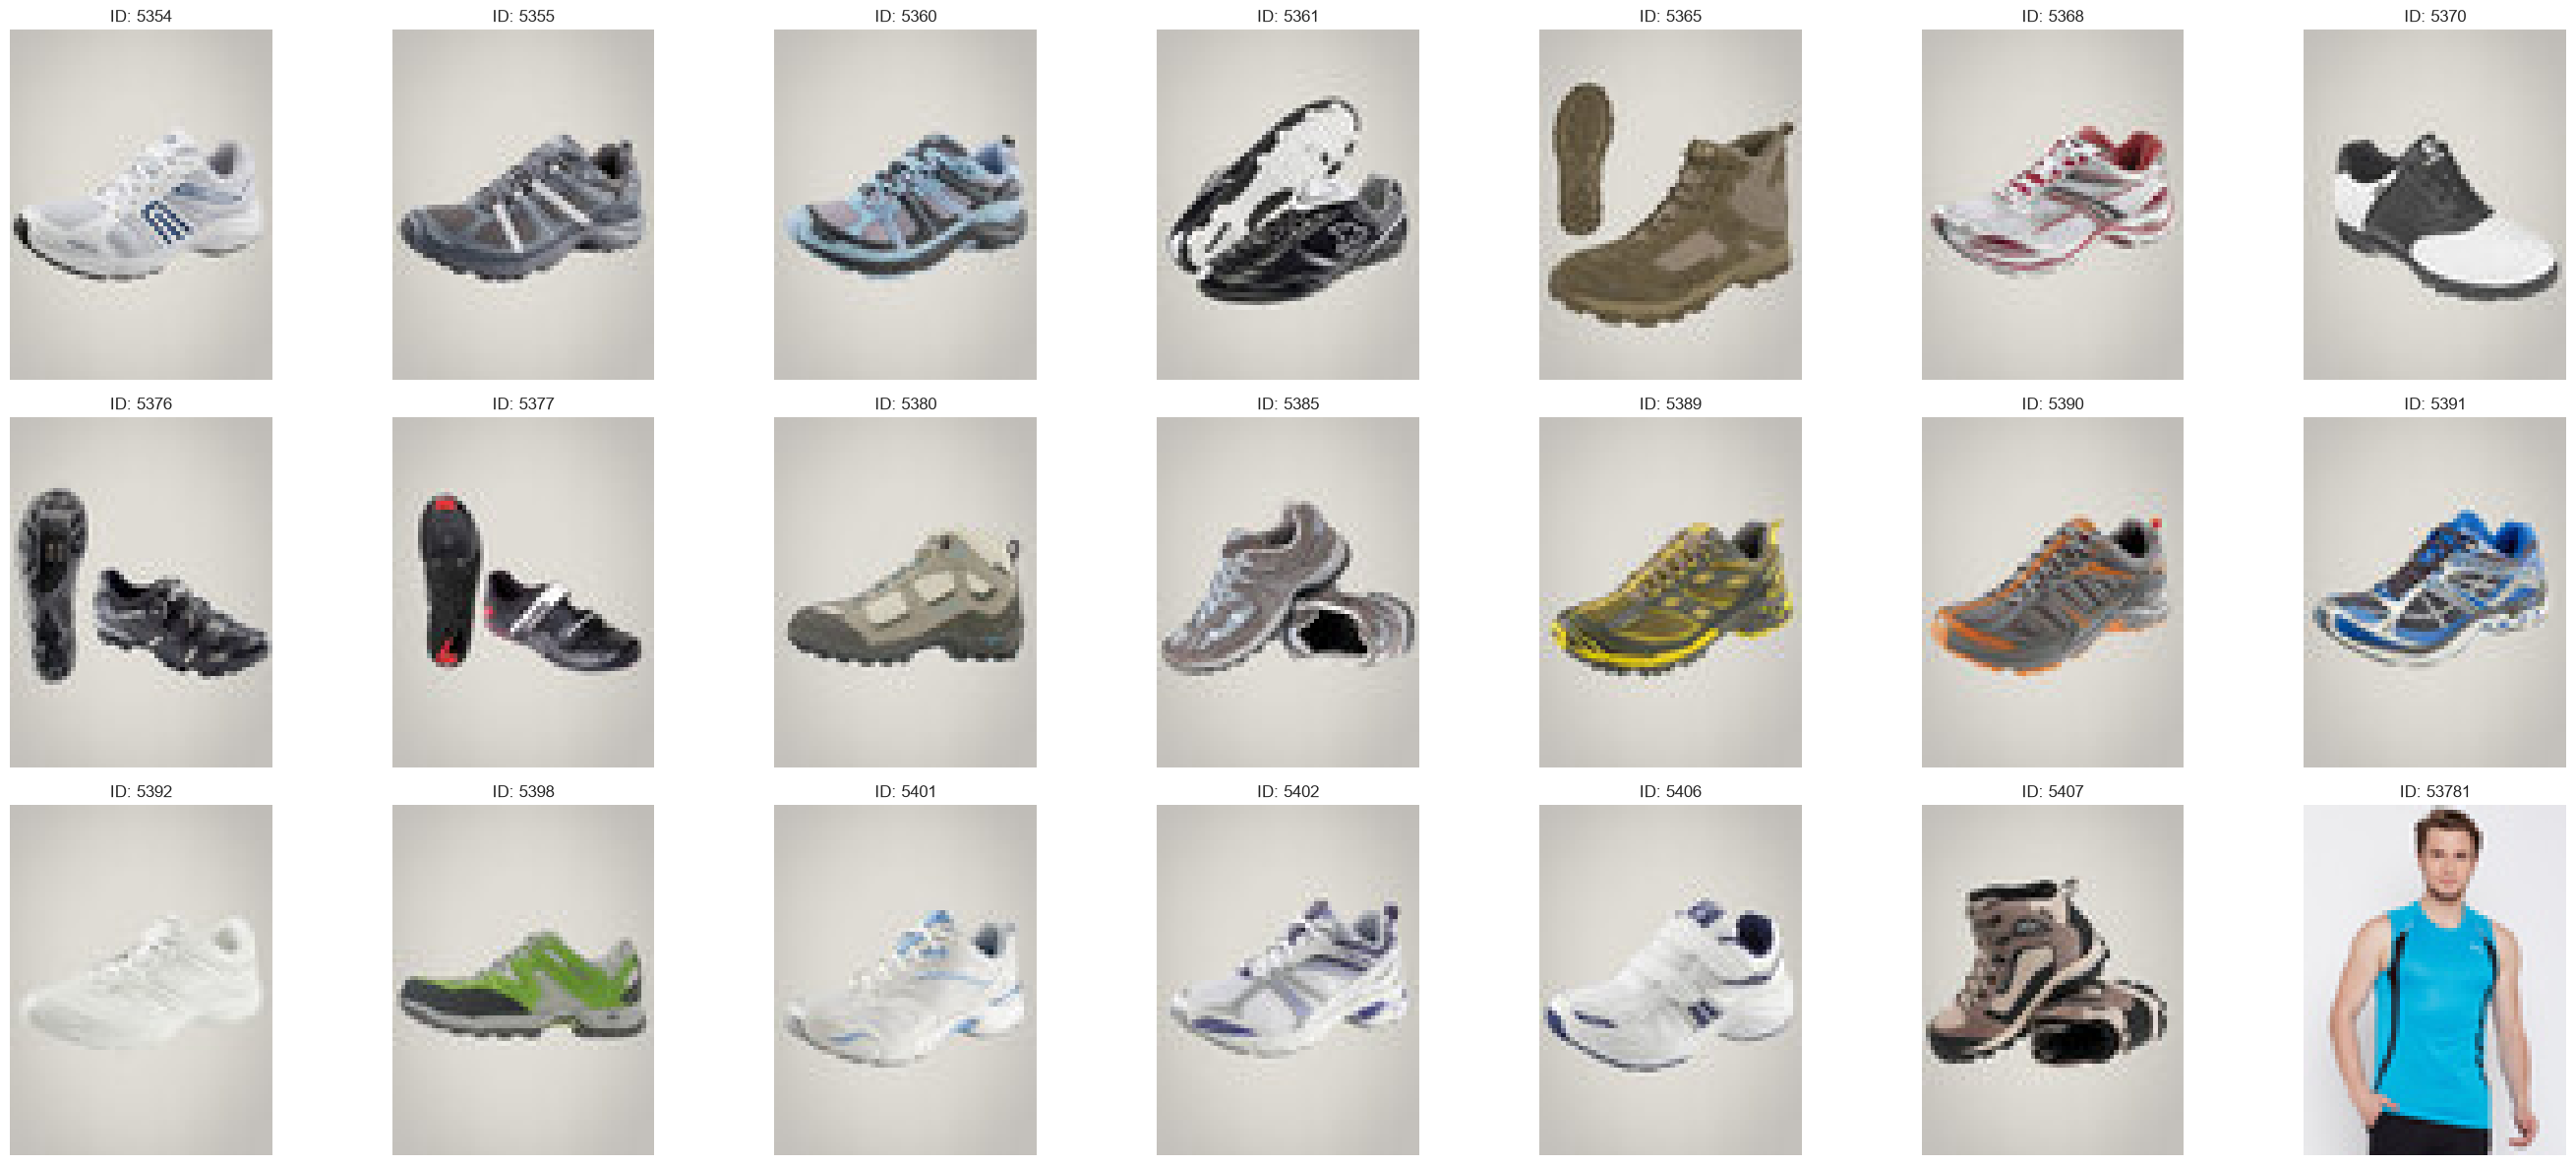

In [95]:
ids_s = df[df['season'].isnull()]['id'].sort_values().to_list()
show_images(ids=ids_s, image_dir=f"{path}/images", n_cols=7)

Observamos que todos son articulos deportivos, comprobamos que `season`se atribuye a este tipo de articulos:

In [96]:
df[(df['usage'] == "Sports") & (df['articleType'] == "Sports Shoes")]['season'].value_counts(dropna=False)
df[(df['usage'] == "Sports") & (df['articleType'] == "Tshirts")]['season'].value_counts(dropna=False)

season
Fall      489
Summer    453
Winter      7
Spring      5
NaN         1
Name: count, dtype: int64

Para determinar la temporada (season) de cada artículo, podemos analizar la columna `productDisplayName` los códigos de las colecciones de marcas como Kalenji, Kipsta o Quechua (marcas de Decathlon) que aparecen al final de su nombre comercial:
- Siglas comerciales: Se descifraron códigos del nombre como Ah/Fw (Otoño-Invierno $\rightarrow$ Winter/Fall) y Ss (Primavera-Verano $\rightarrow$ Spring/Summer).
- Tipo de producto: Prendas de tirantes o calzado con rejilla ventilada se asignaron a Summer.
- Materiales: Modelos impermeables (Novadry), cerrados o botas altas se asignaron a Winter o Fall.

In [97]:
# Asignación de la temporada para cada ID utilizando la sintaxis requerida
df.loc[df["id"] == ids_s[0], "season"] = "Winter"   # 5354 (Kalenji Ekiden 09 - fin de año)
df.loc[df["id"] == ids_s[1], "season"] = "Summer"   # 5355 (Kapteren trail verano)
df.loc[df["id"] == ids_s[2], "season"] = "Summer"   # 5360 (Kapteren trail verano)
df.loc[df["id"] == ids_s[3], "season"] = "Winter"   # 5361 (Ah09 -> Automne-Hiver / Winter)
df.loc[df["id"] == ids_s[4], "season"] = "Summer"   # 5365 (Namib 200 - línea desierto/calor)
df.loc[df["id"] == ids_s[5], "season"] = "Spring"   # 5368 (Ss10 -> Spring-Summer)
df.loc[df["id"] == ids_s[6], "season"] = "Spring"   # 5370 (Zapatos de golf de temporada abierta)
df.loc[df["id"] == ids_s[7], "season"] = "Winter"   # 5376 (Zapatilla rígida e impermeable MTB)
df.loc[df["id"] == ids_s[8], "season"] = "Winter"   # 5377 (Zapatilla rígida carretera)
df.loc[df["id"] == ids_s[9], "season"] = "Summer"   # 5380 (Quechua Forclaz Lady)
df.loc[df["id"] == ids_s[10], "season"] = "Summer"  # 5385 (Arpenaz Flex ligera)
df.loc[df["id"] == ids_s[11], "season"] = "Winter"  # 5389 (Fw -> Fall-Winter)
df.loc[df["id"] == ids_s[12], "season"] = "Summer"  # 5390 (Kapteren trail verano)
df.loc[df["id"] == ids_s[13], "season"] = "Winter"  # 5391 (Ah10 -> Automne-Hiver / Winter)
df.loc[df["id"] == ids_s[14], "season"] = "Summer"  # 5392 (Crossport ventilada)
df.loc[df["id"] == ids_s[15], "season"] = "Fall"    # 5398 (Arpenaz Novadry - membrana impermeable de otoño)
df.loc[df["id"] == ids_s[16], "season"] = "Spring"  # 5401 (Ekiden Lady)
df.loc[df["id"] == ids_s[17], "season"] = "Spring"  # 5402 (Ekiden Wn)
df.loc[df["id"] == ids_s[18], "season"] = "Spring"  # 5406 (Ekiden Scratch velcro)
df.loc[df["id"] == ids_s[19], "season"] = "Winter"  # 5407 (Forclaz 500 bota alta e invernal)
df.loc[df["id"] == ids_s[20], "season"] = "Summer"  # 53781 (Camiseta de tirantes Puma)

#### <a id='toc1_1_1_5_'></a>[`usage`](#toc0_)

Nos quedan 309 nulos en esta columna: 

In [98]:
df[df['usage'].isnull()]


,id,gender,masterCategory,subCategory,articleType,baseColour,season,year,usage,productDisplayName
87,56489,Women,Personal Care,Nails,Nail Polish,Bronze,Spring,2017,NaN,Streetwear Ash Nail Polish # 31
92,52029,Unisex,Apparel,Topwear,Rain Jacket,Coffee Brown,Summer,2012,NaN,Just Natural Unisex Charcoal Rain Jacket
292,55001,Women,Personal Care,Lips,Lipstick,Pink,Spring,2017,NaN,Lakme Absolute Lip Last Day Kiss Lip Colour
479,57563,Women,Personal Care,Lips,Lipstick,Brown,Spring,2017,NaN,Lotus Herbals Pure Colours Nutty Brown Lipstic...
511,55006,Women,Personal Care,Lips,Lip Gloss,Copper,Spring,2017,NaN,Lakme Sheer Satin Lip Gloss 51
...,...,...,...,...,...,...,...,...,...,...
43568,51044,Women,Apparel,Loungewear and Nightwear,Baby Dolls,Navy Blue,Summer,2017,NaN,Enamor Women Navy Blue Baby Doll Nightdress
43633,56605,Women,Personal Care,Makeup,Kajal and Eyeliner,Black,Spring,2017,NaN,Streetwear Black Eye Liner 01
44079,57715,Women,Personal Care,Lips,Lip Gloss,Red,Spring,2017,NaN,Lotus Herbals Seduction Sappy Watermelon Lip G...
44227,55045,Women,Personal Care,Lips,Lipstick,Purple,Spring,2017,NaN,Lakme Enrich Satins Lipstick 461


In [99]:
ids_u = df[df['usage'].isnull()]['id'].sort_values().to_list()
# show_images(ids=ids_u, image_dir=f"{path}/images", n_cols=10, figsize=(20, 40))

In [100]:
df['usage'].value_counts(normalize=True, dropna=False).mul(100).round(2)

usage
Casual          77.46
Sports           9.06
Ethnic           7.22
Formal           5.28
NaN              0.70
Smart Casual     0.15
Party            0.07
Travel           0.06
Home             0.00
Name: proportion, dtype: float64

Al representar menos del 1% del dataset, la estrategia más robusta es imputar con la categoría dominante, que en este caso es Casual (77.46%). Asignar los registros nulos a esta clase minimiza el impacto en la varianza del modelo y refleja la tendencia real de catalogación manual en la industria.

In [101]:
# Imputación de 'usage' basada en la moda del catálogo 
# Se elige 'Casual' para mantener la distribución original y el sesgo natural
# Evitamos eliminar registros para no perder información visual valiosa para la CNN
df['usage'] = df['usage'].fillna('Casual')

## <a id='toc1_2_'></a>[Consistencia imagen-metadata](#toc0_)

Creamos una columna que indica si existe o no la imagen asociada al articulo:

In [102]:
image_dir = Path(f"{path}/images").resolve()

df["image_exists"] = df["id"].apply(lambda x: (image_dir / f"{x}.jpg").is_file())

In [103]:
df["image_exists"].value_counts()

image_exists
True     44419
False        5
Name: count, dtype: int64

In [104]:
df[df['image_exists'] == False]

,id,gender,masterCategory,subCategory,articleType,baseColour,season,year,usage,productDisplayName,image_exists
6695,39403,Men,Apparel,Topwear,Shirts,Black,Summer,2014,Casual,U.S. Polo Assn. Men Black Tailored Fit Casual ...,False
16194,39410,Men,Apparel,Topwear,Shirts,Cream,Summer,2014,Casual,U.S. Polo Assn. Men Cream-Coloured Tailored Fi...,False
32309,39401,Men,Apparel,Bottomwear,Jeans,Blue,Winter,2016,Casual,U.S. Polo Assn. Denim Co. Men Blue Slim Straig...,False
36381,39425,Men,Apparel,Topwear,Tshirts,Red,Spring,2013,Casual,U.S. Polo Assn. Men Red Polo T-Shirt,False
40000,12347,Men,Apparel,Topwear,Suits,Red,Winter,2010,Casual,Fastrack Men Red Manhattan Regular Fit Solid F...,False


Dado que el objetivo final es entrenar una Red Neuronal Convolucional (CNN) que aprenda de las imágenes. Un registro que solo tiene metadatos (texto) pero carece de la señal visual (imagen) no puede aportar nada al entrenamiento del modelo y, de hecho, causaría errores en el pipeline de carga de datos (data loader) durante el entrenamiento. Por este motivo eliminamos los 5 registros sin imagen asociada.

In [105]:
# Eliminamos registros donde image_exists es False
df = df[df['image_exists'] == True].copy()

# Eliminamos la columna auxiliar que ya no es necesaria
df.drop(columns=['image_exists'], inplace=True)

print(f"Dataset final tras limpieza de consistencia: {df.shape} registros")

Dataset final tras limpieza de consistencia: (44419, 10) registros


### <a id='toc1_2_1_'></a>[Análisis visual de las imagenes](#toc0_)

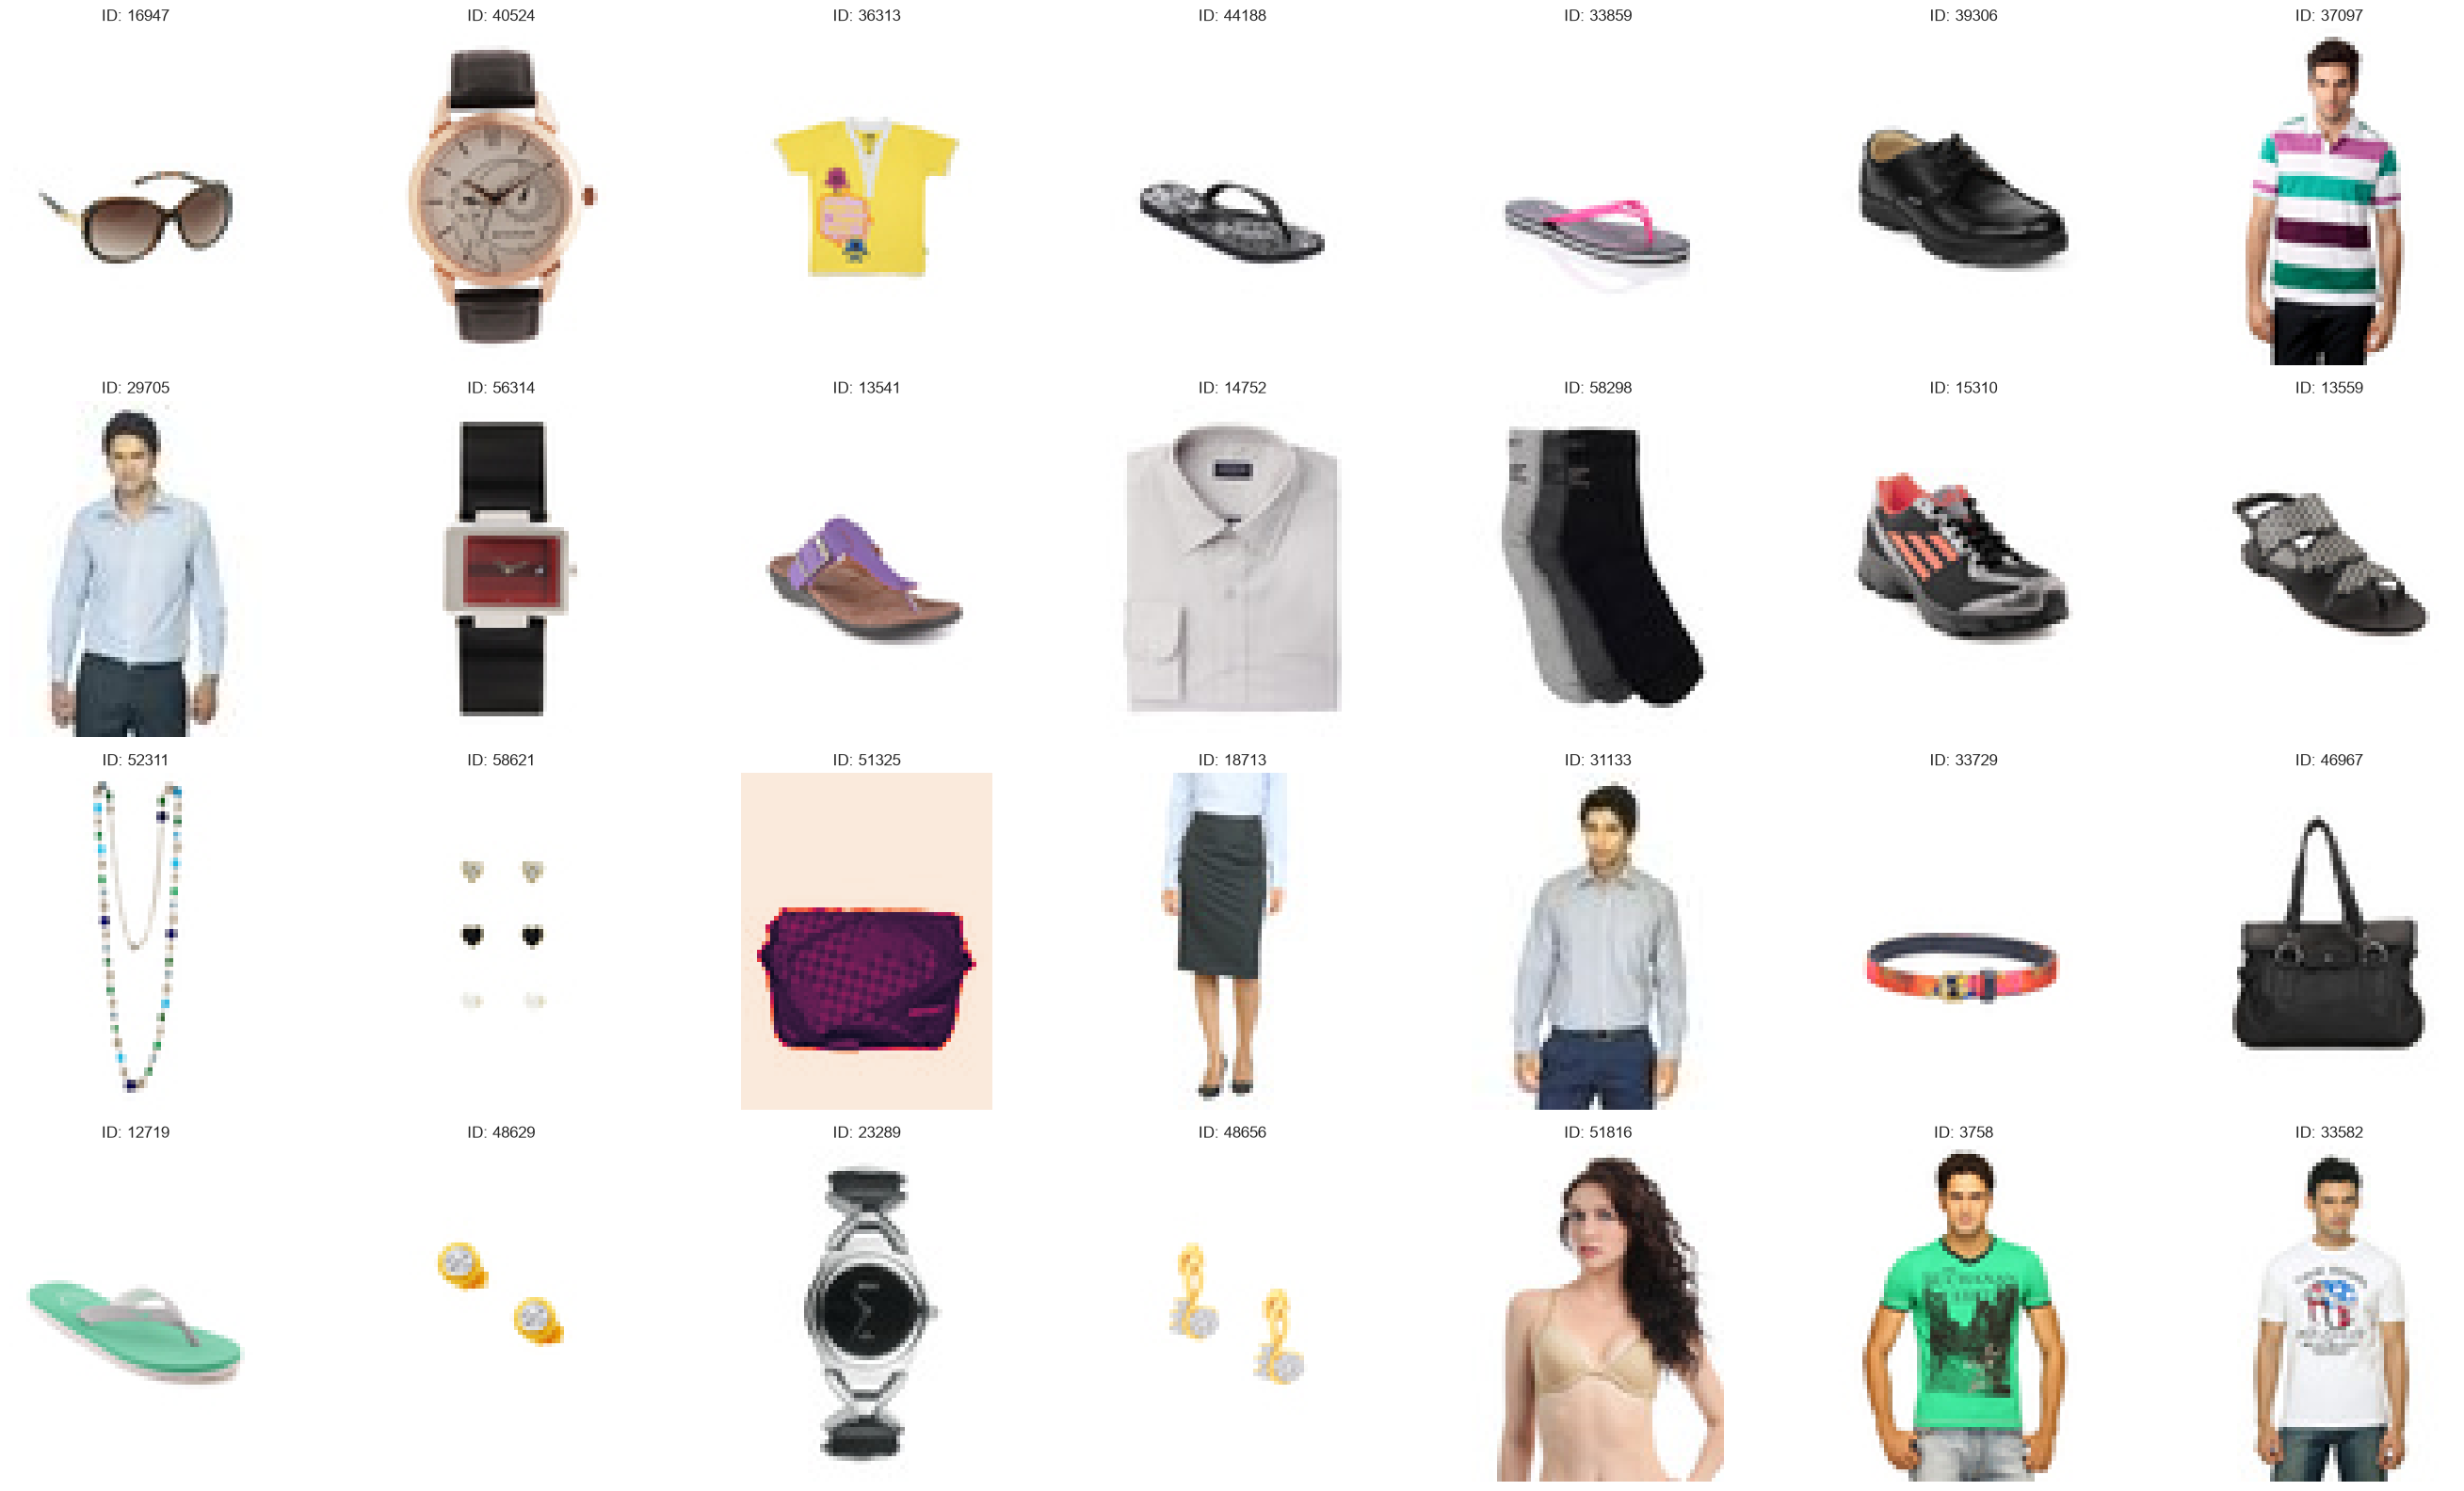

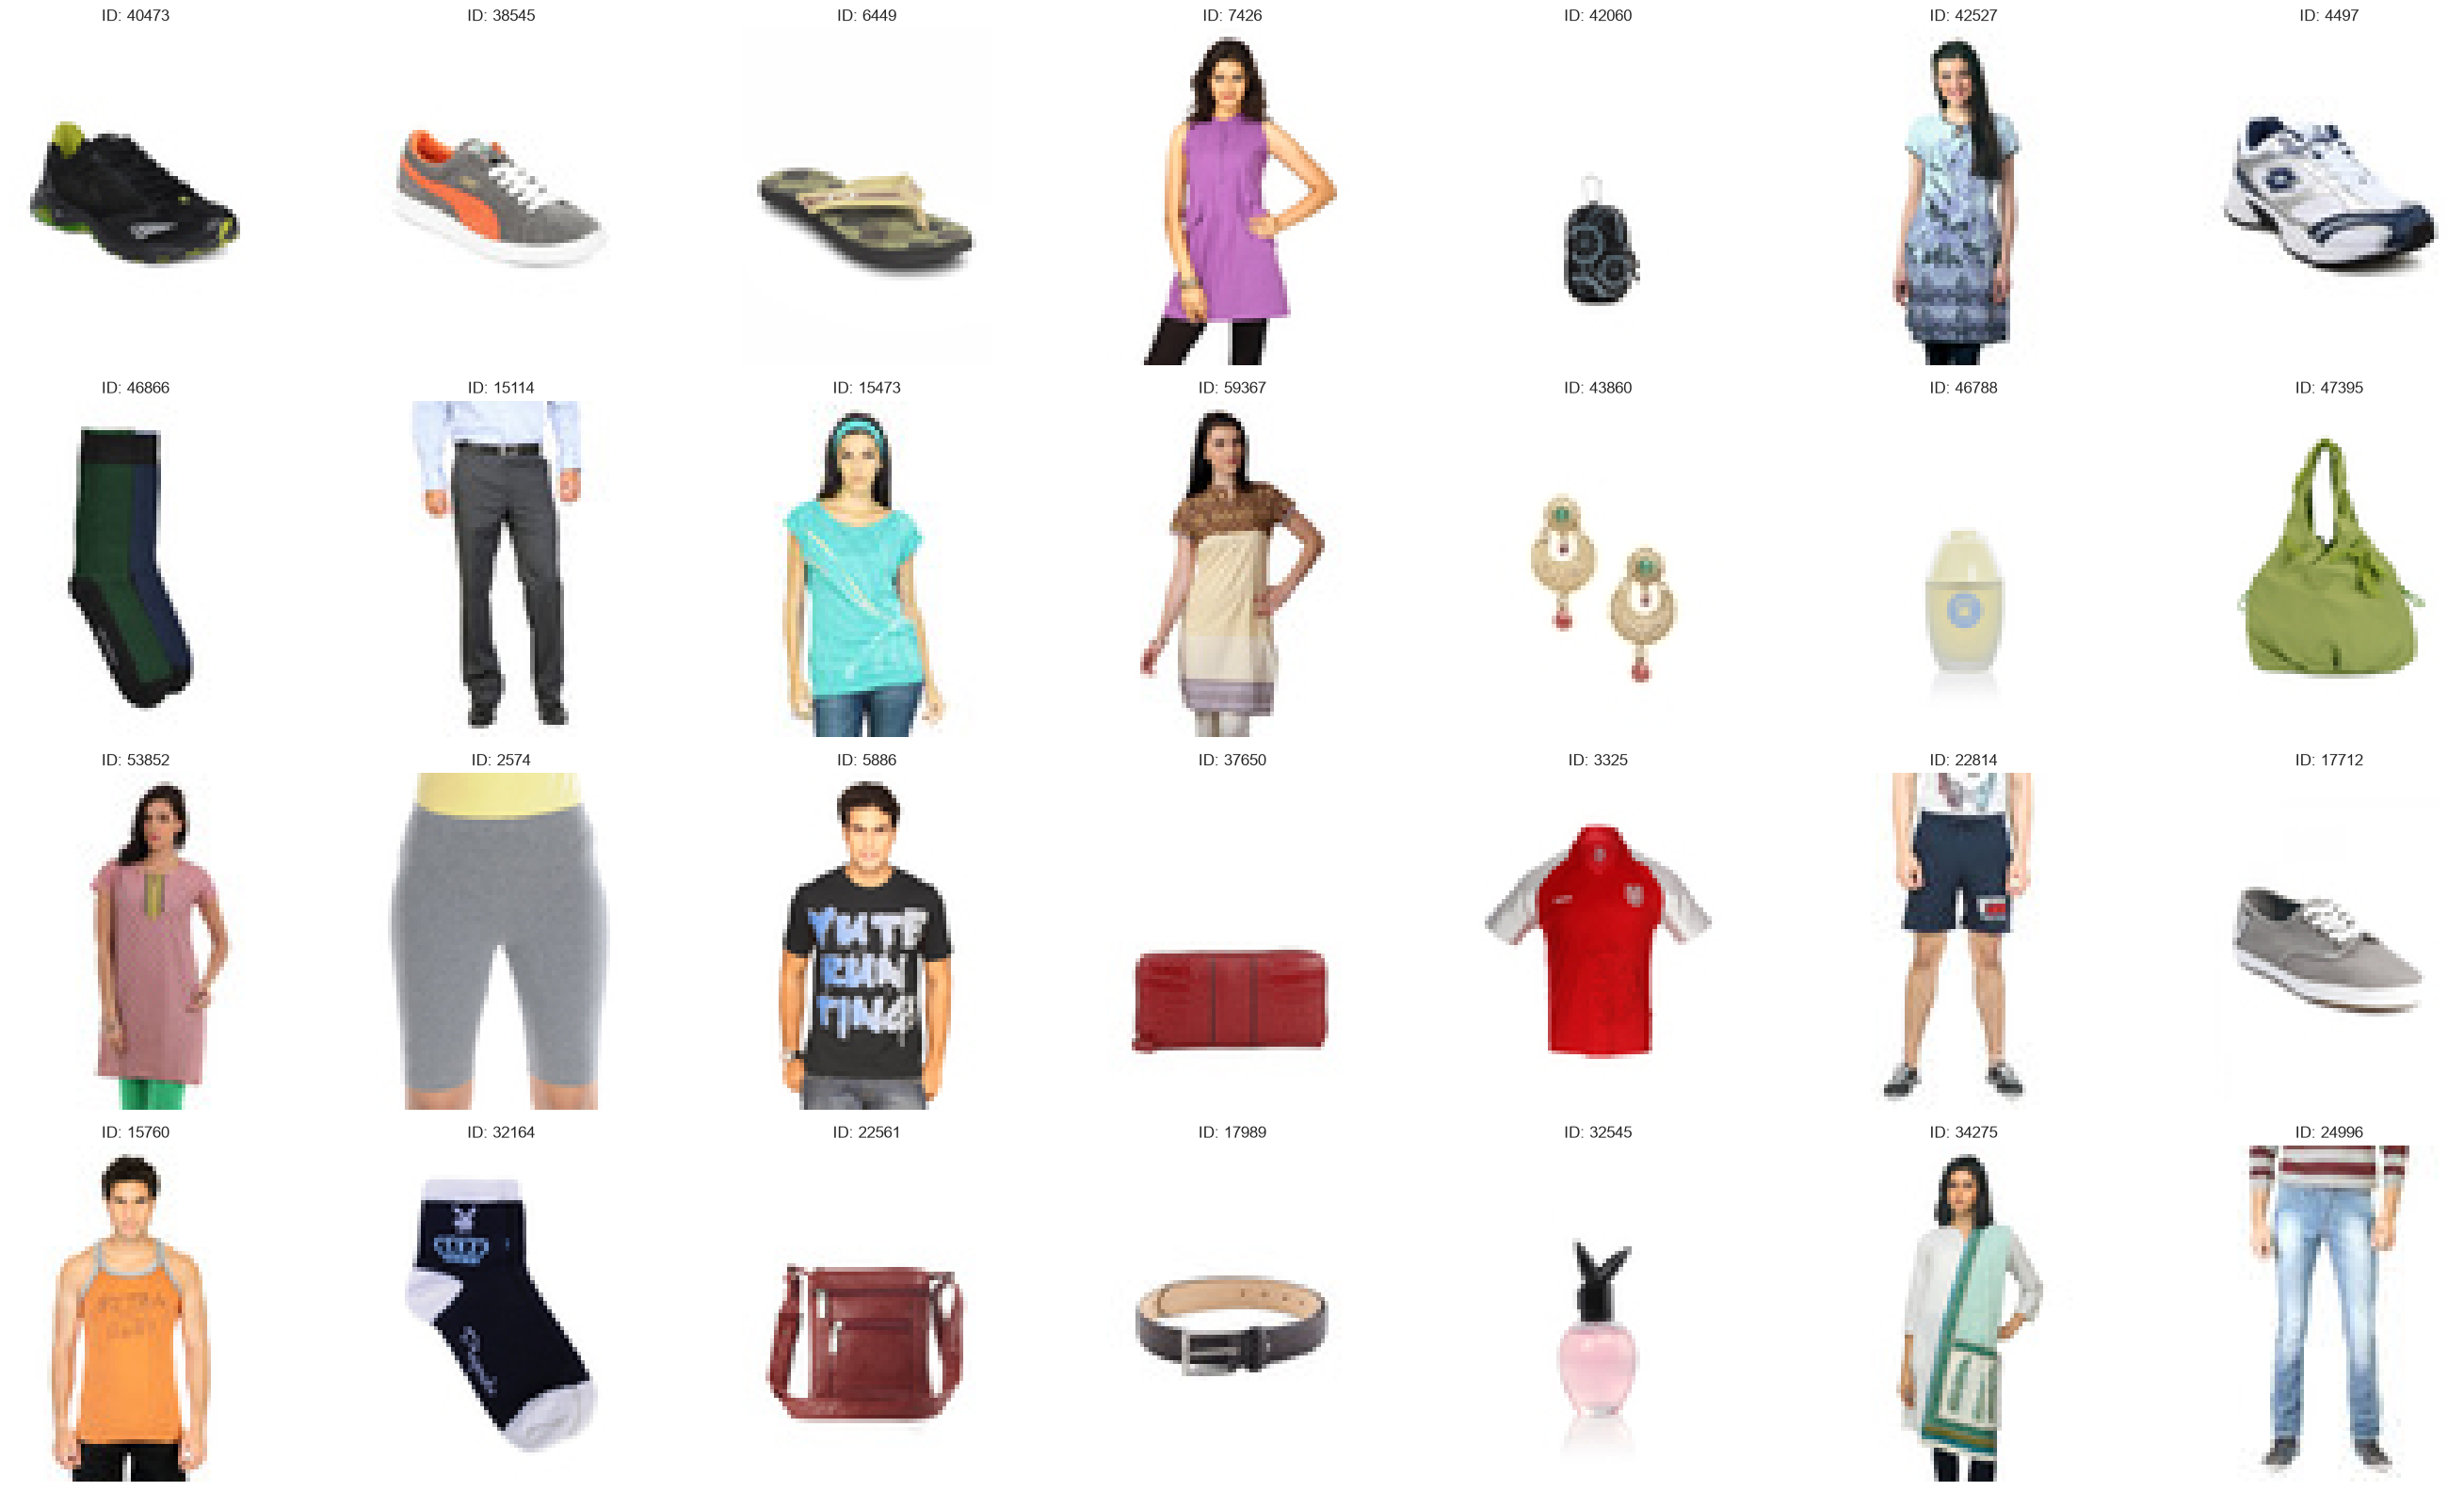

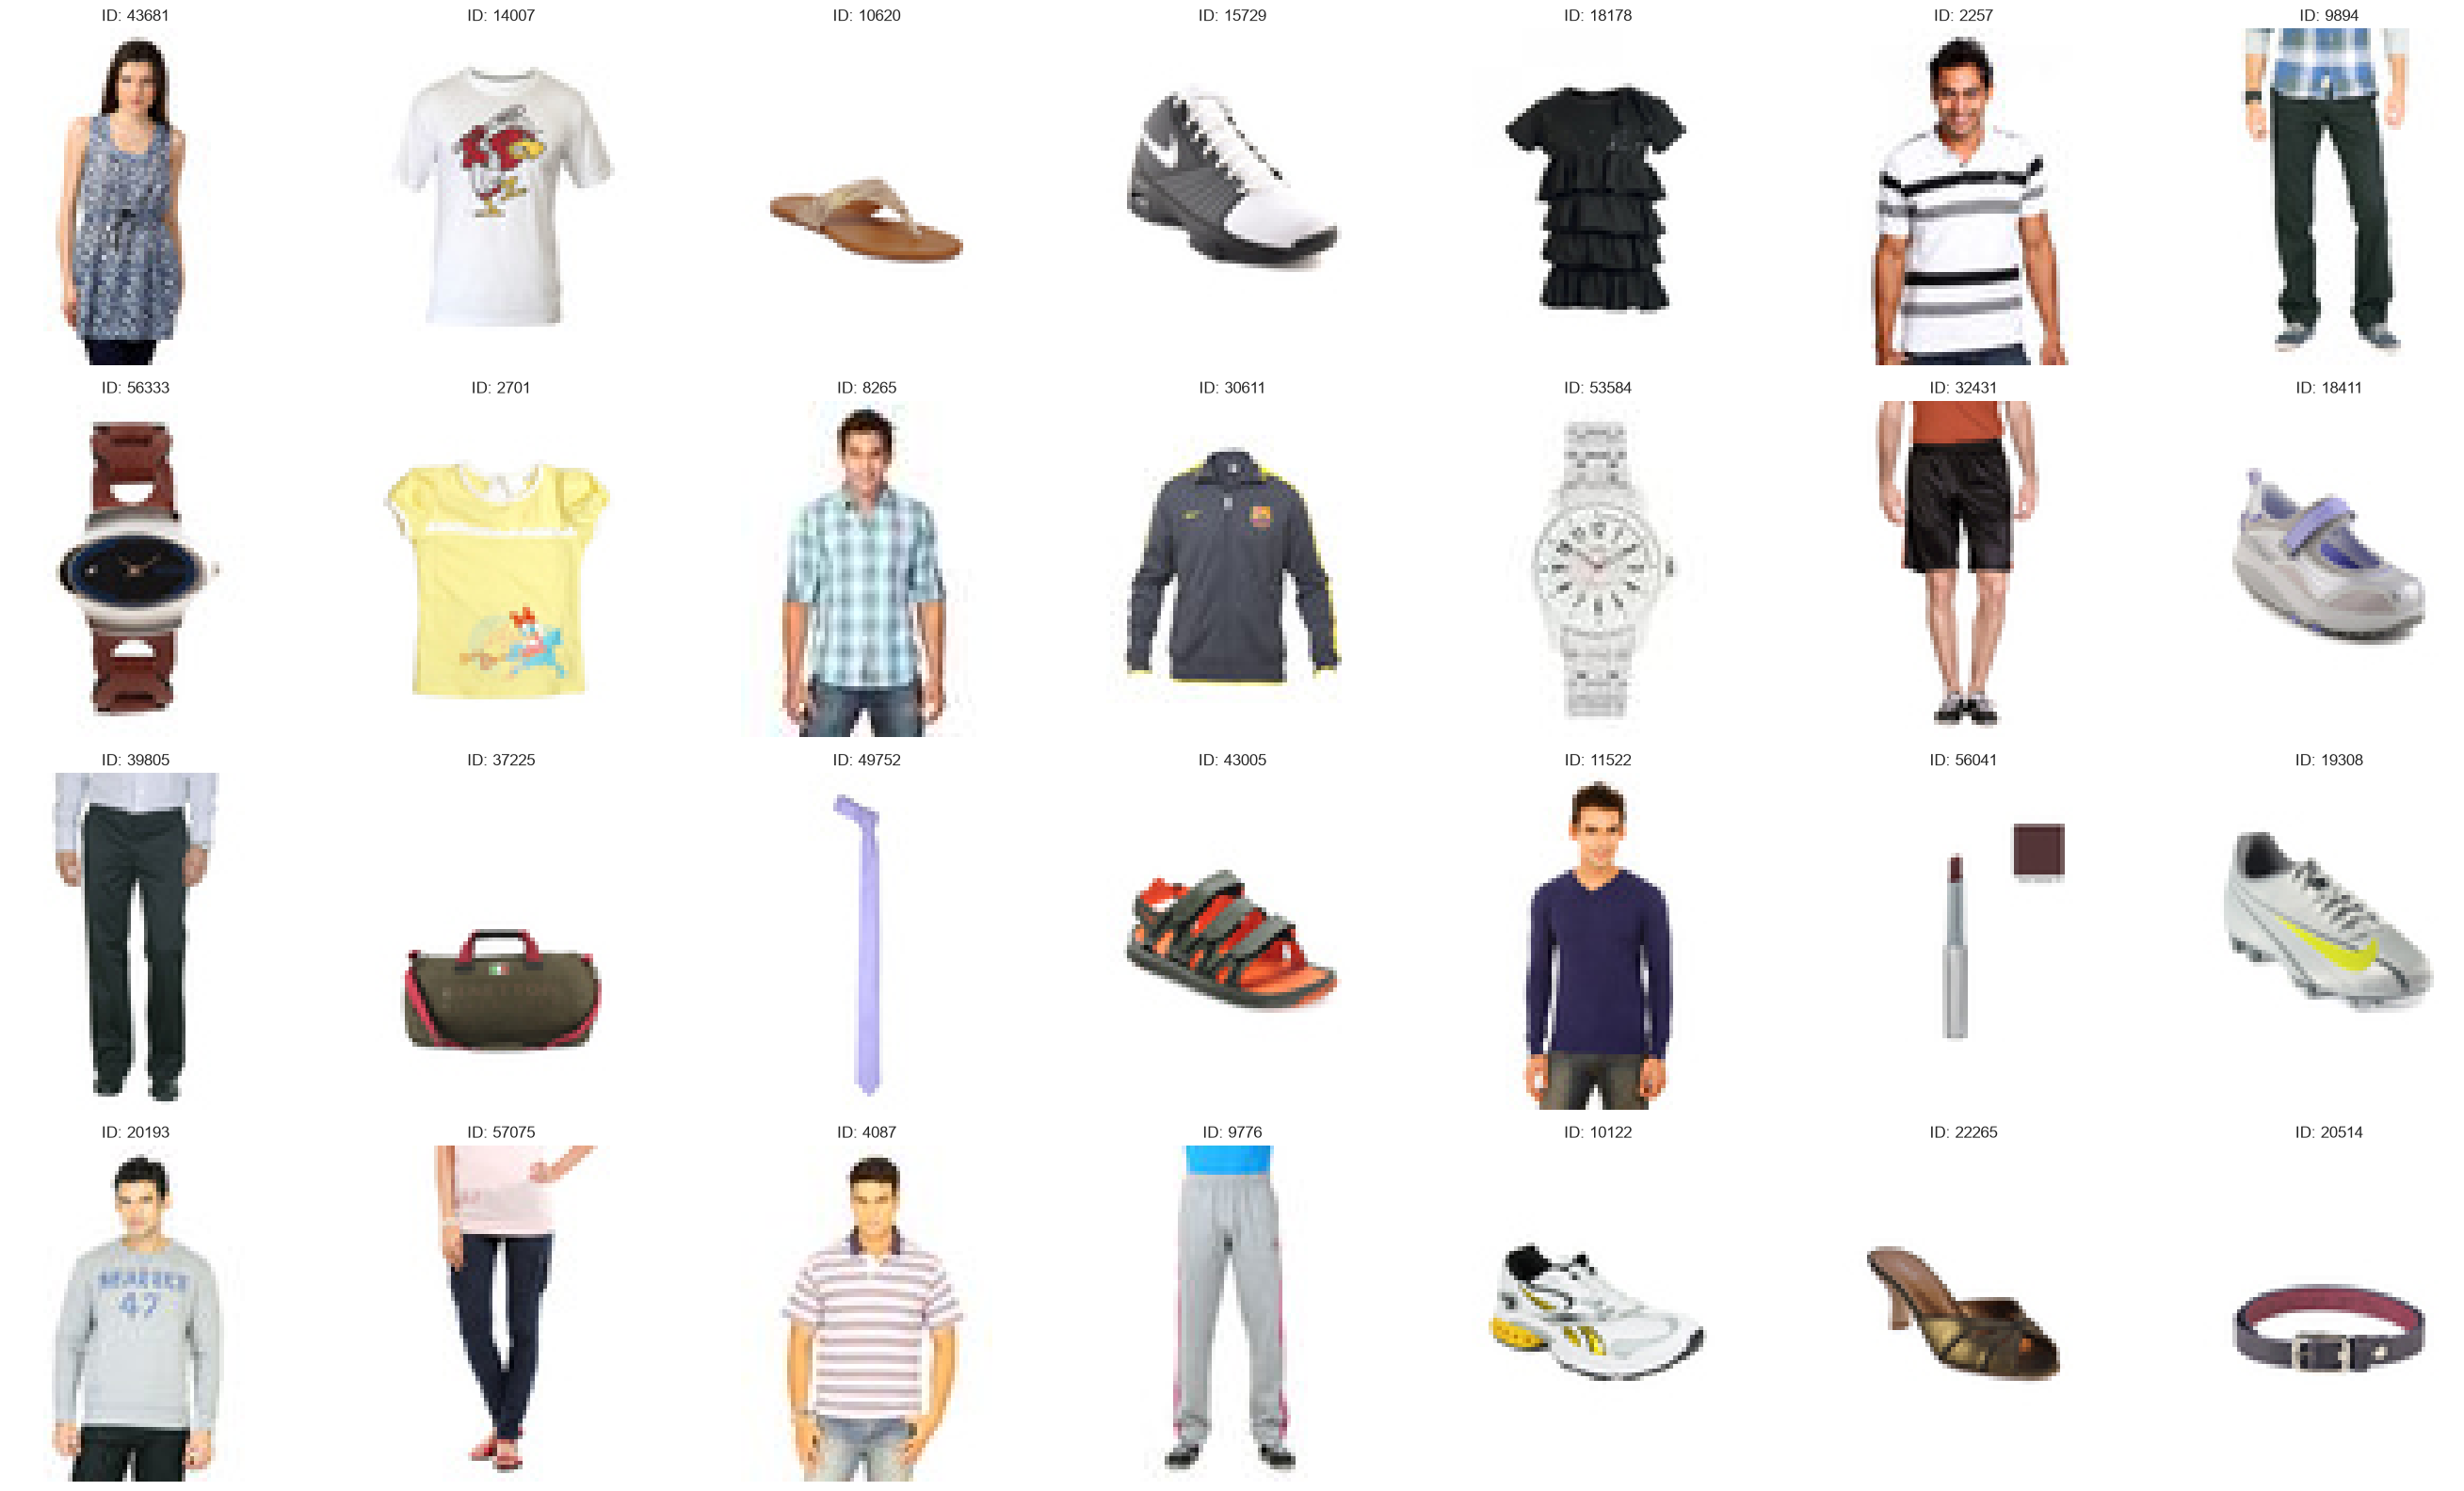

In [106]:
for seed in [42, 123, 2026]:
    show_images(df=df, image_dir=f"{path}/images", n_images=28, n_cols=7, random_state=seed)

- La mayoría de las imágenes presentan un fondo blanco o neutro, lo que reduce la variabilidad visual asociada al contexto y favorece que el modelo centre su atención en el producto.
- Los productos suelen estar centrados y claramente visibles, aunque existe variabilidad en su escala y composición debido a la presencia tanto de productos aislados como de prendas mostradas sobre modelos. D
- Las imágenes generalmente muestran un único producto principal, por lo que la tarea puede abordarse como un problema de clasificación de imágenes sin necesidad inicial de técnicas de detección de objetos.
- El dataset combina imágenes de productos aislados con imágenes de prendas mostradas sobre modelos. Esta heterogeneidad puede introducir información contextual adicional y constituye un posible factor de sesgo para el modelo.

### <a id='toc1_2_2_'></a>[Comprobaciones cuantitativas](#toc0_)

In [107]:
from fashion_mlops.utils.visualizations import analyze_image_files

In [108]:
image_info = analyze_image_files(df=df, images_dir=f"{path}/images", image_id_col="id", extension=".jpg")

In [109]:
image_info.head(10)

,id,path,exists,width,height,mode,channels,format,aspect_ratio,corrupt
0,15970,/Users/larayc/.cache/kagglehub/datasets/parama...,True,60,80,RGB,3,JPEG,0.75,False
1,39386,/Users/larayc/.cache/kagglehub/datasets/parama...,True,60,80,RGB,3,JPEG,0.75,False
2,59263,/Users/larayc/.cache/kagglehub/datasets/parama...,True,60,80,L,1,JPEG,0.75,False
3,21379,/Users/larayc/.cache/kagglehub/datasets/parama...,True,60,80,RGB,3,JPEG,0.75,False
4,53759,/Users/larayc/.cache/kagglehub/datasets/parama...,True,60,80,RGB,3,JPEG,0.75,False
5,1855,/Users/larayc/.cache/kagglehub/datasets/parama...,True,60,80,RGB,3,JPEG,0.75,False
6,30805,/Users/larayc/.cache/kagglehub/datasets/parama...,True,60,80,RGB,3,JPEG,0.75,False
7,26960,/Users/larayc/.cache/kagglehub/datasets/parama...,True,60,80,RGB,3,JPEG,0.75,False
8,29114,/Users/larayc/.cache/kagglehub/datasets/parama...,True,60,80,RGB,3,JPEG,0.75,False
9,30039,/Users/larayc/.cache/kagglehub/datasets/parama...,True,60,80,RGB,3,JPEG,0.75,False


In [110]:
print(f"Imágenes esperadas: {len(df):,}")
print(f"Imágenes encontradas: {image_info['exists'].sum():,}")
print(f"Imágenes faltantes: {(~image_info['exists']).sum():,}")
print(f"Imágenes corruptas: {image_info['corrupt'].sum():,}")

Imágenes esperadas: 44,419
Imágenes encontradas: 44,419
Imágenes faltantes: 0
Imágenes corruptas: 0


In [111]:
image_info[["width", "height", "aspect_ratio"]].describe()

,width,height,aspect_ratio
count,44419.000000,44419.000000,44419.000000
mean,59.998154,79.997366,0.750009
std,0.112468,0.215391,0.003024
min,53.000000,60.000000,0.662500
25%,60.000000,80.000000,0.750000
50%,60.000000,80.000000,0.750000
75%,60.000000,80.000000,0.750000
max,60.000000,80.000000,1.000000


In [112]:
# Dimensiones distintas
dimensions = (
    image_info
    .groupby(["width", "height", "aspect_ratio"])
    .size()
    .reset_index(name="count")
    .sort_values("count", ascending=False)
)

dimensions.head(20)

,width,height,aspect_ratio,count
7,60,80,0.7500,44396
0,53,80,0.6625,10
2,60,60,1.0000,5
1,54,80,0.6750,2
5,60,77,0.7792,2
6,60,79,0.7595,2
3,60,75,0.8000,1
4,60,76,0.7895,1


In [113]:
image_info[["mode", "channels"]].value_counts(dropna=False).reset_index(name="count")

,mode,channels,count
0,RGB,3,43988
1,L,1,431


In [114]:
image_info["format"].value_counts(dropna=False)

format
JPEG    44419
Name: count, dtype: int64

- La mayoria de la imagenes tiene un tamaño de 60x80, imagenes rectangulares.
- El aspect_ratio dominante es 0,75. El mínimo es 0,6625 y el máximo 1,0, correspondientes a las pocas imágenes con dimensiones diferentes. La gran mayoría de imágenes tienen una relación 60 : 80, es decir, 3 : 4.
Por tanto, tenemos un dataset muy homogéneo espacialmente, pero con formato vertical.
- Tenemos dos canales en las images, habría que homogeneizar los canales antes del entrenamiento. Dado que el modelo la mayoría presentan formato RGB, se realizará una conversión a RGB durante el preprocesamiento.
- Las imágenes presentan un formato homogéneo, lo que simplifica la fase de carga y preprocesamiento.

### <a id='toc1_2_3_'></a>[Duplicados](#toc0_)

In [115]:
import hashlib


def calculate_file_hash(path):
    """
    Calcula el hash MD5 de un archivo.
    """
    hash_md5 = hashlib.md5()

    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(8192), b""):
            hash_md5.update(chunk)

    return hash_md5.hexdigest()

In [116]:
valid_images = image_info.copy()

valid_images["file_hash"] = valid_images["path"].apply(calculate_file_hash)

duplicate_hashes = valid_images["file_hash"].value_counts()

duplicate_hashes = duplicate_hashes[duplicate_hashes > 1]

duplicate_hashes

file_hash
e8620ea4369e475d153fec4aafb85bfd    4
a9ec96a92919d2a196b6f2853d662277    4
a7404c7b294a40b790edfd4a223aa865    4
57805987611198778cb53575a5225a23    3
0c353129a1c9a19821862d8596622dcf    3
                                   ..
de3ea782eba978b20a18d74774d48ed9    2
d752a2cdba885e4be849ba00d1c4eabb    2
f922d23f613336bf60b4fb261b9ac8c2    2
b7ccee83ef7d5db7544480a5d6ccafec    2
c35a606cb20dc862720dfd424b53e01a    2
Name: count, Length: 652, dtype: int64

In [117]:
duplicate_ids = (
    valid_images[
        valid_images["file_hash"].isin(duplicate_hashes.index)
    ]
    .sort_values("file_hash")
    [["file_hash", "id"]]
)

duplicate_ids

,file_hash,id
567,0053270b9bb01c3388f27766088e5f94,13879
3789,0053270b9bb01c3388f27766088e5f94,13878
41692,005d520ef3a0641fab0f62fb467df14e,36771
24273,005d520ef3a0641fab0f62fb467df14e,36762
22351,008d9781de3c0ef7b1e35a517e157c7f,9639
...,...,...
21898,feb2b8effce6b8f9f74820a6f34f4a1c,40161
9402,feb2b8effce6b8f9f74820a6f34f4a1c,41976
32682,feb2b8effce6b8f9f74820a6f34f4a1c,41975
1268,ffa38a87feea9b2c13a2617b40ebad79,8589


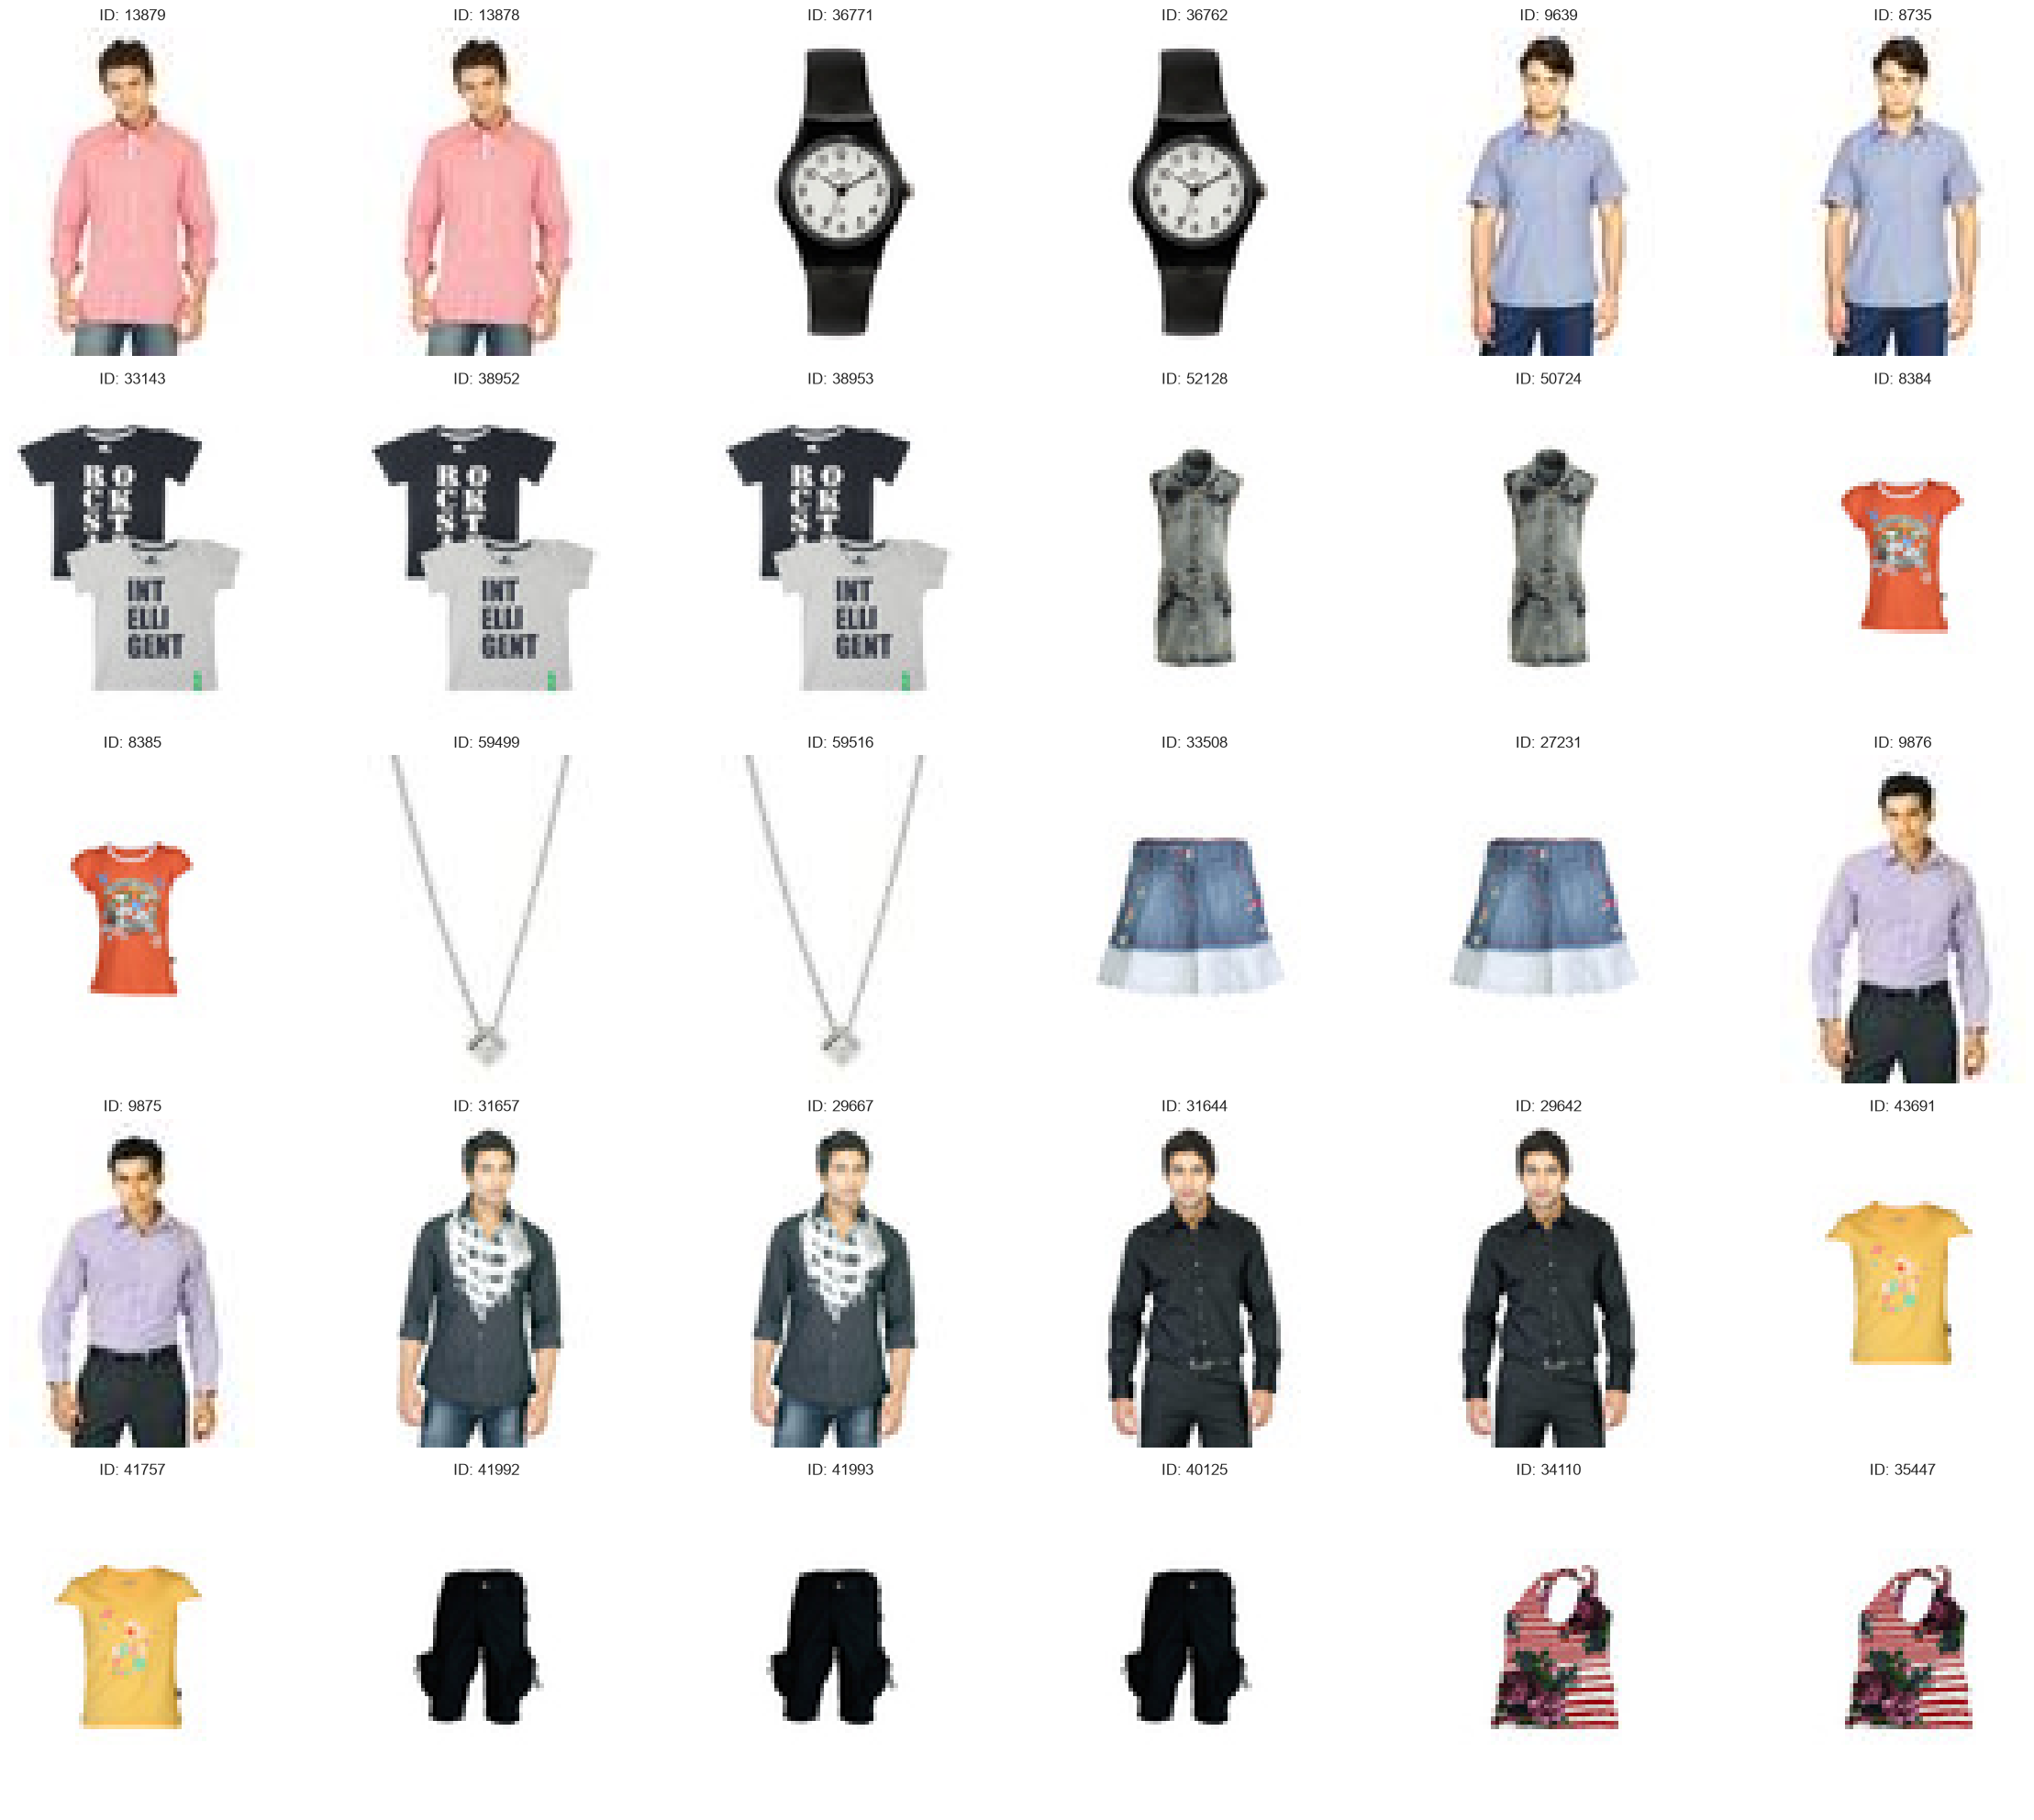

In [118]:
ids_duplicate = duplicate_ids["id"].to_list()
show_images(ids=ids_duplicate[:30], image_dir=f"{path}/images", n_cols=6)

In [119]:
df[df['id'].isin(ids_duplicate[:30])].sort_values(by="id")

,id,gender,masterCategory,subCategory,articleType,baseColour,season,year,usage,productDisplayName
4778,8384,Girls,Apparel,Topwear,Tshirts,Orange,Fall,2011,Casual,Doodle Girl's Hippie Chic Orange Kidswear
2384,8385,Girls,Apparel,Topwear,Tshirts,Orange,Fall,2011,Casual,Doodle Girl's Hippie Chic Orange Teen Kidswear
41399,8735,Men,Apparel,Topwear,Shirts,Navy Blue,Fall,2011,Casual,Indigo Nation Men Checks Shirt Blue Shirts
22353,9639,Men,Apparel,Topwear,Shirts,Blue,Fall,2011,Casual,Indigo Nation Men Checks Blue Shirts
20691,9875,Men,Apparel,Topwear,Shirts,Purple,Fall,2011,Casual,Indigo Nation Men Price catch Purple Shirts
43979,9876,Men,Apparel,Topwear,Shirts,Purple,Fall,2011,Casual,Indigo Nation Men Purple Striped Shirt
3789,13878,Men,Apparel,Topwear,Shirts,Red,Fall,2011,Casual,Scullers Men Check Red Shirts
567,13879,Men,Apparel,Topwear,Shirts,Red,Fall,2011,Casual,Scullers Men Check Red Shirts
17328,27231,Women,Apparel,Bottomwear,Skirts,Blue,Summer,2012,Casual,Doodle Kids Girl Washed Blue Skirt
34588,29642,Men,Apparel,Topwear,Shirts,Black,Summer,2012,Formal,Indigo Nation Men Black Shirt


In [120]:
duplicate_metadata = duplicate_ids.merge(df, on="id", how="left").sort_values(["file_hash", "id"])

duplicate_metadata

,file_hash,id,gender,masterCategory,subCategory,articleType,baseColour,season,year,usage,productDisplayName
1,0053270b9bb01c3388f27766088e5f94,13878,Men,Apparel,Topwear,Shirts,Red,Fall,2011,Casual,Scullers Men Check Red Shirts
0,0053270b9bb01c3388f27766088e5f94,13879,Men,Apparel,Topwear,Shirts,Red,Fall,2011,Casual,Scullers Men Check Red Shirts
3,005d520ef3a0641fab0f62fb467df14e,36762,Men,Accessories,Watches,Watches,White,Winter,2016,Casual,Maxima Men White Dial Watch
2,005d520ef3a0641fab0f62fb467df14e,36771,Women,Accessories,Watches,Watches,White,Winter,2016,Casual,Maxima Women White Dial Watch
5,008d9781de3c0ef7b1e35a517e157c7f,8735,Men,Apparel,Topwear,Shirts,Navy Blue,Fall,2011,Casual,Indigo Nation Men Checks Shirt Blue Shirts
...,...,...,...,...,...,...,...,...,...,...,...
1426,feb2b8effce6b8f9f74820a6f34f4a1c,40161,Girls,Apparel,Bottomwear,Capris,White,Summer,2012,Casual,Gini and Jony Girls White Pedal Pusher
1428,feb2b8effce6b8f9f74820a6f34f4a1c,41975,Girls,Apparel,Bottomwear,Capris,White,Summer,2012,Casual,Gini and Jony Girls White Pedal Pusher
1427,feb2b8effce6b8f9f74820a6f34f4a1c,41976,Girls,Apparel,Bottomwear,Capris,White,Summer,2012,Casual,Gini and Jony Girls White Pedal Pusher
1430,ffa38a87feea9b2c13a2617b40ebad79,8588,Men,Apparel,Topwear,Shirts,Blue,Fall,2011,Casual,Scullers Men Scul Blue Shirts


In [121]:
metadata_cols = df.columns.drop("id")

duplicate_analysis = []

for file_hash, group in duplicate_metadata.groupby("file_hash"):

    differences = {
        col: group[col].nunique(dropna=False)
        for col in metadata_cols
    }

    duplicate_analysis.append({
        "file_hash": file_hash,
        "n_images": len(group),
        **differences
    })

duplicate_analysis = pd.DataFrame(duplicate_analysis)

In [122]:
for col in metadata_cols:
    n = (
        duplicate_analysis[col]
        .gt(1)
        .sum()
    )

    print(f"{col}: {n} grupos con diferencias ({n/len(duplicate_analysis)*100:.2f}% de los grupos)")

gender: 8 grupos con diferencias (1.23% de los grupos)
masterCategory: 4 grupos con diferencias (0.61% de los grupos)
subCategory: 6 grupos con diferencias (0.92% de los grupos)
articleType: 7 grupos con diferencias (1.07% de los grupos)
baseColour: 52 grupos con diferencias (7.98% de los grupos)
season: 9 grupos con diferencias (1.38% de los grupos)
year: 9 grupos con diferencias (1.38% de los grupos)
usage: 3 grupos con diferencias (0.46% de los grupos)
productDisplayName: 224 grupos con diferencias (34.36% de los grupos)


Hemos detectado 652 grupos de imágenes con contenido binario idéntico mediante hash. La mayoría de estos grupos mantiene las mismas etiquetas categóricas. Sin embargo, se identificaron discrepancias en algunas variables: 8 grupos presentan diferencias en gender, 4 en masterCategory, 6 en subCategory, 7 en articleType, 9 en season y 3 en usage. Las discrepancias en las posibles variables a predecir son especialmente relevantes para el model, por ello las inspeccionamos individualmente para determinar si corresponden a errores de etiquetado o a diferentes registros de catálogo que reutilizan una misma imagen.

> Veamos que ocurre en nuestras variables de interés

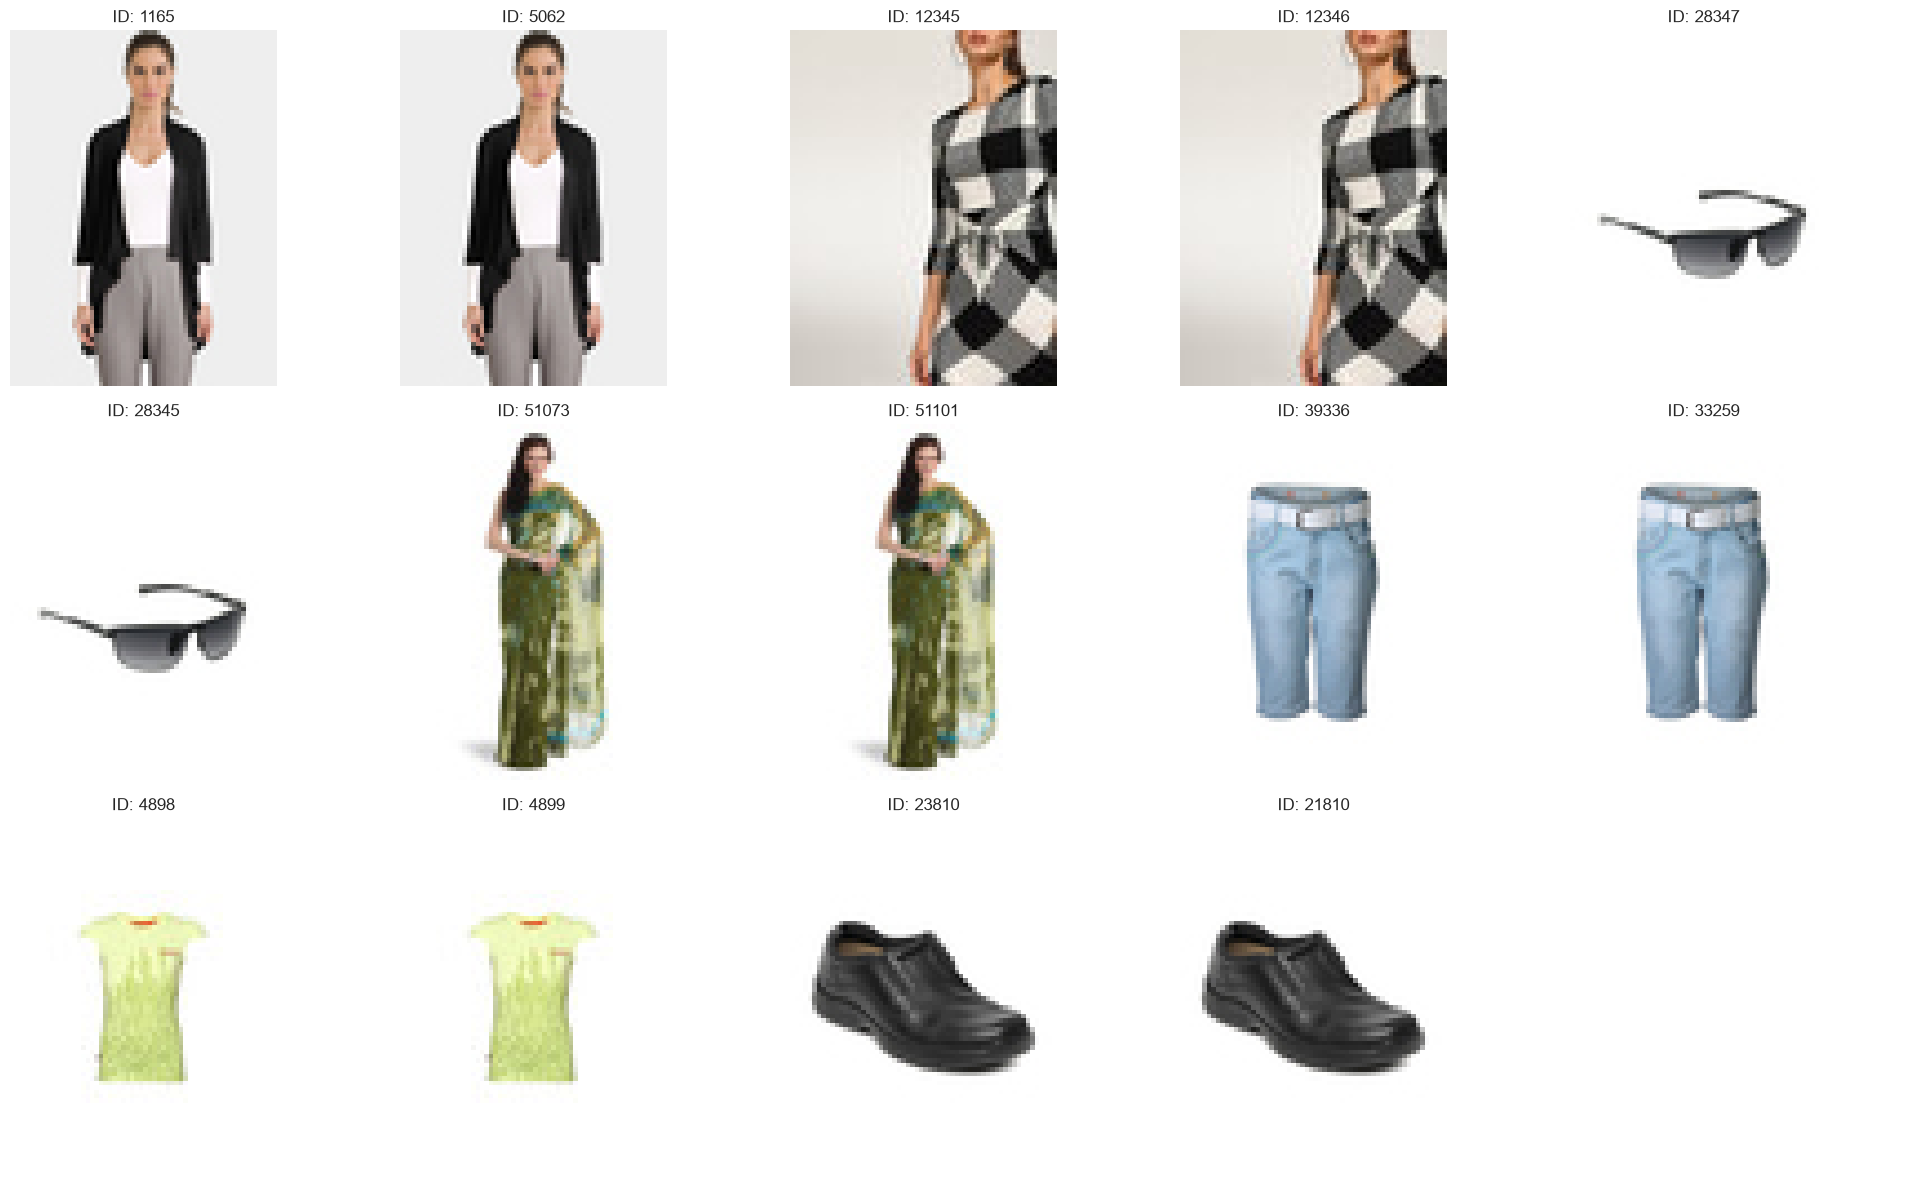

Imágenes en grupos con articleType conflictivo: 14 
Porcentaje sobre el dataset: 0.978%


,file_hash,id,gender,masterCategory,subCategory,articleType,baseColour,season,year,usage,productDisplayName
41,0681830b0b2c248fe2e3f3f4c419d50c,1165,Men,Apparel,Topwear,Tshirts,Blue,Summer,2013,Sports,Nike Mean Team India Cricket Jersey
42,0681830b0b2c248fe2e3f3f4c419d50c,5062,Men,Accessories,Watches,Watches,Black,Winter,2016,Casual,Being Human Men Black Dial Steel Plated Strap ...
201,21cc7958092d05386a9e178a350016fe,12345,Women,Apparel,Saree,Sarees,Maroon,Spring,2018,Ethnic,Xoxo Women Maroon Pure Georgette Solid Ready-t...
202,21cc7958092d05386a9e178a350016fe,12346,Women,Apparel,Topwear,Tshirts,Grey,Fall,2011,Formal,Reebok Women Grey Solid V-Neck T-shirt
748,80a87114757ad770dbb029914b4c2df2,28347,Men,Free Items,Free Gifts,Free Gifts,Black,Winter,2016,Casual,IDEE Men Black Sunglasses
749,80a87114757ad770dbb029914b4c2df2,28345,Men,Accessories,Eyewear,Sunglasses,Black,Winter,2016,Casual,Idee Men Black Sunglasses
879,99acfb864e2b3b0bfa45ccfa52b4a087,51073,Women,Free Items,Free Gifts,Free Gifts,Olive,Summer,2012,Ethnic,Satya Paul Olive Saree
880,99acfb864e2b3b0bfa45ccfa52b4a087,51101,Women,Apparel,Saree,Sarees,Green,Summer,2012,Ethnic,Satya Paul Green Printed Saree
1046,b7ccee83ef7d5db7544480a5d6ccafec,39336,Boys,Apparel,Bottomwear,Capris,Blue,Summer,2012,Casual,Gini & Jony Boys Blue Shorts
1047,b7ccee83ef7d5db7544480a5d6ccafec,33259,Boys,Apparel,Bottomwear,Shorts,Blue,Summer,2012,Casual,Gini & Jony Boys Blue Shorts


In [124]:
article_conflicts = variable_conflicts(duplicate_metadata, "articleType")
article_conflicts

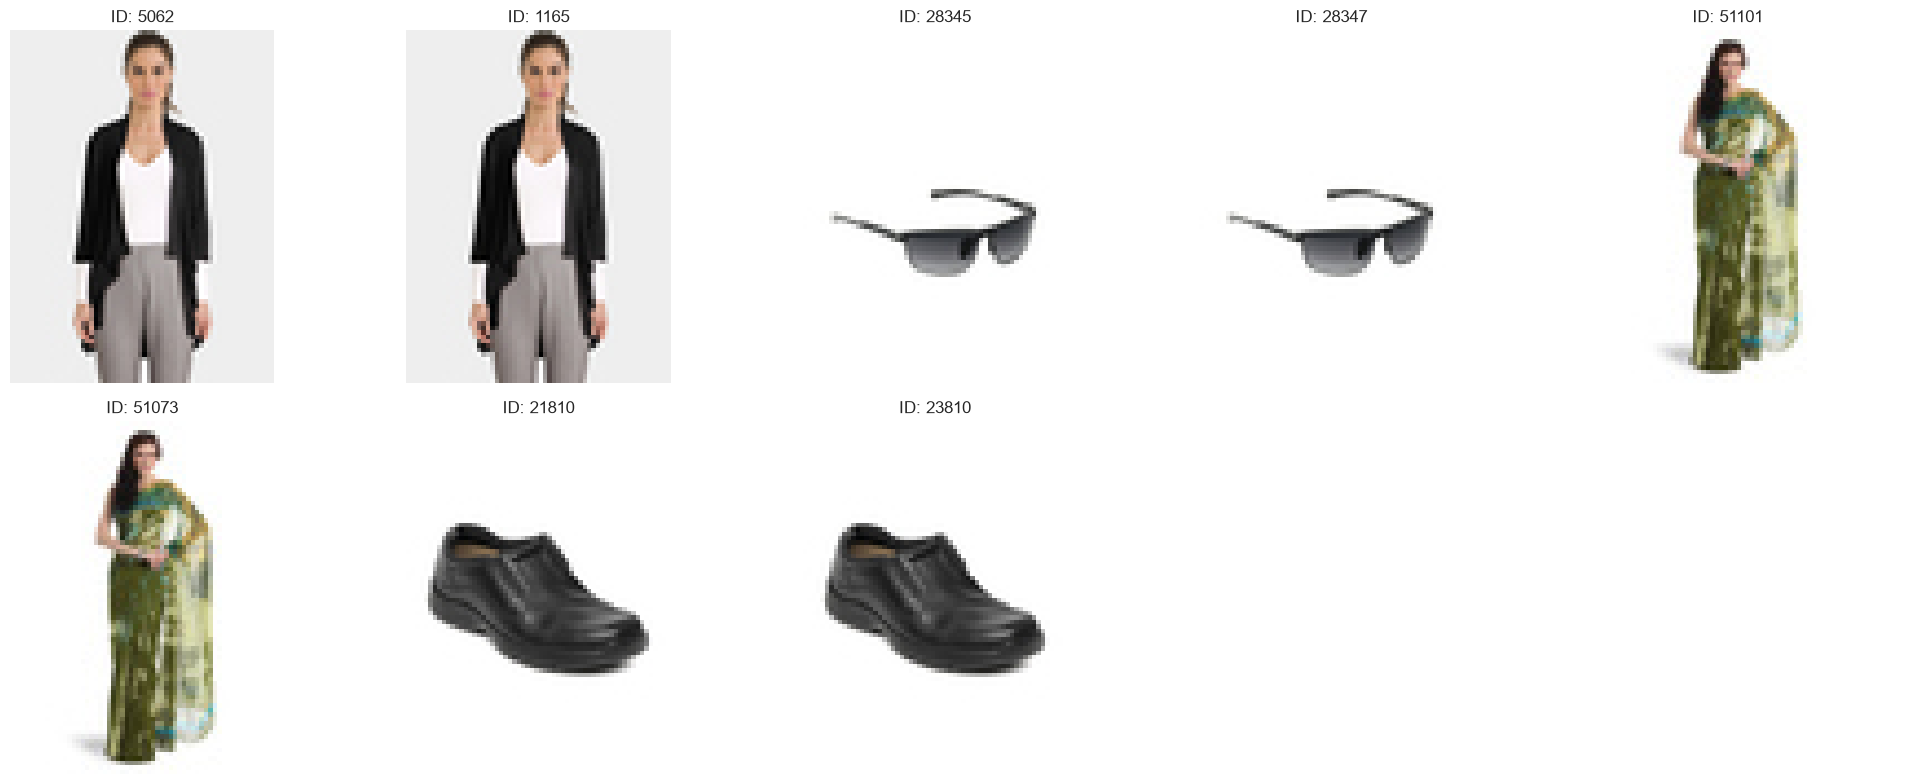

Imágenes en grupos con masterCategory conflictivo: 8 
Porcentaje sobre el dataset: 0.559%


,file_hash,id,gender,masterCategory,subCategory,articleType,baseColour,season,year,usage,productDisplayName
42,0681830b0b2c248fe2e3f3f4c419d50c,5062,Men,Accessories,Watches,Watches,Black,Winter,2016,Casual,Being Human Men Black Dial Steel Plated Strap ...
41,0681830b0b2c248fe2e3f3f4c419d50c,1165,Men,Apparel,Topwear,Tshirts,Blue,Summer,2013,Sports,Nike Mean Team India Cricket Jersey
749,80a87114757ad770dbb029914b4c2df2,28345,Men,Accessories,Eyewear,Sunglasses,Black,Winter,2016,Casual,Idee Men Black Sunglasses
748,80a87114757ad770dbb029914b4c2df2,28347,Men,Free Items,Free Gifts,Free Gifts,Black,Winter,2016,Casual,IDEE Men Black Sunglasses
880,99acfb864e2b3b0bfa45ccfa52b4a087,51101,Women,Apparel,Saree,Sarees,Green,Summer,2012,Ethnic,Satya Paul Green Printed Saree
879,99acfb864e2b3b0bfa45ccfa52b4a087,51073,Women,Free Items,Free Gifts,Free Gifts,Olive,Summer,2012,Ethnic,Satya Paul Olive Saree
1239,df47bd490230a704290cf8f2b82ca1dc,21810,Men,Accessories,Wallets,Wallets,Brown,Winter,2016,Casual,Fossil Men Hood Traveller Brown Wallet
1238,df47bd490230a704290cf8f2b82ca1dc,23810,Men,Footwear,Shoes,Casual Shoes,Black,Fall,2014,Casual,Clarks Men Black Supa Step Casual Shoes


In [125]:
master_category_conflicts = variable_conflicts(duplicate_metadata, "masterCategory")
master_category_conflicts

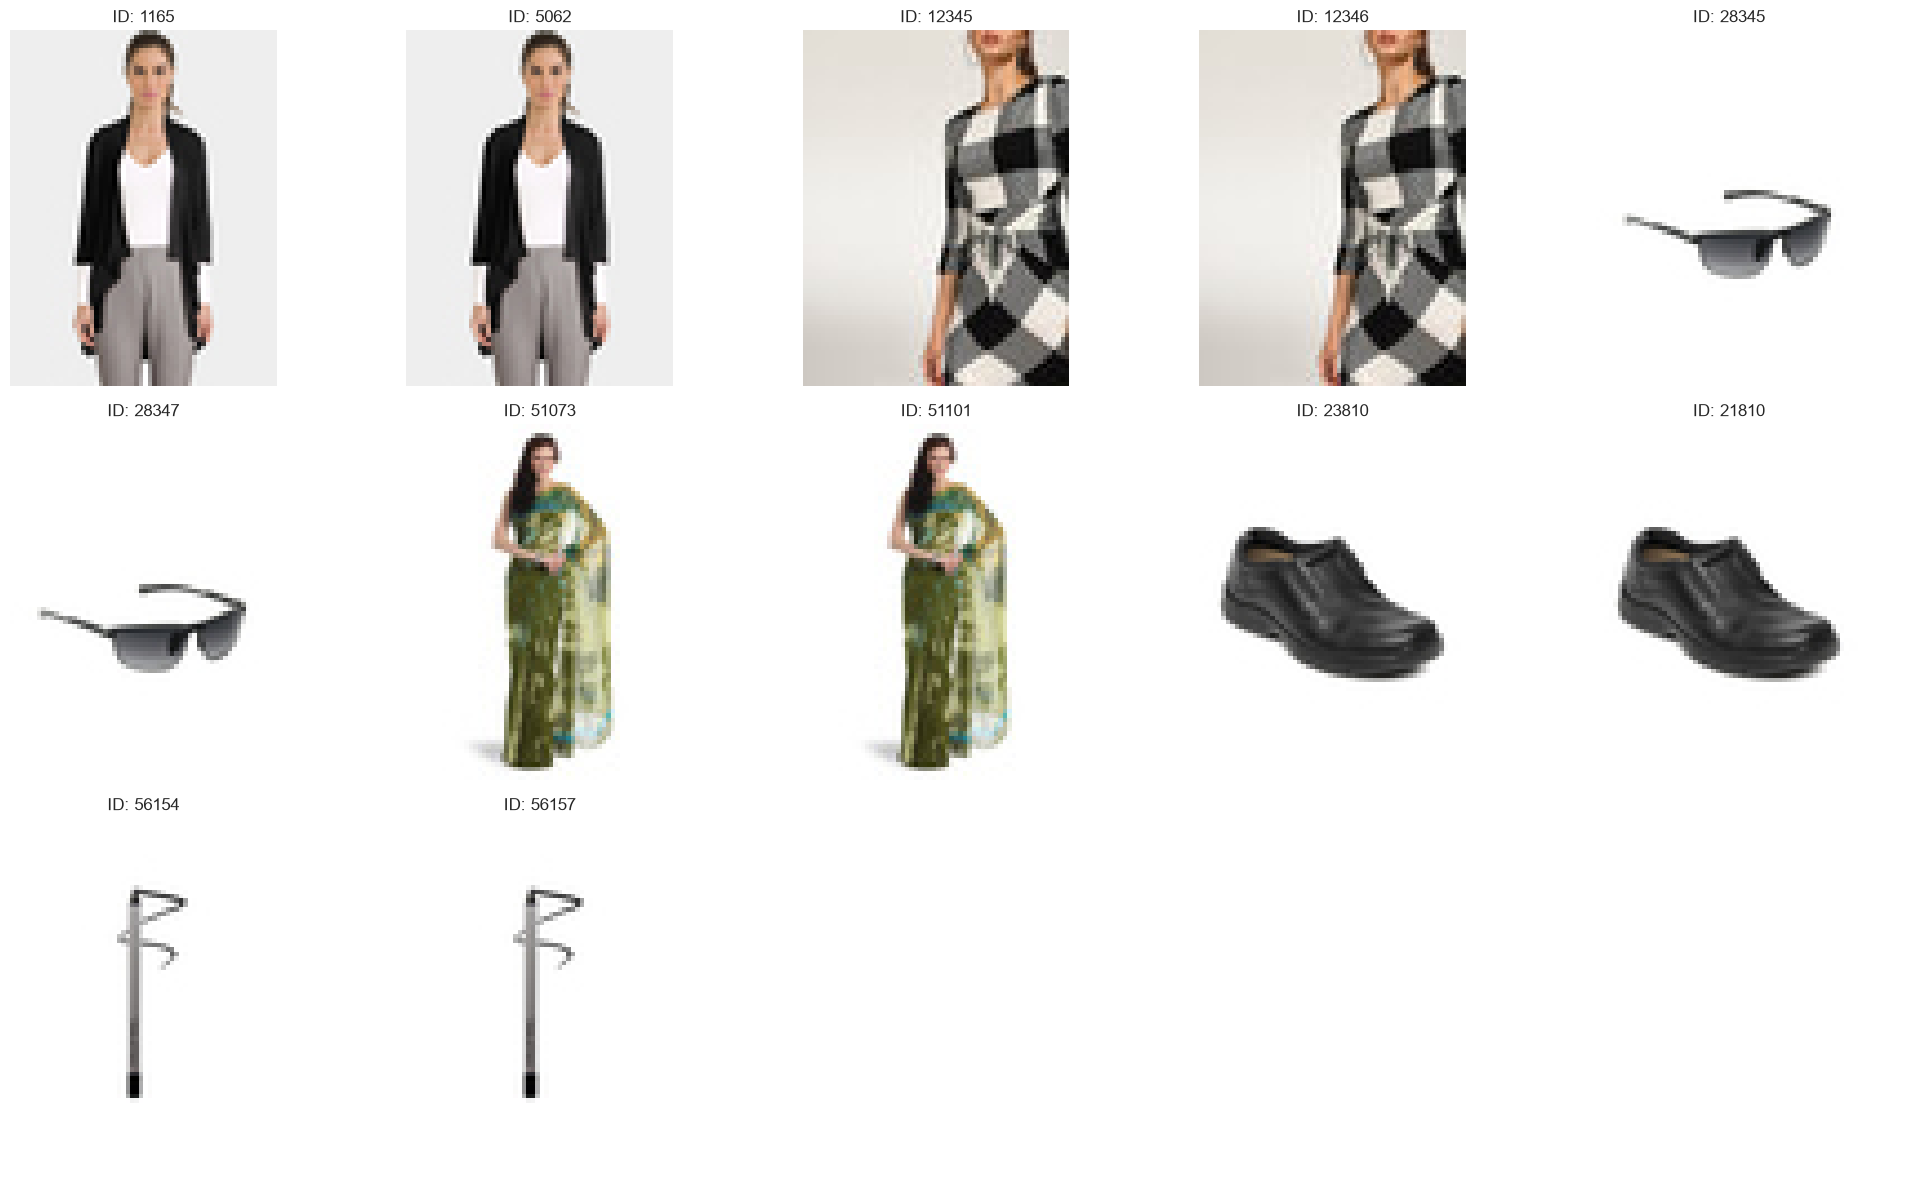

Imágenes en grupos con subCategory conflictivo: 12 
Porcentaje sobre el dataset: 0.839%


,file_hash,id,gender,masterCategory,subCategory,articleType,baseColour,season,year,usage,productDisplayName
41,0681830b0b2c248fe2e3f3f4c419d50c,1165,Men,Apparel,Topwear,Tshirts,Blue,Summer,2013,Sports,Nike Mean Team India Cricket Jersey
42,0681830b0b2c248fe2e3f3f4c419d50c,5062,Men,Accessories,Watches,Watches,Black,Winter,2016,Casual,Being Human Men Black Dial Steel Plated Strap ...
201,21cc7958092d05386a9e178a350016fe,12345,Women,Apparel,Saree,Sarees,Maroon,Spring,2018,Ethnic,Xoxo Women Maroon Pure Georgette Solid Ready-t...
202,21cc7958092d05386a9e178a350016fe,12346,Women,Apparel,Topwear,Tshirts,Grey,Fall,2011,Formal,Reebok Women Grey Solid V-Neck T-shirt
749,80a87114757ad770dbb029914b4c2df2,28345,Men,Accessories,Eyewear,Sunglasses,Black,Winter,2016,Casual,Idee Men Black Sunglasses
748,80a87114757ad770dbb029914b4c2df2,28347,Men,Free Items,Free Gifts,Free Gifts,Black,Winter,2016,Casual,IDEE Men Black Sunglasses
879,99acfb864e2b3b0bfa45ccfa52b4a087,51073,Women,Free Items,Free Gifts,Free Gifts,Olive,Summer,2012,Ethnic,Satya Paul Olive Saree
880,99acfb864e2b3b0bfa45ccfa52b4a087,51101,Women,Apparel,Saree,Sarees,Green,Summer,2012,Ethnic,Satya Paul Green Printed Saree
1238,df47bd490230a704290cf8f2b82ca1dc,23810,Men,Footwear,Shoes,Casual Shoes,Black,Fall,2014,Casual,Clarks Men Black Supa Step Casual Shoes
1239,df47bd490230a704290cf8f2b82ca1dc,21810,Men,Accessories,Wallets,Wallets,Brown,Winter,2016,Casual,Fossil Men Hood Traveller Brown Wallet


In [126]:
subcategory_conflicts = variable_conflicts(duplicate_metadata, "subCategory")
subcategory_conflicts

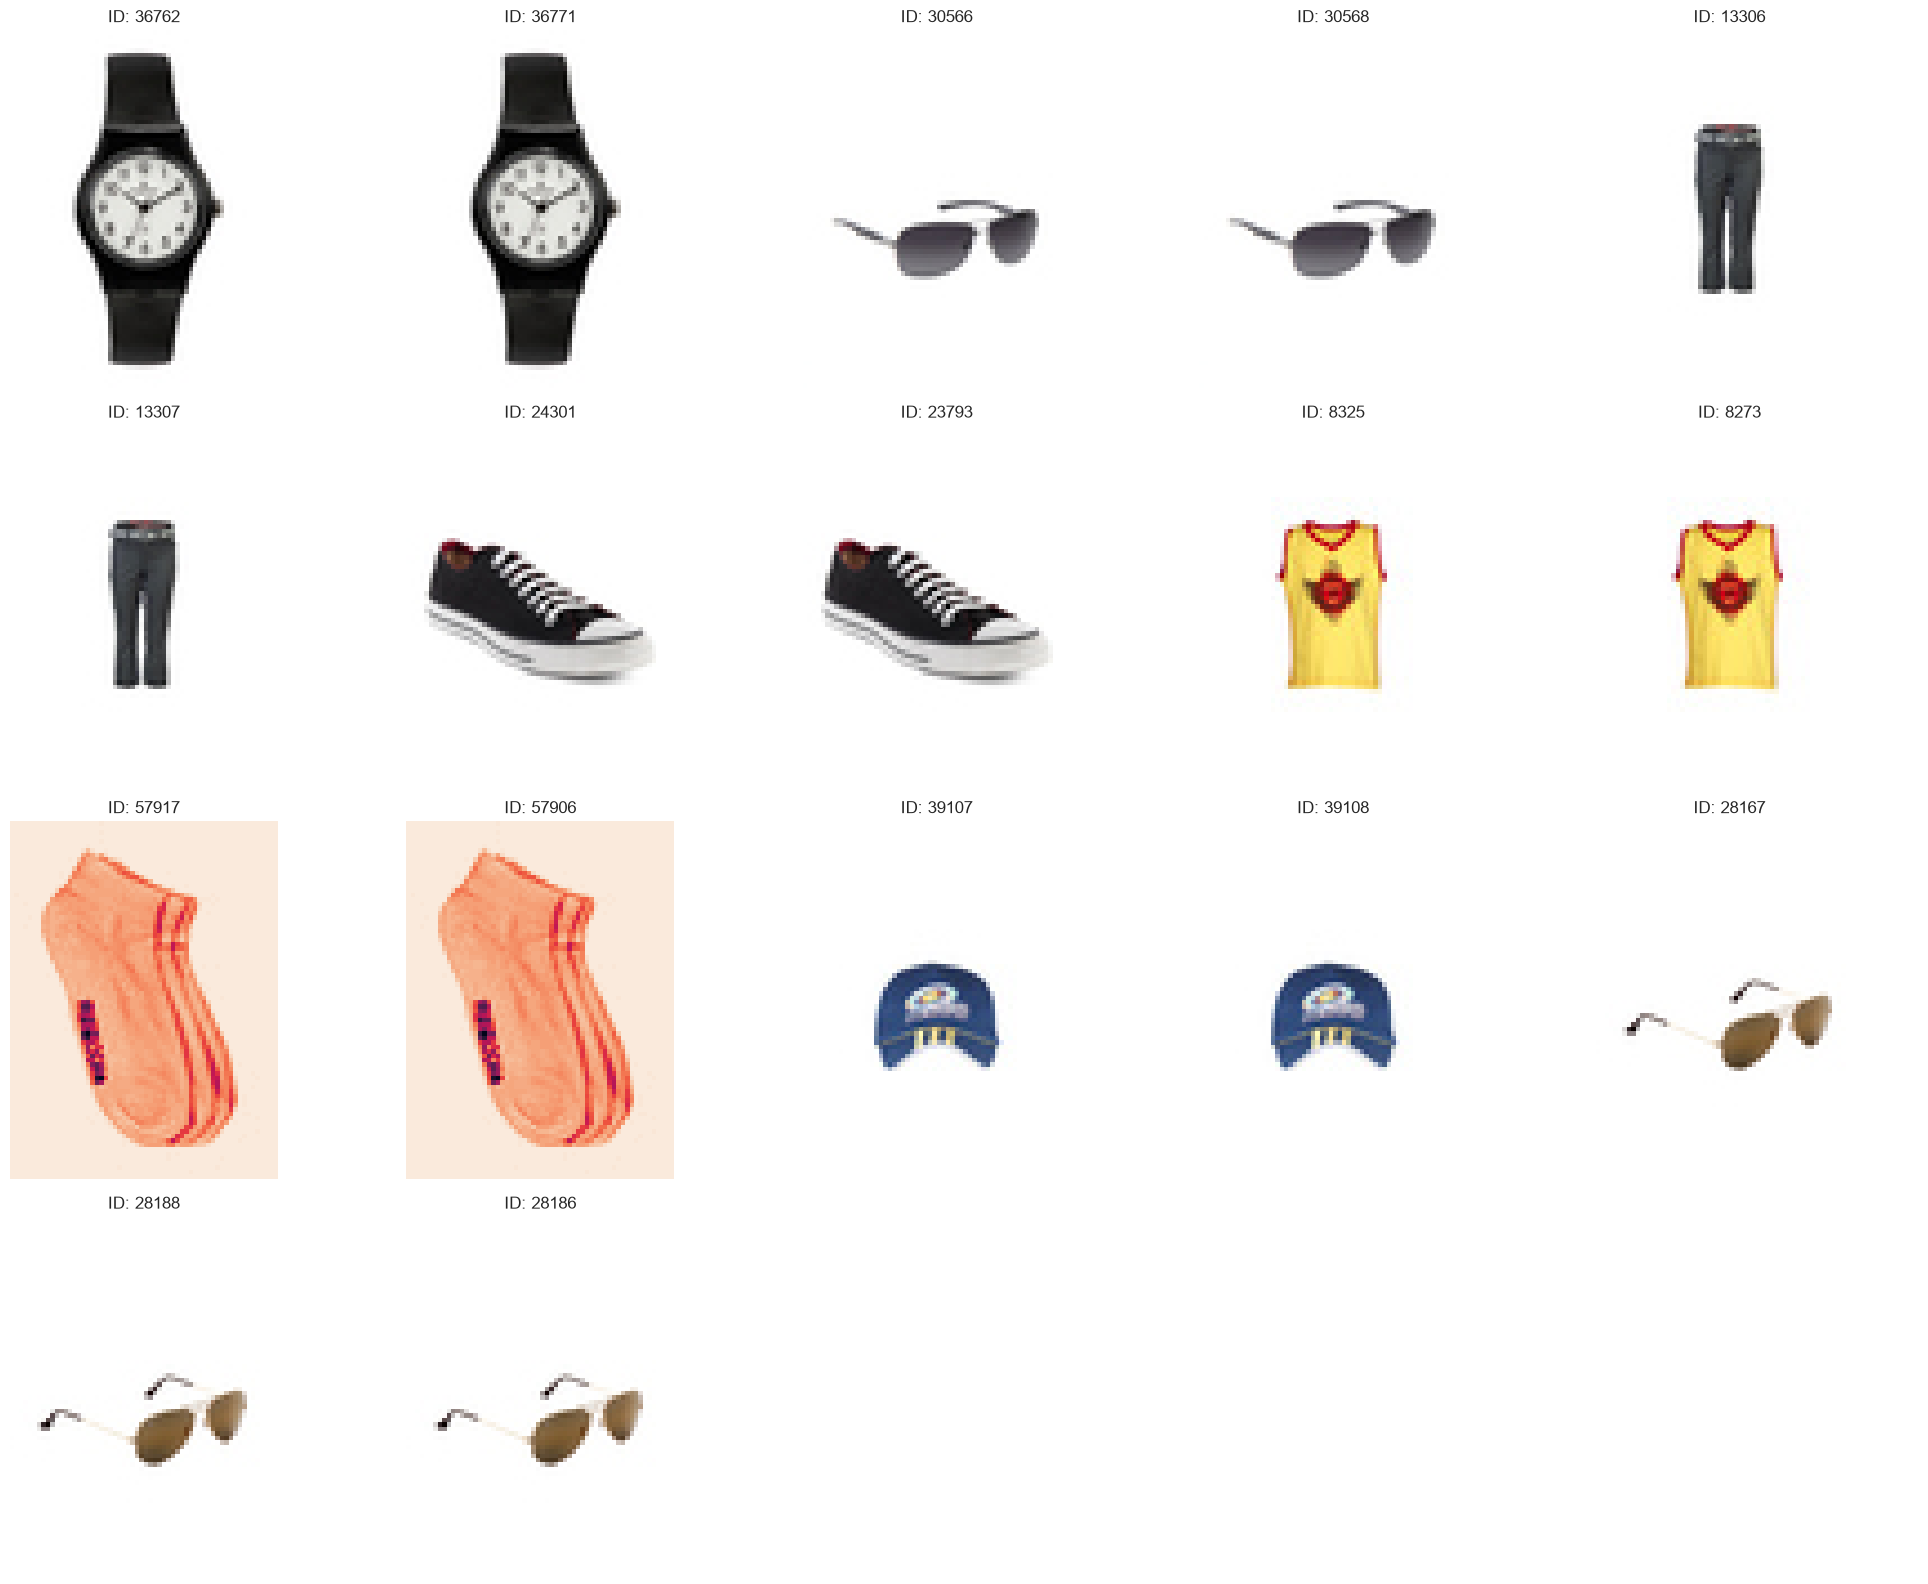

Imágenes en grupos con gender conflictivo: 17 
Porcentaje sobre el dataset: 1.188%


,file_hash,id,gender,masterCategory,subCategory,articleType,baseColour,season,year,usage,productDisplayName
3,005d520ef3a0641fab0f62fb467df14e,36762,Men,Accessories,Watches,Watches,White,Winter,2016,Casual,Maxima Men White Dial Watch
2,005d520ef3a0641fab0f62fb467df14e,36771,Women,Accessories,Watches,Watches,White,Winter,2016,Casual,Maxima Women White Dial Watch
33,05a44638e2793e5de4d95c9d830870e7,30566,Men,Accessories,Eyewear,Sunglasses,Red,Winter,2016,Casual,Opium Men Black Sunglasses
34,05a44638e2793e5de4d95c9d830870e7,30568,Unisex,Accessories,Eyewear,Sunglasses,Black,Winter,2016,Casual,Opium Unisex Black Sunglass
234,297643c3732c351b51b2f97774e0a14a,13306,Boys,Apparel,Bottomwear,Trousers,Black,Fall,2011,Casual,Gini and Jony Kids Solid Black Trousers
235,297643c3732c351b51b2f97774e0a14a,13307,Men,Apparel,Bottomwear,Trousers,Black,Fall,2011,Casual,Gini and Jony Kids Solid Black Trousers
441,4e769cf2a79f206f3962e7a933a3eab6,24301,Men,Footwear,Shoes,Casual Shoes,Black,Spring,2012,Casual,Converse Men Black Tongue Triple Colour Shoes
442,4e769cf2a79f206f3962e7a933a3eab6,23793,Unisex,Footwear,Shoes,Casual Shoes,Black,Spring,2012,Casual,Converse Unisex Tongue Triple Color Black Casu...
497,57f546d139a09fcfb79ce253925ce791,8325,Boys,Apparel,Topwear,Tshirts,Yellow,Fall,2011,Casual,Doodle Boy's Athletic 77 Dept Yellow Teen Kids...
498,57f546d139a09fcfb79ce253925ce791,8273,Men,Apparel,Topwear,Tshirts,Yellow,Fall,2011,Casual,Doodle Men Athletic 77 Dept Yellow tee Yellow ...


In [127]:
gender_conflicts = variable_conflicts(duplicate_metadata, "gender")
gender_conflicts

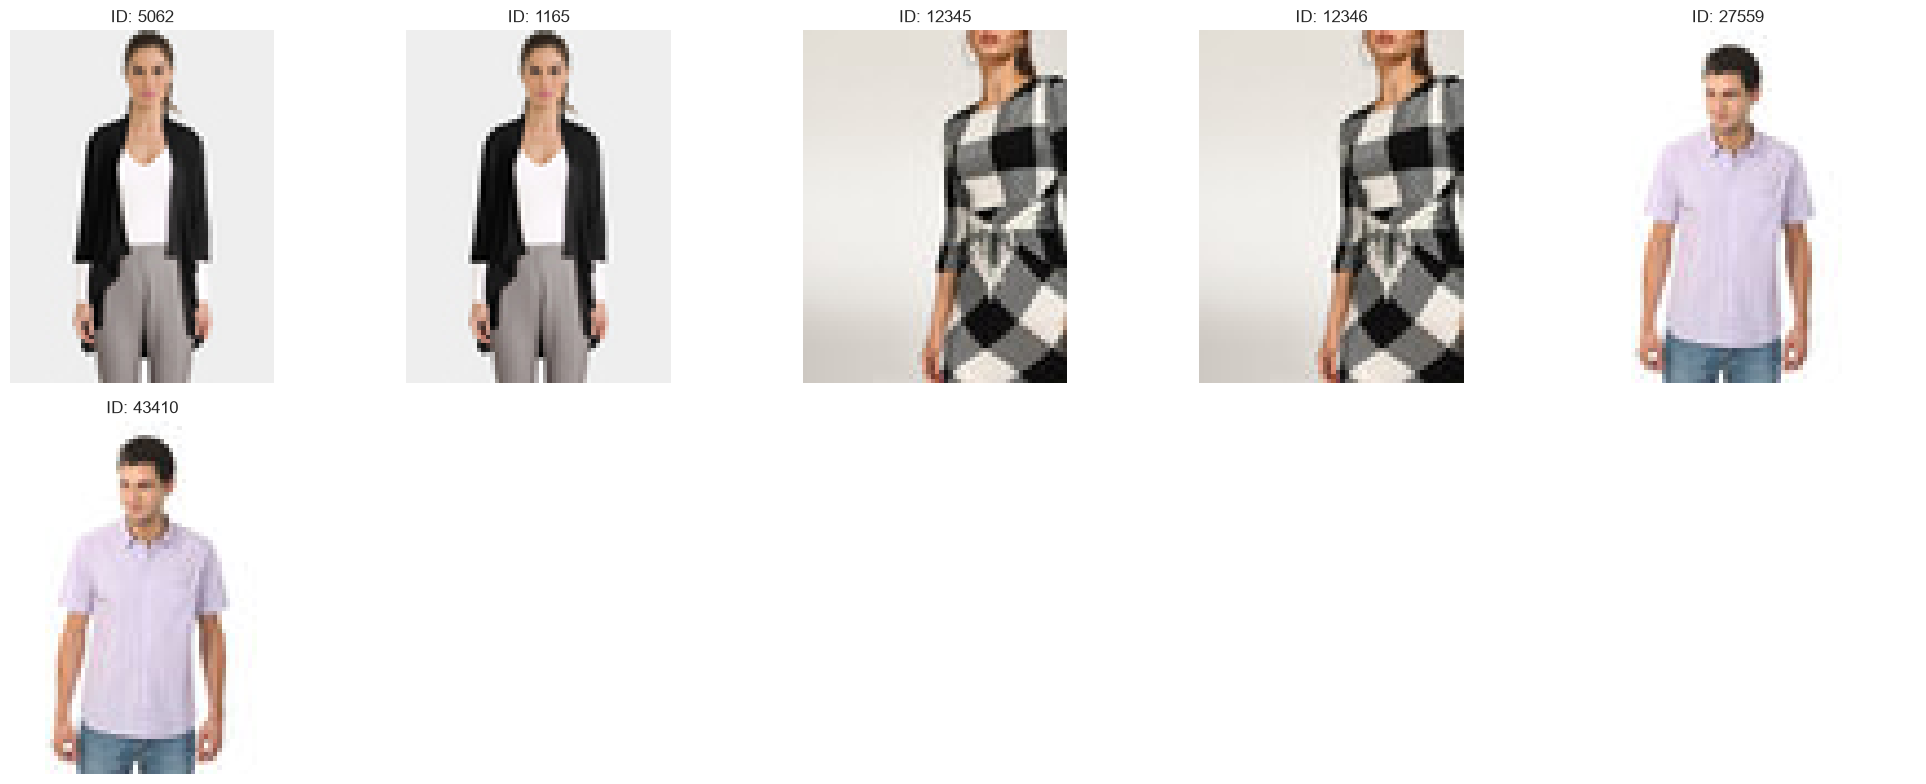

Imágenes en grupos con usage conflictivo: 6 
Porcentaje sobre el dataset: 0.419%


,file_hash,id,gender,masterCategory,subCategory,articleType,baseColour,season,year,usage,productDisplayName
42,0681830b0b2c248fe2e3f3f4c419d50c,5062,Men,Accessories,Watches,Watches,Black,Winter,2016,Casual,Being Human Men Black Dial Steel Plated Strap ...
41,0681830b0b2c248fe2e3f3f4c419d50c,1165,Men,Apparel,Topwear,Tshirts,Blue,Summer,2013,Sports,Nike Mean Team India Cricket Jersey
201,21cc7958092d05386a9e178a350016fe,12345,Women,Apparel,Saree,Sarees,Maroon,Spring,2018,Ethnic,Xoxo Women Maroon Pure Georgette Solid Ready-t...
202,21cc7958092d05386a9e178a350016fe,12346,Women,Apparel,Topwear,Tshirts,Grey,Fall,2011,Formal,Reebok Women Grey Solid V-Neck T-shirt
503,596af0ed7601e835b7fb1533c389cb0b,27559,Men,Apparel,Topwear,Shirts,Purple,Summer,2012,Casual,Scullers Men Purple Shirt
504,596af0ed7601e835b7fb1533c389cb0b,43410,Men,Apparel,Topwear,Shirts,Purple,Summer,2012,Formal,Scullers Men Purple Shirt


In [128]:
usage_conflicts = variable_conflicts(duplicate_metadata, "usage")
usage_conflicts

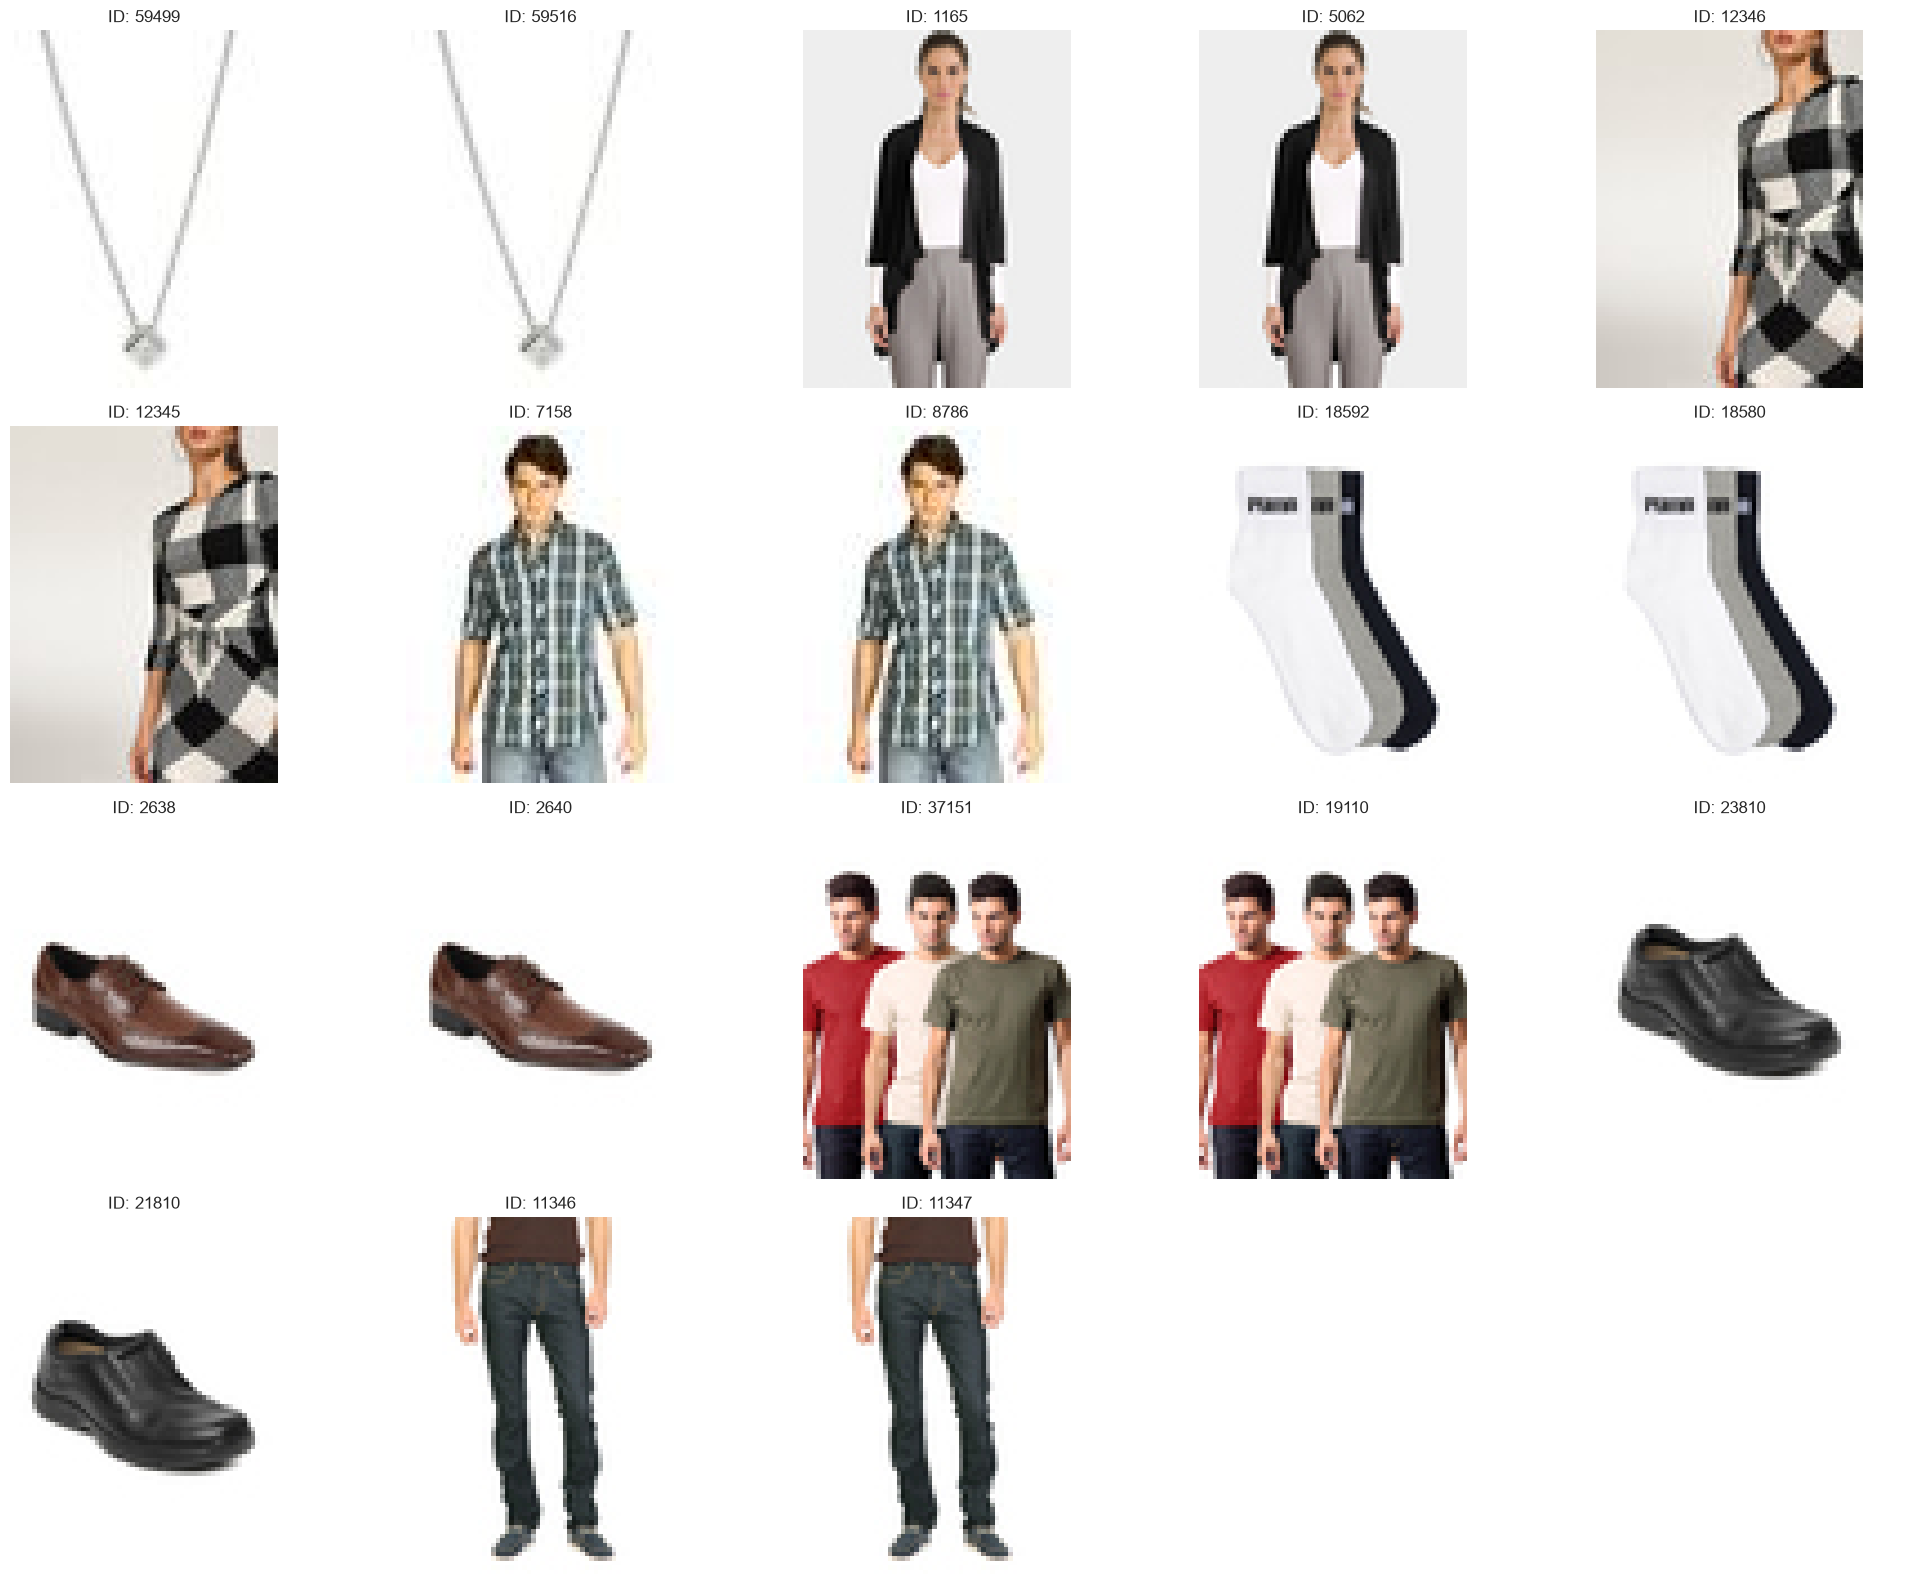

Imágenes en grupos con season conflictivo: 18 
Porcentaje sobre el dataset: 1.258%


,file_hash,id,gender,masterCategory,subCategory,articleType,baseColour,season,year,usage,productDisplayName
13,01e1fec6949cff587f3b9d7c0d9fabf4,59499,Women,Accessories,Jewellery,Pendant,Silver,Fall,2012,Casual,Lucera Silver Pendant With Chain
14,01e1fec6949cff587f3b9d7c0d9fabf4,59516,Women,Accessories,Jewellery,Pendant,Silver,Summer,2013,Casual,Lucera Silver Pendant With Chain
41,0681830b0b2c248fe2e3f3f4c419d50c,1165,Men,Apparel,Topwear,Tshirts,Blue,Summer,2013,Sports,Nike Mean Team India Cricket Jersey
42,0681830b0b2c248fe2e3f3f4c419d50c,5062,Men,Accessories,Watches,Watches,Black,Winter,2016,Casual,Being Human Men Black Dial Steel Plated Strap ...
202,21cc7958092d05386a9e178a350016fe,12346,Women,Apparel,Topwear,Tshirts,Grey,Fall,2011,Formal,Reebok Women Grey Solid V-Neck T-shirt
201,21cc7958092d05386a9e178a350016fe,12345,Women,Apparel,Saree,Sarees,Maroon,Spring,2018,Ethnic,Xoxo Women Maroon Pure Georgette Solid Ready-t...
229,2851357b084ca1def9fa2195d6b06de0,7158,Men,Apparel,Topwear,Shirts,Green,Fall,2011,Casual,Scullers Men Green Check Shirt
230,2851357b084ca1def9fa2195d6b06de0,8786,Men,Apparel,Topwear,Shirts,Blue,Summer,2011,Casual,Scullers Men Blue & Green Check Shirt
292,31f3846690c29a97fda51cb20d49ff34,18592,Men,Accessories,Socks,Socks,White,Fall,2011,Sports,Puma Men Sport Quarters Pack of 3 Socks
291,31f3846690c29a97fda51cb20d49ff34,18580,Men,Accessories,Socks,Socks,White,Summer,2010,Sports,Puma Men Sport Quarters Pack of 3 Socks


In [129]:
season_conflicts = variable_conflicts(duplicate_metadata, "season")
season_conflicts

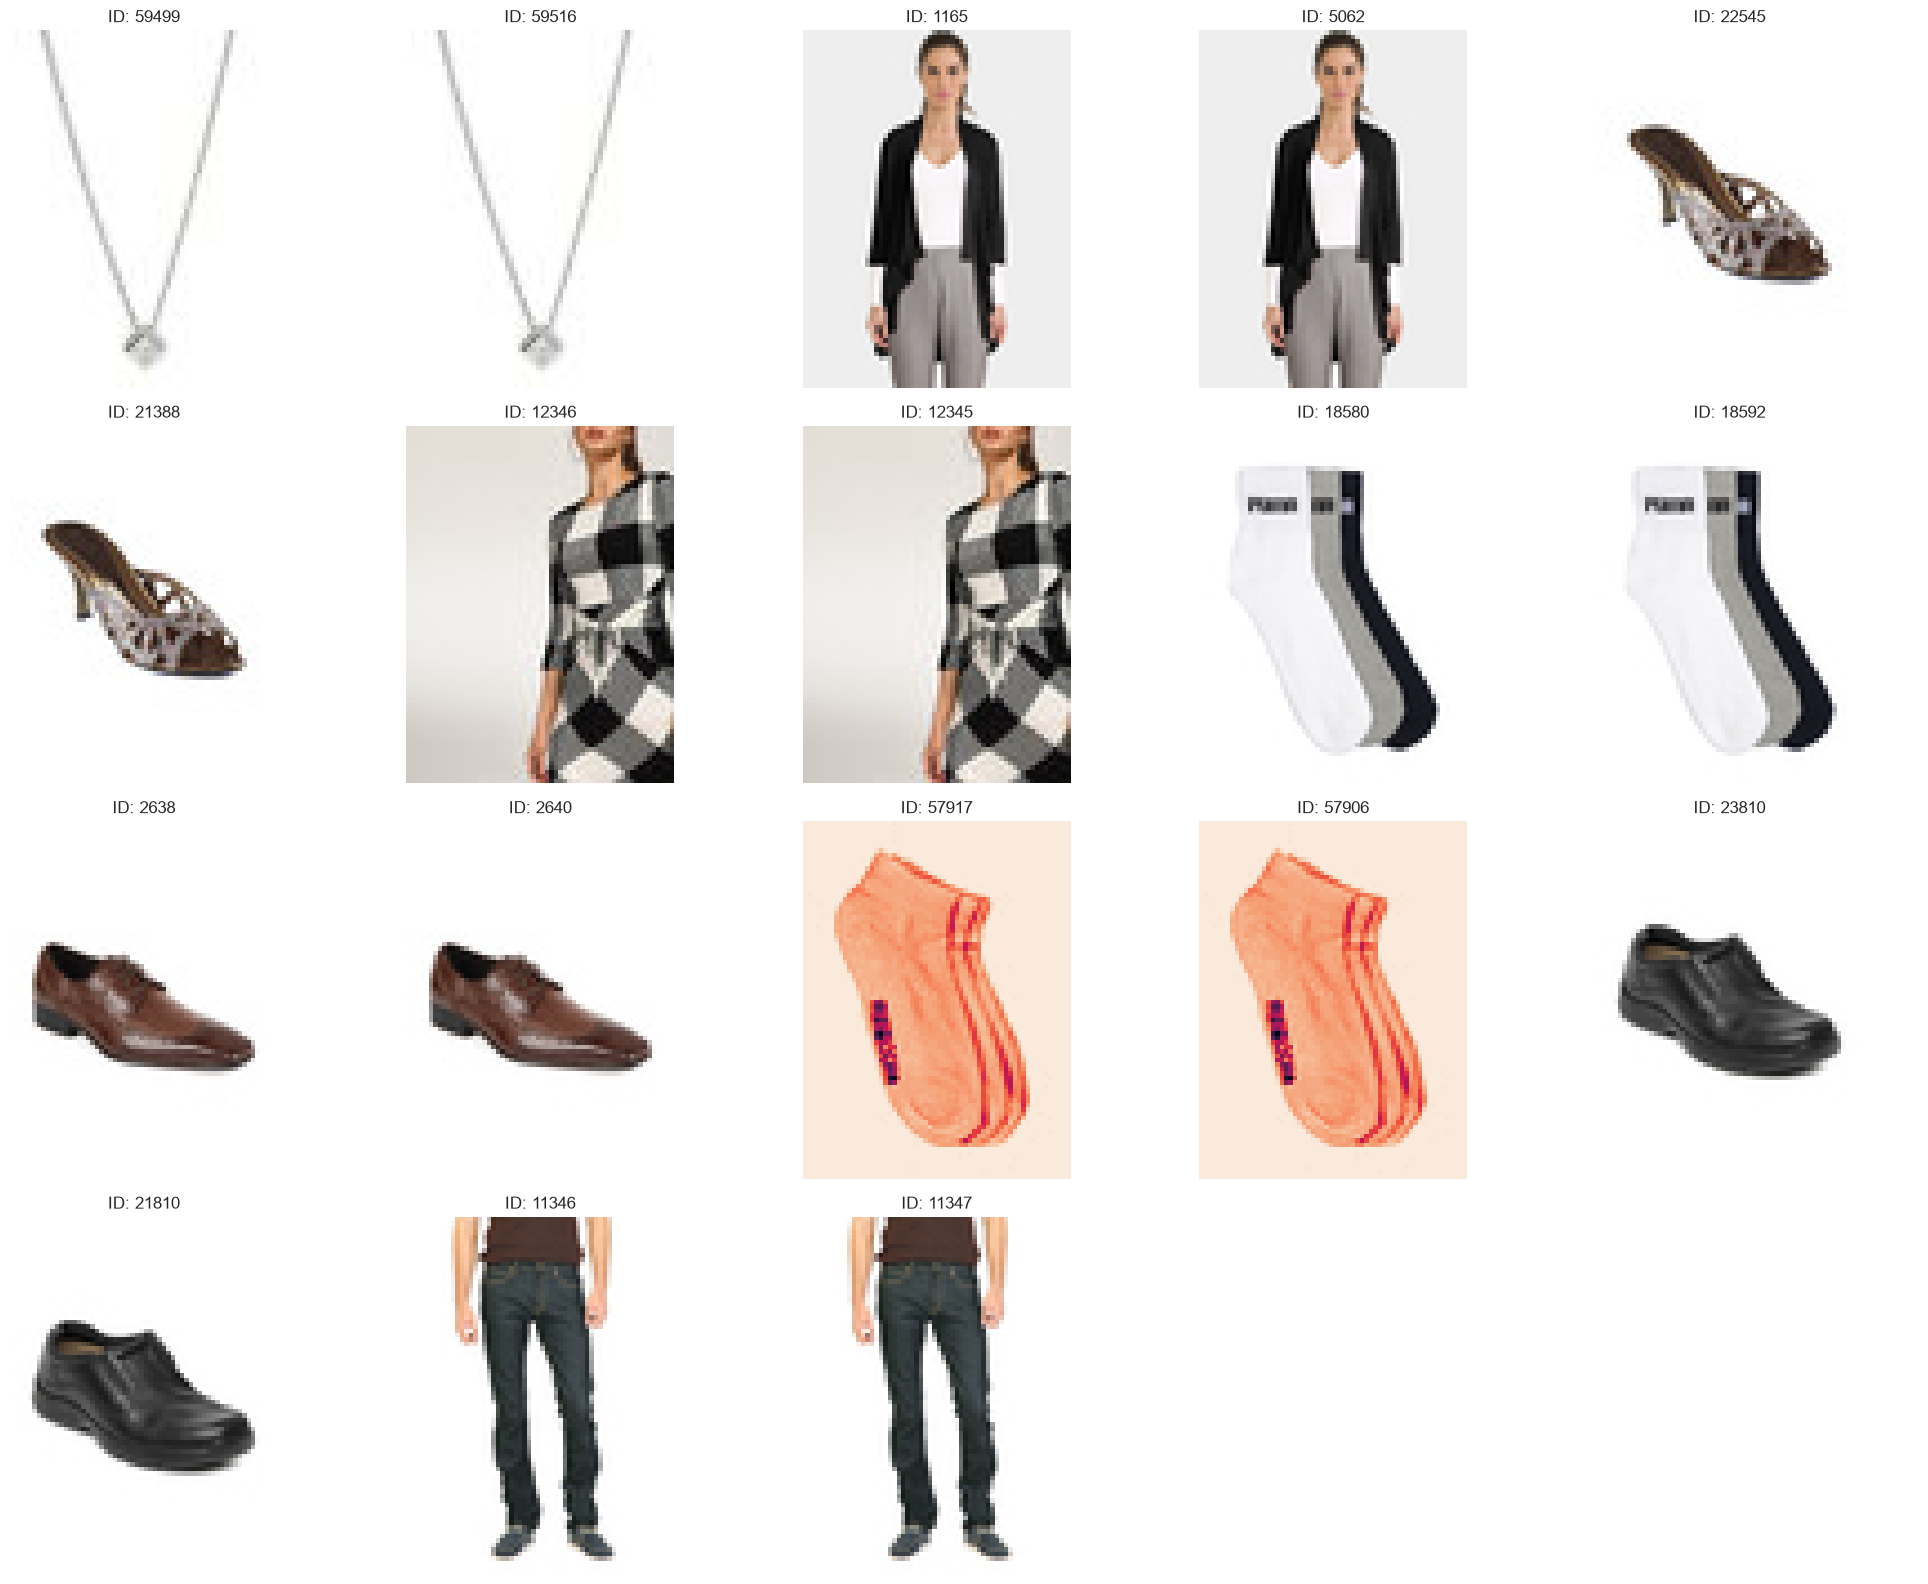

Imágenes en grupos con year conflictivo: 18 
Porcentaje sobre el dataset: 1.258%


,file_hash,id,gender,masterCategory,subCategory,articleType,baseColour,season,year,usage,productDisplayName
13,01e1fec6949cff587f3b9d7c0d9fabf4,59499,Women,Accessories,Jewellery,Pendant,Silver,Fall,2012,Casual,Lucera Silver Pendant With Chain
14,01e1fec6949cff587f3b9d7c0d9fabf4,59516,Women,Accessories,Jewellery,Pendant,Silver,Summer,2013,Casual,Lucera Silver Pendant With Chain
41,0681830b0b2c248fe2e3f3f4c419d50c,1165,Men,Apparel,Topwear,Tshirts,Blue,Summer,2013,Sports,Nike Mean Team India Cricket Jersey
42,0681830b0b2c248fe2e3f3f4c419d50c,5062,Men,Accessories,Watches,Watches,Black,Winter,2016,Casual,Being Human Men Black Dial Steel Plated Strap ...
43,072563754e872649d20634800eb40523,22545,Women,Footwear,Shoes,Heels,Gold,Winter,2012,Casual,Catwalk Women Gold Heels
44,072563754e872649d20634800eb40523,21388,Women,Footwear,Shoes,Heels,Bronze,Winter,2015,Casual,Catwalk Women Casual Bronze Heels
202,21cc7958092d05386a9e178a350016fe,12346,Women,Apparel,Topwear,Tshirts,Grey,Fall,2011,Formal,Reebok Women Grey Solid V-Neck T-shirt
201,21cc7958092d05386a9e178a350016fe,12345,Women,Apparel,Saree,Sarees,Maroon,Spring,2018,Ethnic,Xoxo Women Maroon Pure Georgette Solid Ready-t...
291,31f3846690c29a97fda51cb20d49ff34,18580,Men,Accessories,Socks,Socks,White,Summer,2010,Sports,Puma Men Sport Quarters Pack of 3 Socks
292,31f3846690c29a97fda51cb20d49ff34,18592,Men,Accessories,Socks,Socks,White,Fall,2011,Sports,Puma Men Sport Quarters Pack of 3 Socks


In [130]:
year_conflicts = variable_conflicts(duplicate_metadata, "year")
year_conflicts

**Conclusiones**

Observamos que hay varios articulos que se repiten en varias variables:

- `1165`y `50622`: Puede ser el caso más problematico porque uno de ellos está asociado a una camiseta de nike de hombre y otro a un reloj de hombre, y en la imagen se ve a una mujer. Además de discrepar `masterCategory`, `subCategory`y `articleType` también discrepan el color, la estación, el año, el uso y, por supuesto, la descripción. Este caso es candidato a que eliminemos ambos articulos.
- En el resto de casos parece que una de las especificaciones de los metadatos ncaja mejor que otro. Por ejemplo, el articulo `21810` está etiquetado como cartera siendo un zapato.
- También hay casos en los que un artículo se adapta a dos categprtias, como este último pantalon (`11346`y `11347`) que 2013 perteneció a la temporada de primavera y en 2017 a la de verano.

In [131]:
n_duplicate_images = valid_images["file_hash"].isin(duplicate_hashes.index).sum()

print(
    f"Imágenes pertenecientes a grupos duplicados: "
    f"{n_duplicate_images:,}"
)

Imágenes pertenecientes a grupos duplicados: 1,431


## <a id='toc1_3_'></a>[Análisis Univariante: Distribución de las variables](#toc0_)

Veamos el número de elementos de cada columna:

In [132]:
num_values_df_col = list(map(lambda col: (col,len(df[col].value_counts(dropna=False))), df.columns))
num_values_df_col

[('id', 44419),
 ('gender', 5),
 ('masterCategory', 7),
 ('subCategory', 45),
 ('articleType', 142),
 ('baseColour', 47),
 ('season', 4),
 ('year', 13),
 ('usage', 8),
 ('productDisplayName', 31122)]

### <a id='toc1_3_1_'></a>[Variables de baja cardinalidad](#toc0_)

In [133]:
cols_low_card = list(map(lambda cv: cv[0],(filter(lambda cv: cv[1]<10, num_values_df_col))))
cols_low_card

['gender', 'masterCategory', 'season', 'usage']

   gender  percentage
0     Men   49.848038
1   Women   41.943763
2  Unisex    4.865035
3    Boys    1.868570
4   Girls    1.474594
   masterCategory  percentage
0         Apparel   48.159571
1     Accessories   25.381031
2        Footwear   20.754632
3   Personal Care    5.409847
4      Free Items    0.236385
5  Sporting Goods    0.056282
6            Home    0.002251
   season  percentage
0  Summer   48.353182
1    Fall   25.736734
2  Winter   19.185484
3  Spring    6.724600
          usage  percentage
0        Casual   78.157995
1        Sports    9.063689
2        Ethnic    7.222135
3        Formal    5.279272
4  Smart Casual    0.150836
5         Party    0.065287
6        Travel    0.058534
7          Home    0.002251


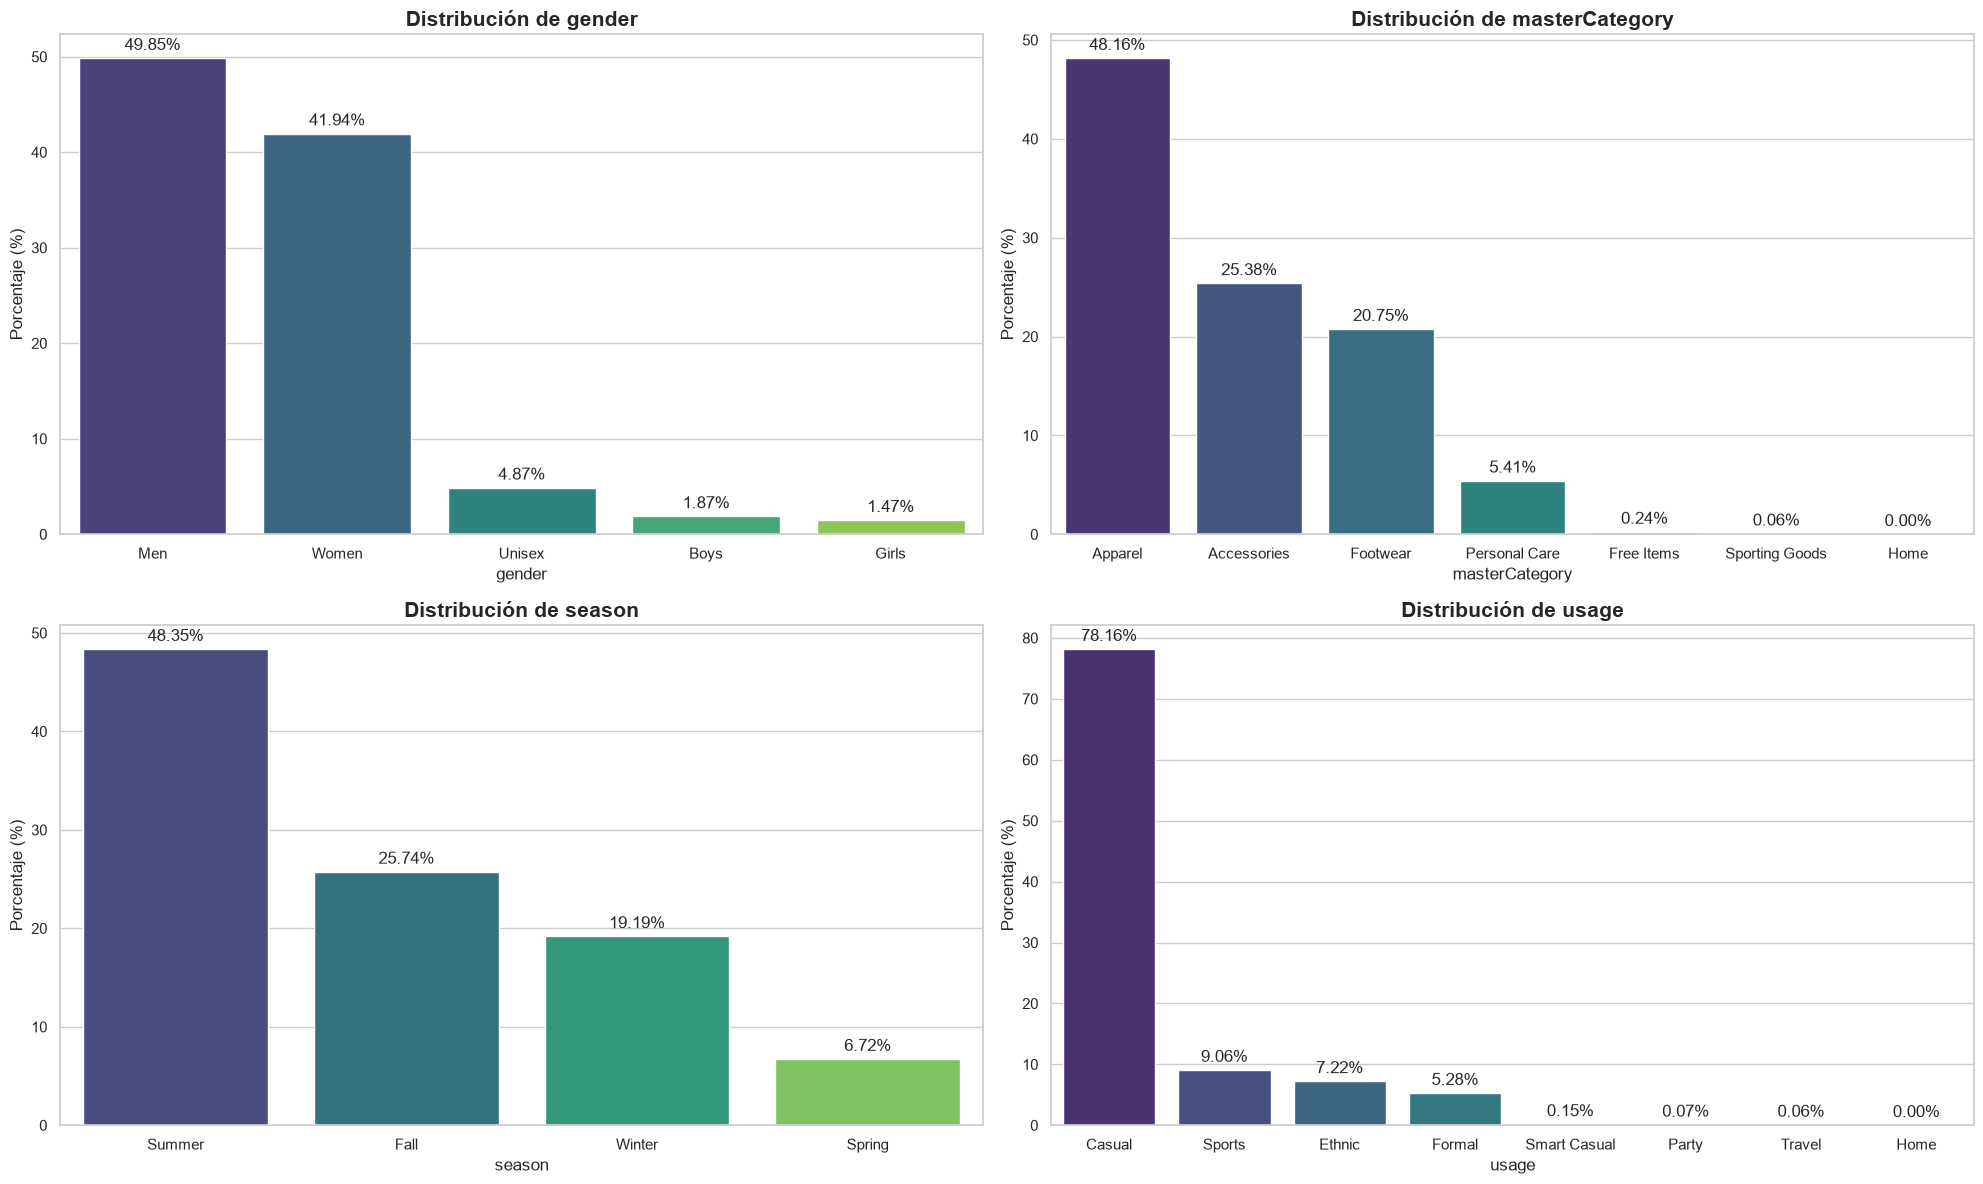

In [134]:
fig, axs = plt.subplots(2, 2, figsize=(20, 12))
axs = axs.flatten()

for i, col in enumerate(cols_low_card):
    counts = df[col].value_counts(normalize=True).mul(100).reset_index()
    counts.columns = [col, "percentage"]
    print(counts)
    
    sns.barplot(data=counts, x=col, y="percentage", ax=axs[i], hue=col, palette='viridis', legend=False)
    axs[i].set_title(f'Distribución de {col}', fontsize=15, fontweight='bold')
    axs[i].set_ylabel('Porcentaje (%)')
    
    # Añadir etiquetas de porcentaje sobre las barras
    for p in axs[i].patches:
        axs[i].annotate(f'{p.get_height():.2f}%', 
                        (p.get_x() + p.get_width() / 2., p.get_height()), 
                        ha = 'center', va = 'center', 
                        xytext = (0, 9), 
                        textcoords = 'offset points')

plt.tight_layout()
plt.show()

- `gender`: Men (50%) y Women (42%) están equilibrados, pero el 8% restante (Unisex/Other) es una clase minoritaria que podría ser mal clasificada.
- `masterCategory`: Observamos que Apparel domina con un 48% del catálogo. Esto significa que, si el modelo no es robusto, tenderá a clasificar cualquier prenda con dudas como "Apparel".
- `season`: Presenta dominancia del Verano: el 48.36% de los productos son de la temporada "Summer" mientras que solo el 6.72% corresponden a "Spring".
- `usage`: El 78.2% de los productos son de uso "Casual". "Sports" solo representa el 9.1%.

Debido a que casi 8 de cada 10 productos son casuales, la precisión simple (Accuracy) no será una métrica válida. Un modelo que diga siempre "Casual" tendría un 78% de acierto sin haber aprendido nada. Aunque este sea el caso más destacable, de forma similar ocurre lo mismo en el resto de variables.

También observamos que `masterCategory` tiene las clases "Free Items", "Sporting Goods" y "Home" con un 0.2%, 0.1% y 0.0% de presencia. Lo mismo pasa en `usage` encontramos categorías con presencia inferior a 0.5%. 
Debemos tener en cuenta esto y decidir si estas categorías son "ruido" o si el modelo de MLOps las ignorará por falta de representatividad estadística, ya que si una categoría tiene una presencia del 0.0% (como "Home" en `masterCategory`) o 0.1% (como "Travel" en `usage`), el modelo no tendrá suficientes ejemplos para aprender sus rasgos visuales. Introducir clases con 2 o 3 imágenes en un modelo de Deep Learning genera inestabilidad. Consideraremos agrupar o filtrar las clases residuales para que el modelo se centre en lo que sí puede aprender.

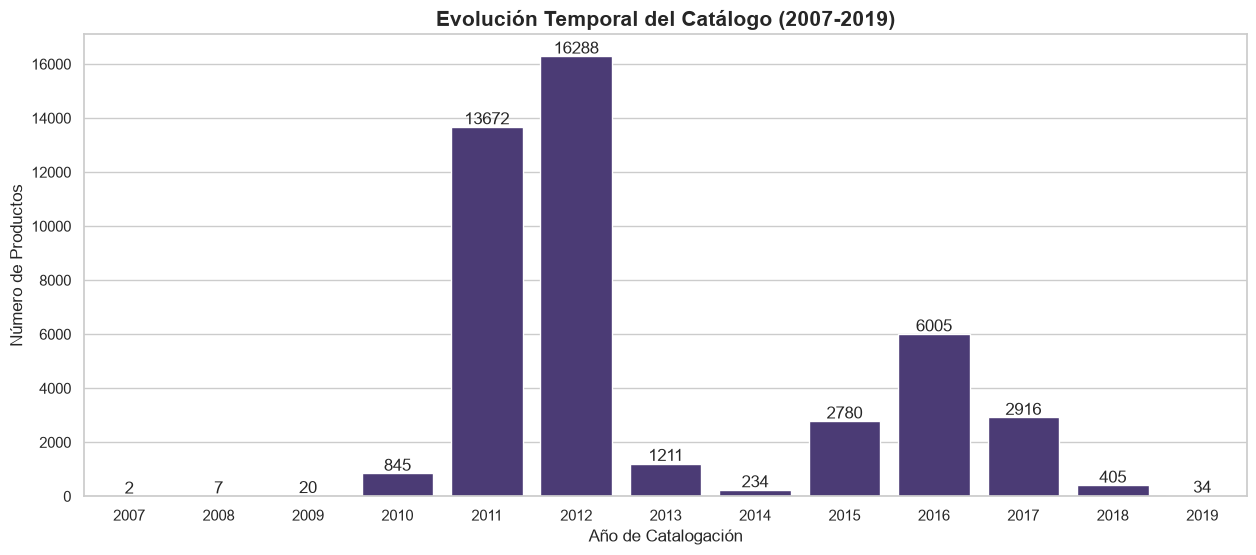

In [135]:
# Visualización de la evolución del catálogo a lo largo del tiempo
plt.figure(figsize=(15, 6))
year_counts = df['year'].value_counts().sort_index()
sns.barplot(x=year_counts.index, y=year_counts.values)

plt.title('Evolución Temporal del Catálogo (2007-2019)', fontsize=15, fontweight='bold')
plt.xlabel('Año de Catalogación')
plt.ylabel('Número de Productos')

# Añadir etiquetas de valor
for i, v in enumerate(year_counts.values):
    plt.text(i, v + 100, str(v), ha='center')

plt.show()

Observamos que la mayoria de los articulos pertenecen a los años 2011-2012. El catálogo va desde 2027 hasta 2019, la presencia de datos de 2007-2010 podría introducir "patrones obsoletos". Aún así, optamos por matener estos años para mantener el volumen de 44000 imágenes para evitar el overfitting.

### <a id='toc1_3_2_'></a>[Variables de cardinalidad alta](#toc0_)

In [136]:
cols_high_card = list(map(lambda cv: cv[0],(filter(lambda cv: cv[1]>15 and cv[1]<150, num_values_df_col))))
cols_high_card

['subCategory', 'articleType', 'baseColour']

Solo 14 categorías de 45 explican el 90.0% de los datos en 'subCategory'.


subCategory
Topwear                     34.67
Shoes                       16.53
Bags                         6.88
Bottomwear                   6.06
Watches                      5.72
Innerwear                    4.07
Jewellery                    2.43
Eyewear                      2.42
Fragrance                    2.28
Sandal                       2.17
Wallets                      2.10
Flip Flops                   2.06
Belts                        1.83
Socks                        1.57
Lips                         1.19
Dress                        1.08
Loungewear and Nightwear     1.06
Saree                        0.96
Nails                        0.74
Makeup                       0.69
Headwear                     0.66
Ties                         0.58
Accessories                  0.29
Scarves                      0.27
Cufflinks                    0.24
Apparel Set                  0.24
Free Gifts                   0.23
Stoles                       0.20
Skin Care                    0.17
Sk

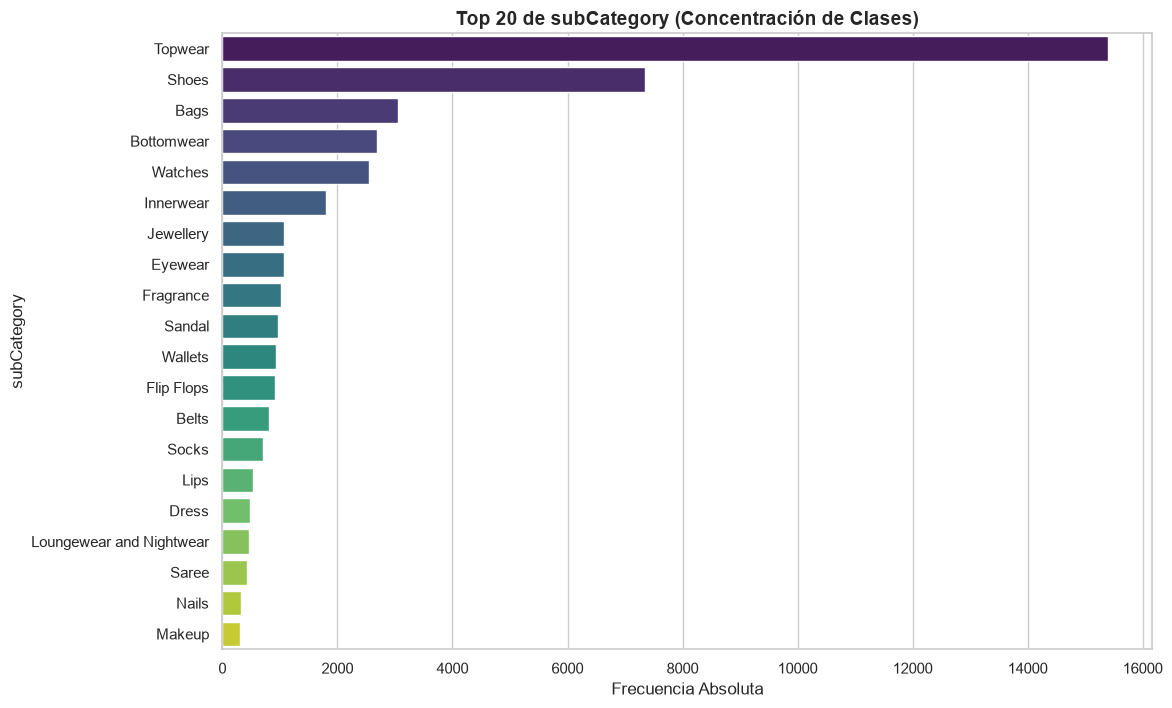

In [137]:
counts_sc, per_sc = analyze_high_cardinality(df, "subCategory")
per_sc

Solo 40 categorías de 142 explican el 90.0% de los datos en 'articleType'.


articleType
Tshirts                15.91
Shirts                  7.24
Casual Shoes            6.40
Watches                 5.72
Sports Shoes            4.58
                       ...  
Hair Accessory          0.00
Cushion Covers          0.00
Mens Grooming Kit       0.00
Body Wash and Scrub     0.00
Ipad                    0.00
Name: proportion, Length: 142, dtype: float64

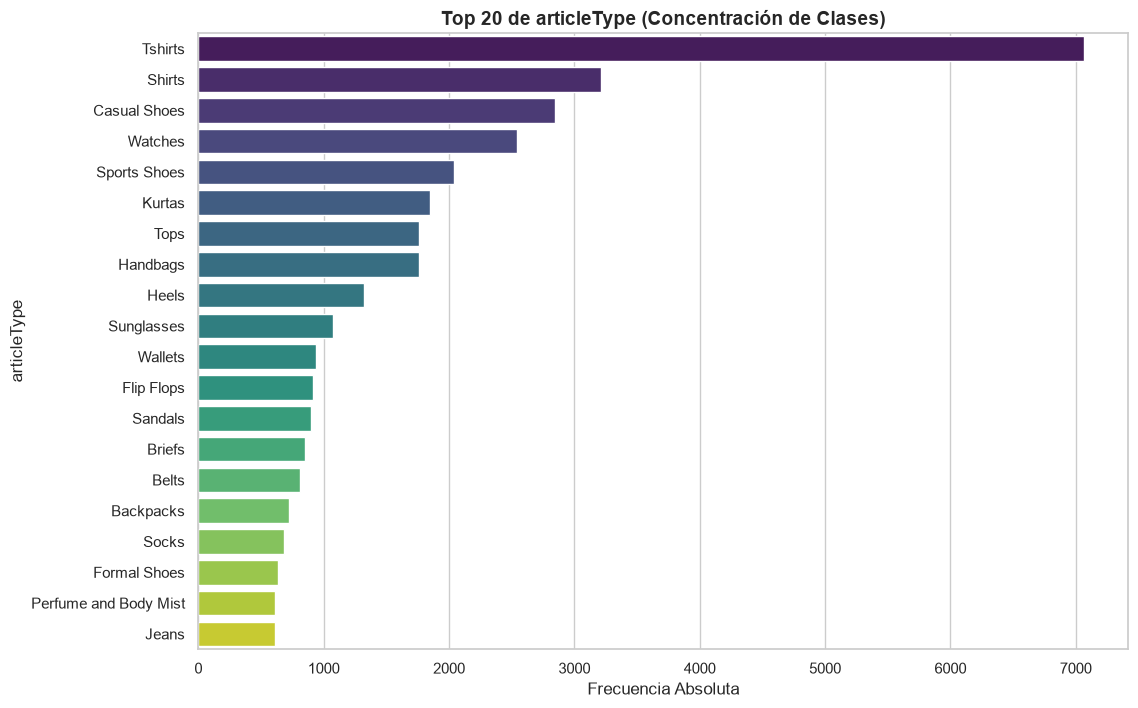

In [138]:
counts_at, per_at = analyze_high_cardinality(df, "articleType")
per_at

Aunque `articleType` proporciona una clasificación más granular y resulta interesante desde el punto de vista de la aplicación, su elevado número de clases y desbalance hacen que se plantee inicialmente `masterCategory` como problema baseline.

Solo 15 categorías de 47 explican el 90.0% de los datos en 'baseColour'.


baseColour
Black                21.90
White                12.47
Blue                 11.08
Brown                 7.87
Grey                  6.17
Red                   5.52
Green                 4.76
Pink                  4.19
Navy Blue             4.03
Purple                3.69
Silver                2.45
Yellow                1.75
Beige                 1.69
Gold                  1.42
Maroon                1.31
Orange                1.19
Olive                 0.92
Multi                 0.89
Cream                 0.88
Steel                 0.71
Charcoal              0.51
Peach                 0.44
Off White             0.41
Skin                  0.40
Lavender              0.36
Grey Melange          0.33
Khaki                 0.31
Magenta               0.29
Teal                  0.27
Tan                   0.26
Mustard               0.22
Bronze                0.21
Copper                0.19
Turquoise Blue        0.16
Rust                  0.15
Burgundy              0.10
Metallic         

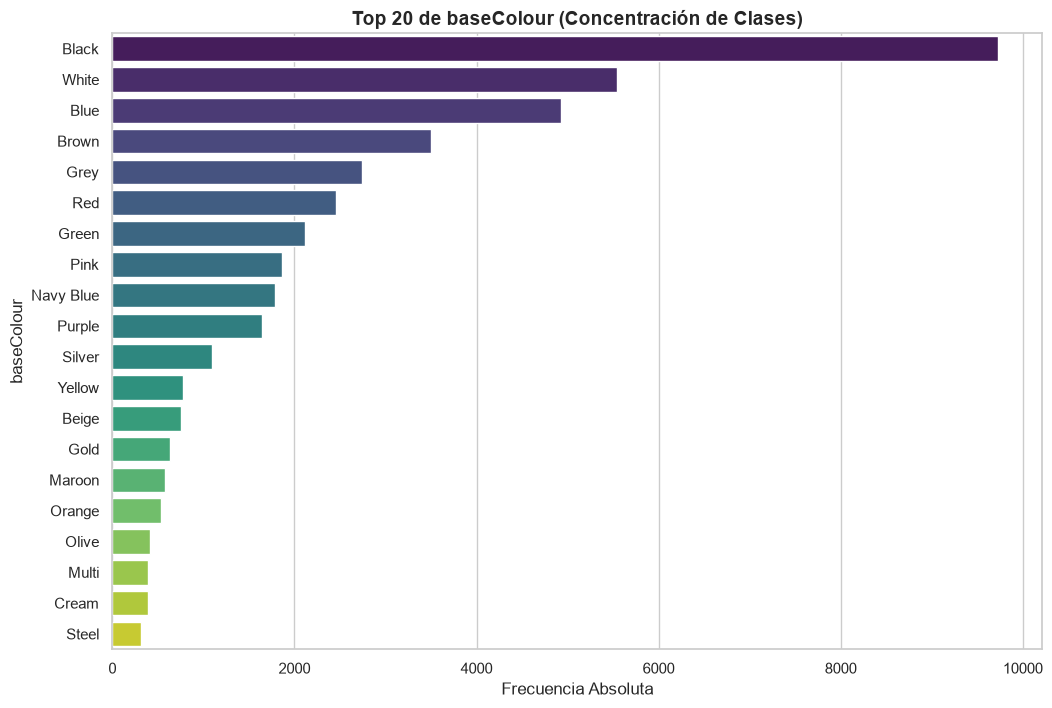

In [139]:
counts_bc, per_bc = analyze_high_cardinality(df, "baseColour")
per_bc

- `baseColour`: El color "Black" (21.9%) y "White" (12.47%) dominan el catálogo. Es decir, el catálogo tiene una "paleta conservadora". Esto es relevante porque los modelos de visión por computador (CNN) a veces confunden la categoría por el color (ej. confundir un zapato formal con uno deportivo solo porque ambos son negros)

### <a id='toc1_3_3_'></a>[Desbalance de clases](#toc0_)

In [ ]:
def report_class_imbalance(df, columns):
    """
    Análisis cuantitativo del desbalance de clases por variable
    """
    summary = []
    for col in columns:
        top_class = df[col].value_counts(normalize=True).index[0]
        top_perc = df[col].value_counts(normalize=True).iloc[0] * 100
        min_class = df[col].value_counts(normalize=True).index[-1]
        min_perc = df[col].value_counts(normalize=True).iloc[-1] * 100
        n_classes = df[col].nunique()
        
        summary.append({
            'Variable': col,
            'Nº Clases': n_classes,
            'Clase Dominante': f"{top_class} ({top_perc:.1f}%)",
            'Clase Minoritaria': f"{min_class} ({min_perc:.2f}%)"
        })
    return pd.DataFrame(summary)

# Ejecutar reporte sobre las variables clave
report_class_imbalance(df, ['masterCategory', 'subCategory', 'gender', 'usage', 'season'])

,Variable,Nº Clases,Clase Dominante,Clase Minoritaria
0,gender,5,Men (49.8%),Girls (1.47%)
1,masterCategory,7,Apparel (48.2%),Home (0.00%)
2,subCategory,45,Topwear (34.7%),Vouchers (0.00%)
3,articleType,142,Tshirts (15.9%),Ipad (0.00%)
4,baseColour,47,Black (21.9%),Gray (0.00%)
5,season,4,Summer (48.4%),Spring (6.72%)
6,year,13,2012 (36.7%),2007 (0.00%)
7,usage,8,Casual (78.2%),Home (0.00%)
8,productDisplayName,31122,Lucera Women Silver Earrings (0.2%),Fossil Women Pink Dial Chronograph Watch ES305...


El análisis univariante revela un sesgo pronunciado en la distribución de la mayoría de las variables del dataset:

1. **`usage`**: La categoría *Casual* acapara el **78.2%** de los productos, mientras que opciones como *Sports* representan el 9.1% y categorías minoritarias (*Party*, *Travel*) apenas alcanzan el 0.1%.
2. **`masterCategory`**: *Apparel* representa el **48.2%** del dataset, frente a *Personal Care* (5.4%) o clases residuales como *Free Items* o *Home* (< 0.2%).
3. **`gender`**: Mientras que *Men* (49.8%) y *Women* (41.9%) están equilibrados, las categorías *Unisex*, *Boys* y *Girls* suman en conjunto solo un 8.3%.

En datasets fuertemente desbalanceados, la exactitud global (*CCR*) resulta engañosa. Un clasificador ingenuo que prediga siempre la clase mayoritaria (*Casual*) obtendría automáticamente un **78.2% de Accuracy** sin haber aprendido a reconocer ningún rasgo visual.

**Métricas de evaluación para dataset desbalanceados**
Siguiendo las prácticas expuestas en la literatura para datasets como el nuestro:

* **Precision y Recall**: Miden el compromiso entre minimizar falsos positivos y maximizar la detección de clases minoritarias.

  $[\text{Precision} = \frac{TP}{TP + FP}, \quad \text{Recall} = \frac{TP}{TP + FN}]$

* **F1-Score (Macro F1 vs. Weighted F1)**: Definido como la media armónica entre precisión y exhaustividad.

  $[F1 = 2 \cdot \frac{\text{Precision} \cdot \text{Recall}}{\text{Precision} + \text{Recall}}]$

  En la evaluación multiclase y multietiqueta del proyecto:
  * **Macro F1**: Promedia el F1 de cada clase asignándoles el mismo peso. Es la métrica más exigente, ya que penaliza fuertemente al modelo si falla en clases minoritarias (*Home*, *Sports*, *Travel*).
  * **Weighted F1**: Pondera el F1 según el soporte de cada clase en el catálogo.
* **Curvas Precision-Recall (PR-AUC)**: Al igual que en la evaluación de modelos de riesgo ante desbalances severos, la curva Precision-Recall permitirá ajustar dinámicamente los umbrales de decisión según las necesidades del negocio en e-commerce.


## <a id='toc1_4_'></a>[Análisis Bivariante](#toc0_)

Pasamos a medir cómo la presencia de una categoría en una variable influye en la distribución de otra, utilizando matrices de probabilidad condicionada $P(B∣A)$.

Esto nos permite identificar si existen rasgos redundantes o sesgos muy marcados que el modelo de Deep Learning podría sobreaprender (por ejemplo, asociar un color siempre a una estación o un género a una categoría específica).

### <a id='toc1_4_1_'></a>[Análisis Género vs. Categoría principal ($P(masterCategory∣gender)$)](#toc0_)

Este cruce es fundamental para verificar si el dataset tiene sesgos de género en sus categorías principales. Por ejemplo, determinar si la categoría "Apparel" (48.2% del total) se distribuye de forma equitativa entre hombres y mujeres o si existen categorías exclusivas.

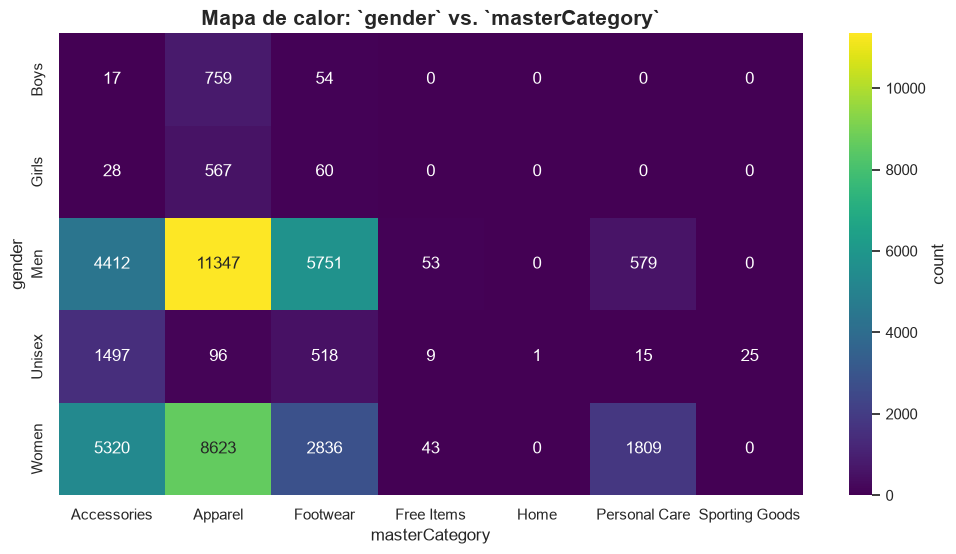

In [140]:
plot_heatmap_correlation(df, "gender", "masterCategory")

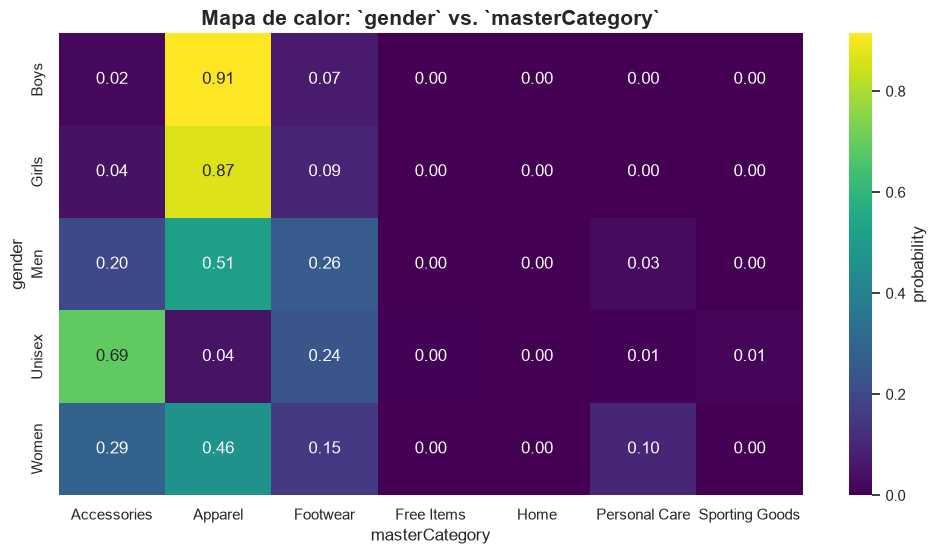

In [141]:
plot_heatmap_correlation(df, "gender", "masterCategory", normalize="index")

### <a id='toc1_4_2_'></a>[Análisis Género vs. Tipo de artículo ($P(articleType∣gender)$)](#toc0_)

Veamos dentro de cada tipo de artículo, qué porcentaje corresponde a cada género

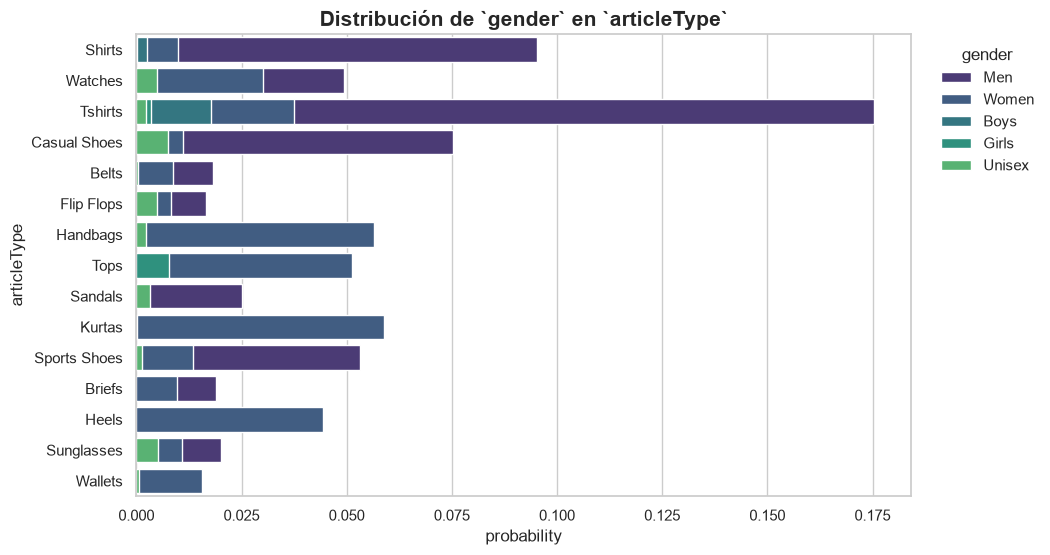

In [142]:
top_types = df['articleType'].value_counts().nlargest(15).index
df_filtered_types = df[df['articleType'].isin(top_types)]

plot_stacked_bars_correlation(df_filtered_types, 'articleType', 'gender', stat='probability')

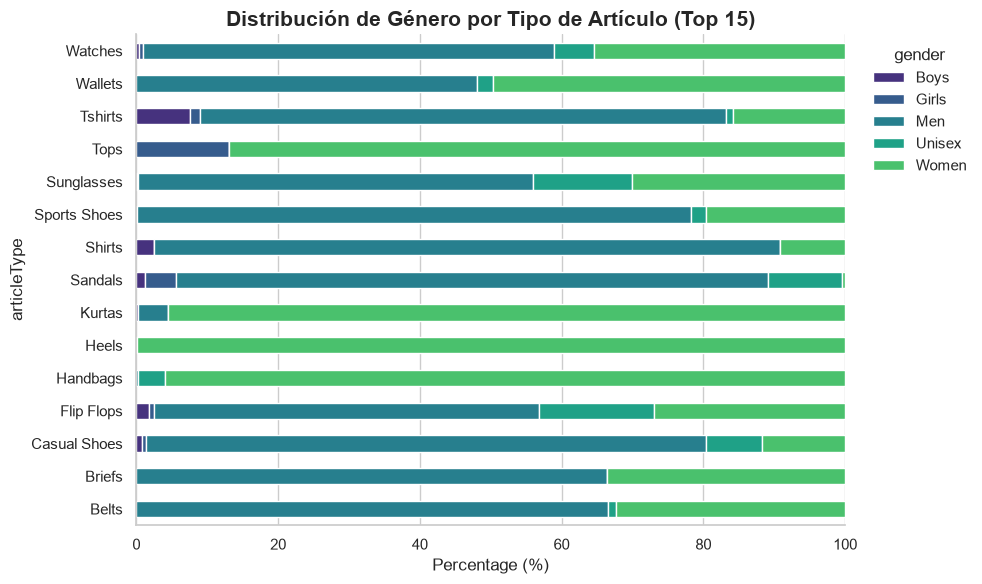

In [143]:
plot_stacked_percentage(df_filtered_types, 'articleType', 'gender', 
                        title='Distribución de Género por Tipo de Artículo (Top 15)')

### <a id='toc1_4_3_'></a>[Análisis Categoría principal vs. Uso ($P(masterCategory|usage)$)](#toc0_)


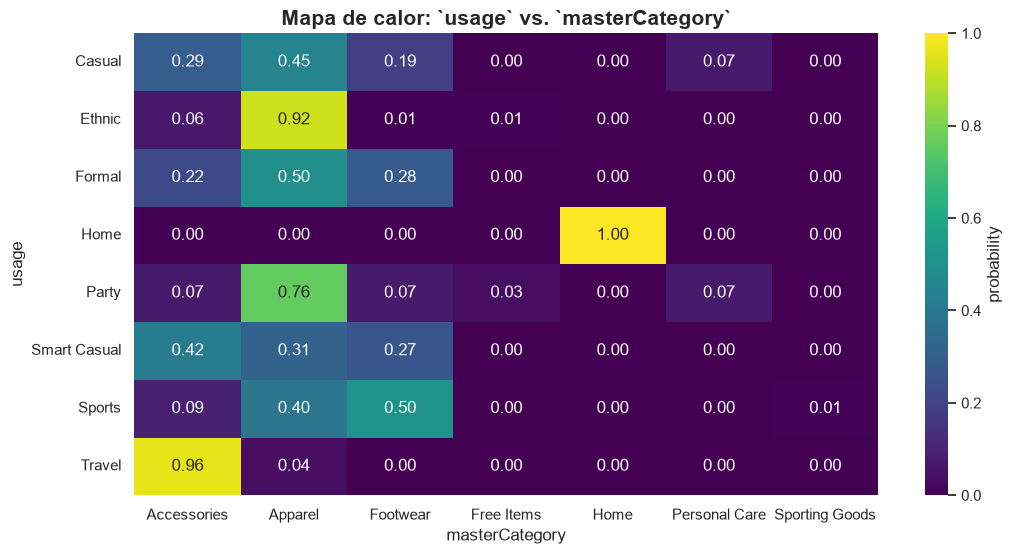

In [144]:
plot_heatmap_correlation(df, "usage", "masterCategory", normalize="index")

### <a id='toc1_4_4_'></a>[Análisis Temporada vs. Uso ($P(season|usage)$)](#toc0_)


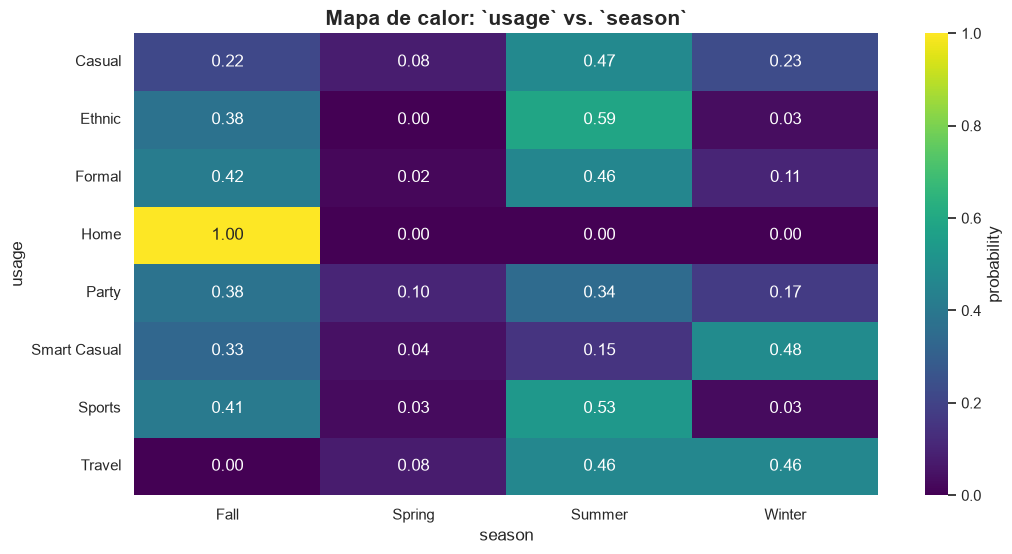

In [145]:
plot_heatmap_correlation(df, "usage", "season", normalize="index")

### <a id='toc1_4_5_'></a>[Análisis Uso vs. Tipo de Articulo ($P(usage|articleType)$)](#toc0_)


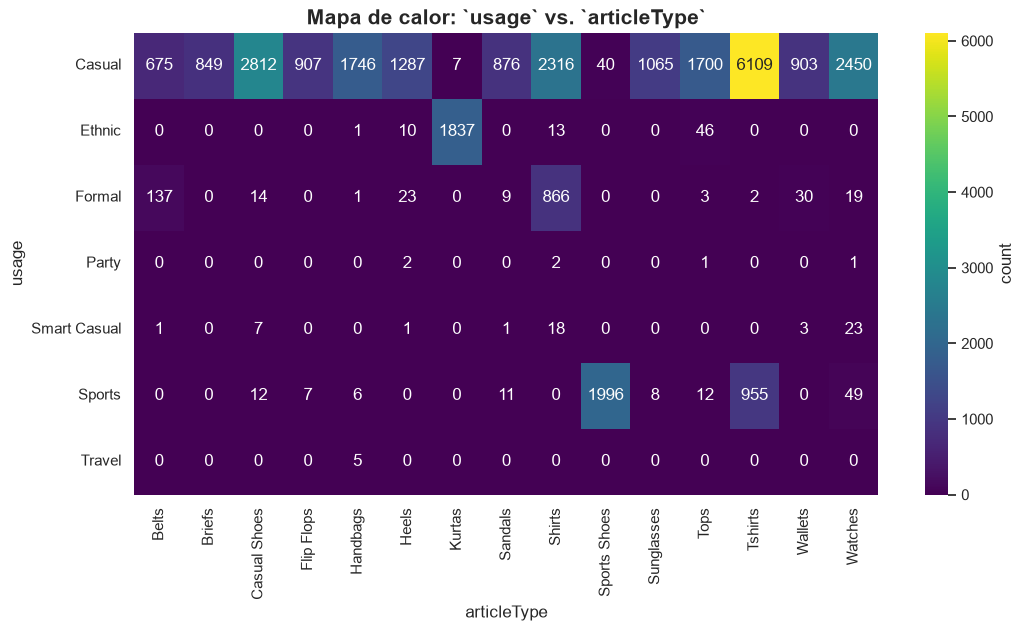

In [146]:
plot_heatmap_correlation(df_filtered_types, "usage", "articleType")

### <a id='toc1_4_6_'></a>[Análisis Color base vs. Categoría principal ($P(baseColour|masterCategory)$)](#toc0_)
(Top 15 colores, heatmap)


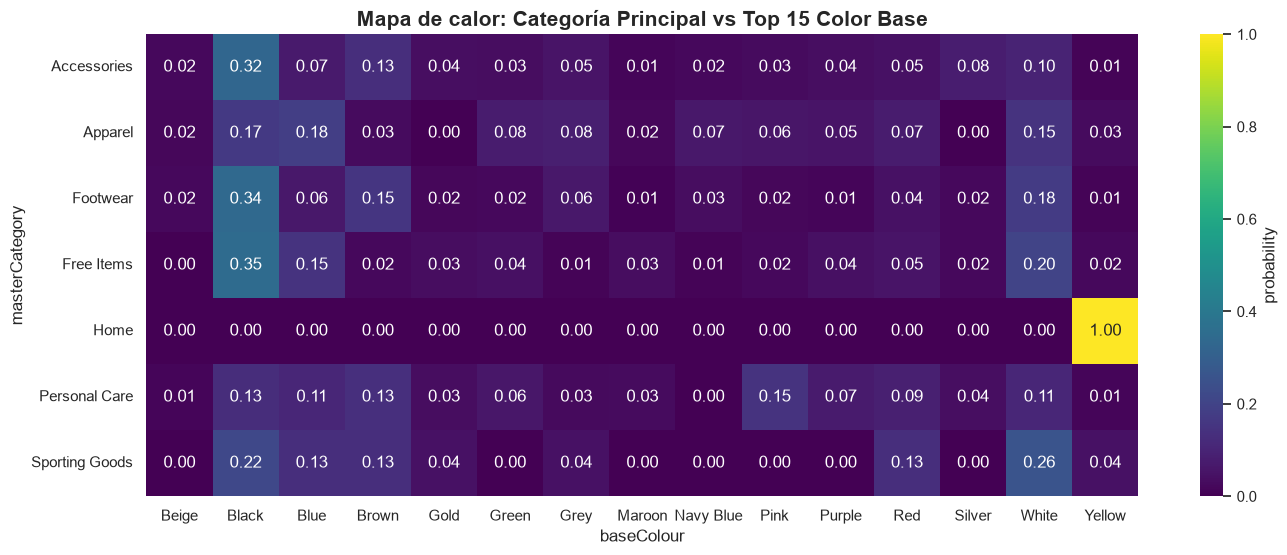

In [147]:
top_colors = df['baseColour'].value_counts().nlargest(15).index
df_filtered_colors = df[df['baseColour'].isin(top_colors)]

plot_heatmap_correlation(df_filtered_colors, "masterCategory", "baseColour", figsize=(16, 6), 
                        title='Mapa de calor: Categoría Principal vs Top 15 Color Base', normalize="index")

### <a id='toc1_4_7_'></a>[Análisis Temporada vs. Color ($P(baseColour∣season)$)](#toc0_)

Siguiendo la lógica de detección de redundancias, analizamos si el color del producto está fuertemente condicionado por la temporada. Si un color como el "Black" (21.9%) aparece casi exclusivamente en "Winter", el modelo de visión podría tener dificultades para separar rasgos cromáticos de rasgos morfológicos estacionales.

Debido a que la variable `baseColour` preesenta alta cardinalidad) filtramos los 15 colores más frecuentes para facilitar la lectura.


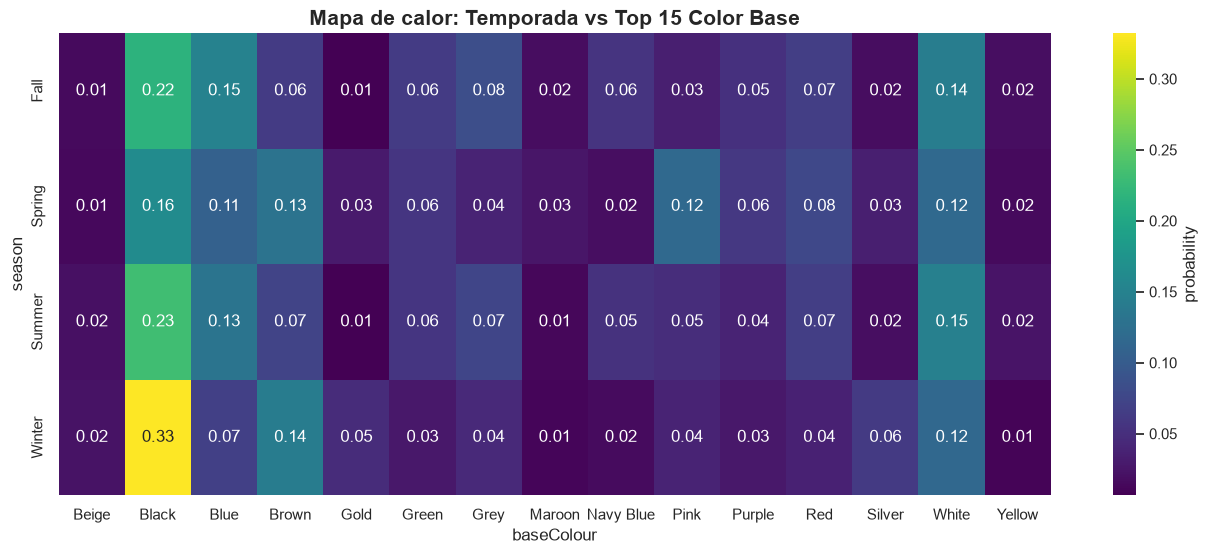

In [148]:
plot_heatmap_correlation(df_filtered_colors, "season", "baseColour", figsize=(16, 6), title='Mapa de calor: Temporada vs Top 15 Color Base', normalize="index")

## <a id='toc1_5_'></a>[Jerarquía entre `masterCategory`, `subCategory` y `articleType`](#toc0_)

### <a id='toc1_5_1_'></a>[`masterCategory x subcategory`](#toc0_)

In [149]:
hierarchy_ms = (
    df.groupby("subCategory")["masterCategory"]
    .agg(
        n_masterCategories="nunique",
        masterCategories=lambda x: ", ".join(sorted(x.unique())),
    )
    .reset_index()
    .sort_values("n_masterCategories", ascending=False)
)

hierarchy_ms

,subCategory,n_masterCategories,masterCategories
25,Perfumes,2,"Accessories, Personal Care"
33,Socks,2,"Accessories, Apparel"
0,Accessories,1,Accessories
23,Mufflers,1,Accessories
26,Sandal,1,Footwear
27,Saree,1,Apparel
28,Scarves,1,Accessories
29,Shoe Accessories,1,Accessories
30,Shoes,1,Footwear
31,Skin,1,Personal Care


In [150]:
inconsistent_ms = (
    df.groupby("subCategory")["masterCategory"]
    .nunique()
    .loc[lambda x: x > 1]
)

inconsistent_hierarchy_ms = (
    df[
        df["subCategory"].isin(inconsistent_ms.index)
    ]
    .groupby(["subCategory", "masterCategory"])
    .size()
    .reset_index(name="count")
    .sort_values(["subCategory", "count"], ascending=[True, False])
)

inconsistent_hierarchy_ms["percentage"] = (
    round(inconsistent_hierarchy_ms["count"]
    / inconsistent_hierarchy_ms.groupby("subCategory")["count"].transform("sum")
    * 100, 2)
)

inconsistent_hierarchy_ms

,subCategory,masterCategory,count,percentage
1,Perfumes,Personal Care,5,83.33
0,Perfumes,Accessories,1,16.67
2,Socks,Accessories,686,98.28
3,Socks,Apparel,12,1.72


In [151]:
total_ms = df["subCategory"].nunique()
inconsistent_count_ms = len(inconsistent_ms)

print(f"Subcategories with more than one master category: "
      f"{inconsistent_count_ms}/{total_ms} "
      f"({inconsistent_count_ms / total_ms * 100:.2f}%)")

print(f"Inconsistent subcategories: "
      f"{inconsistent_hierarchy_ms['count'].sum()}/{len(df)} "
      f"({inconsistent_hierarchy_ms['count'].sum() / len(df) * 100:.2f}%)")

print(f"Real inconsistent subcategories: "
      f"{inconsistent_hierarchy_ms.groupby('subCategory')['count'].min().sum()}/{len(df)} "
      f"({inconsistent_hierarchy_ms.groupby('subCategory')['count'].min().sum() / len(df) * 100:.2f}%)")

Subcategories with more than one master category: 2/45 (4.44%)
Inconsistent subcategories: 704/44419 (1.58%)
Real inconsistent subcategories: 13/44419 (0.03%)


La estructura jerárquica entre `masterCategory` y `subCategory` es mayoritariamente consistente. Es decir, se identificaron dos subcategorías, concretamente Perfumes y Socks, asociadas a más de una categoría principal. Este comportamiento refleja una posible ambigüedad, sin embargo, únicamente 13 registros (0,03 % del dataset) se encuentran fuera de la asociación predominante.

### <a id='toc1_5_2_'></a>[`subCategory x articleType`](#toc0_)

In [152]:
hierarchy_sa = (
    df.groupby("articleType")["subCategory"]
    .agg(
        n_subCategories="nunique",
        subCategories=lambda x: ", ".join(sorted(x.unique())),
    )
    .reset_index()
    .sort_values("n_subCategories", ascending=False)
)

hierarchy_sa

,articleType,n_subCategories,subCategories
138,Wallets,3,"Bags, Free Gifts, Wallets"
141,Wristbands,2,"Sports Accessories, Wristbands"
107,Shorts,2,"Bottomwear, Loungewear and Nightwear"
120,Swimwear,2,"Apparel Set, Bottomwear"
28,Dresses,2,"Dress, Topwear"
...,...,...,...
47,Hair Colour,1,Hair
46,Hair Accessory,1,Accessories
45,Gloves,1,Gloves
44,Free Gifts,1,Free Gifts


In [153]:
inconsistent_sa = (
    df.groupby("articleType")["subCategory"]
    .nunique()
    .loc[lambda x: x > 1]
)

inconsistent_hierarchy_sa = (
    df[
        df["articleType"].isin(inconsistent_sa.index)
    ]
    .groupby(["articleType", "subCategory"])
    .size()
    .reset_index(name="count")
    .sort_values(["articleType", "count"], ascending=[True, False])
)

inconsistent_hierarchy_sa["percentage"] = (
    round(inconsistent_hierarchy_sa["count"]
    / inconsistent_hierarchy_sa.groupby("articleType")["count"].transform("sum")
    * 100, 2)
)

inconsistent_hierarchy_sa

,articleType,subCategory,count,percentage
0,Backpacks,Bags,722,99.72
1,Backpacks,Free Gifts,2,0.28
2,Belts,Belts,810,99.63
3,Belts,Topwear,3,0.37
4,Body Lotion,Bath and Body,5,83.33
5,Body Lotion,Skin,1,16.67
6,Clutches,Bags,289,99.66
7,Clutches,Free Gifts,1,0.34
8,Dresses,Dress,462,99.57
9,Dresses,Topwear,2,0.43


In [154]:
hierarchy_sa_summary = (
    inconsistent_hierarchy_sa
    .groupby("articleType")
    .agg(
        total=("count", "sum"),
        dominant_count=("count", "max"),
        dominant_percentage=("percentage", "max")
    )
)

hierarchy_sa_summary["inconsistent_count"] = hierarchy_sa_summary["total"] - hierarchy_sa_summary["dominant_count"]

hierarchy_sa_summary["inconsistent_percentage"] = round(100 - hierarchy_sa_summary["dominant_percentage"], 2)

hierarchy_sa_summary.sort_values(
    "inconsistent_percentage",
    ascending=False
)

,total,dominant_count,dominant_percentage,inconsistent_count,inconsistent_percentage
articleType,,,,,
Wristbands,7,4,57.14,3,42.86
Water Bottle,11,7,63.64,4,36.36
Eyeshadow,42,28,66.67,14,33.33
Swimwear,17,13,76.47,4,23.53
Messenger Bag,44,34,77.27,10,22.73
Face Scrub and Exfoliator,5,4,80.00,1,20.00
Body Lotion,6,5,83.33,1,16.67
Kajal and Eyeliner,102,86,84.31,16,15.69
Face Moisturisers,61,54,88.52,7,11.48


In [155]:

total_sa = df["articleType"].nunique()
inconsistent_count_sa = len(inconsistent_sa)
inconsistent_real_sa = inconsistent_hierarchy_sa.groupby('articleType')['count'].min().sum()

print(f"Article types with more than one subcategory: "
      f"{inconsistent_count_sa}/{total_sa} "
      f"({inconsistent_count_sa / total_sa * 100:.2f}%)"
)

print(f"Inconsistent article types: "
      f"{inconsistent_hierarchy_sa['count'].sum()}/{len(df)} "
      f"({inconsistent_hierarchy_sa['count'].sum() / len(df) * 100:.2f}%)")

print(f"Real inconsistencies article types: "
      f"{inconsistent_real_sa}/{len(df)} "
      f"({inconsistent_real_sa / len(df) * 100:.2f}%)")


Article types with more than one subcategory: 25/142 (17.61%)
Inconsistent article types: 15810/44419 (35.59%)
Real inconsistencies article types: 92/44419 (0.21%)


El análisis de las relaciones entre `masterCategory`, `subCategory` y `articleType` muestra que el conjunto de datos presenta una estructura jerárquica definida. Aunque algunas categorías aparecen asociadas a más de una categoría del nivel superior, la mayoría de estas asociaciones alternativas son minoritarias. Al considerar únicamente los registros que no siguen la relación predominante, las inconsistencias representan solo el 0,03 % de los registros en la relación entre `subCategory` y `masterCategory` y el 0,21 % en la relación entre `articleType` y `subCategory`. Por tanto, la taxonomía puede considerarse prácticamente jerárquica y determinista, lo que permite interpretar `masterCategory`, `subCategory` y `articleType` como distintos niveles de granularidad de la clasificación de productos.

In [156]:
hierarchy = (
    df.groupby(
        ["masterCategory", "subCategory", "articleType"]
    )
    .size()
    .reset_index(name="count")
    .sort_values(
        ["masterCategory", "subCategory", "count"],
        ascending=[True, True, False]
    )
)

hierarchy

,masterCategory,subCategory,articleType,count
0,Accessories,Accessories,Accessory Gift Set,97
4,Accessories,Accessories,Travel Accessory,15
3,Accessories,Accessories,Messenger Bag,10
5,Accessories,Accessories,Water Bottle,4
2,Accessories,Accessories,Key chain,2
...,...,...,...,...
162,Personal Care,Skin Care,Mask and Peel,1
163,Personal Care,Skin Care,Mens Grooming Kit,1
166,Sporting Goods,Sports Equipment,Basketballs,13
167,Sporting Goods,Sports Equipment,Footballs,8
